In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [2]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def load_txt_file(rootpath, model_name):
    txt_path = os.path.join(rootpath, model_name, "scores.txt")
    if not os.path.exists(txt_path):
        raise FileNotFoundError(f"File not found: {txt_path}")

    scores = []
    labels = []
    with open(txt_path, 'r') as fh:
        for line in fh:
            parts = line.strip().split()
            if len(parts) != 3:
                continue  # skip malformed lines

            _, score, label = parts
            score = score.strip("[]")
            scores.append(float(score))
            labels.append(int(label))

    scores = np.array(scores)
    labels = np.array(labels)
    return scores, labels

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    #eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]

    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    
def plot_scores_distribution(scores, labels):
    # Split real/fake
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    print(f"Loaded {len(scores)} samples")
    print(f"Real mean score: {real_scores.mean():.4f}")
    print(f"Fake mean score: {fake_scores.mean():.4f}\n")

    # Plot
    plt.figure(figsize=(6, 4))
    plt.hist(real_scores, bins=100, alpha=0.5, density=True)
    plt.hist(fake_scores, bins=100, alpha=0.5, density=True)
    plt.xlabel("Score")
    plt.ylabel("Density")
    plt.title(f"Score Distribution")
    plt.legend(["Real (0)", "Fake (1)"])
    plt.show()

def plot_expert_stats(rootpath,
                      model_name,
                      stat="gating",
                      expert_labels=None):

    base_path = os.path.join(rootpath, model_name)

    global_path = os.path.join(base_path, f"{stat}_mean_global.npy")
    real_path   = os.path.join(base_path, f"{stat}_mean_real.npy")
    spoof_path  = os.path.join(base_path, f"{stat}_mean_fake.npy")

    global_w = np.load(global_path).flatten()
    real_w   = np.load(real_path).flatten()
    spoof_w  = np.load(spoof_path).flatten()

    if expert_labels is not None:
        n_experts = len(expert_labels)
        if len(global_w) != n_experts:
            raise ValueError(
                f"Mismatch: loaded stats have {len(global_w)} experts "
                f"but expert_labels has {n_experts}")
    else:
        n_experts = len(global_w)
        expert_labels = [f"E{i}" for i in range(n_experts)]

    fig, axes = plt.subplots(1, 3, figsize=(4*n_experts/2 + 6, 4), sharey=True)

    if stat == "gating":
        fig.suptitle("Gating Weights")
    elif stat == "weighted":
        fig.suptitle("Gating × Expert Logits")
    else:
        fig.suptitle("Expert Logits")

    titles = ["Avg global", "Avg real", "Avg fake"]
    data   = [global_w, real_w, spoof_w]
    colors = ["blue", "pink", "green"]

    for ax, weights, title, color in zip(axes, data, titles, colors):
        ax.bar(range(n_experts), weights, color=color)
        ax.set_title(title)
        ax.set_xticks(range(n_experts))
        ax.set_xticklabels(expert_labels, rotation=45)
        if stat == 'gating':
           ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Value")

    plt.tight_layout()
    plt.show()

    return data


In [3]:
def compute_res_and_plot(rootpath, model_name, expert_labels, distr=False, plot=True):
    scores, labels = load_txt_file(rootpath, model_name)
    
    print("\nIndividual Experts' Performance:")
    experts_scores = np.load(os.path.join(rootpath, model_name, "expert_all.npy"))
    for i in range(experts_scores.shape[1]):
        print_metrics(experts_scores[:, i], labels)    
    print("\nMoE Performance:")
    print_metrics(scores, labels)

    if distr:
        plot_scores_distribution(scores, labels)
        
    if plot:
        out_e = plot_expert_stats(rootpath, model_name, stat= 'expert', expert_labels=expert_labels)
        out_g = plot_expert_stats(rootpath, model_name, stat= 'gating', expert_labels=expert_labels)
        out_w = plot_expert_stats(rootpath, model_name, stat= 'weighted', expert_labels=expert_labels)
        return out_e, out_g, out_w

# Best model @ Friday 6 March
- Frozen pre-trained experts
- BCE + Attr Loss [1 0.2]
- 50 epochs + early stopping
- Best checkpoint criterion: lowest EER on val set
- Gate WiFS, no temperature, learned linear rescaling of expert logits
- LR from 1e-3 to 1e-5, Cosine Annealing, stable convergence

## Overall performance


Individual Experts' Performance:
AUC: 42.34%, EER: 55.89%
AUC: 32.28%, EER: 62.76%
AUC: 52.68%, EER: 50.02%
AUC: 77.23%, EER: 30.35%
AUC: 82.19%, EER: 25.04%

MoE Performance:
AUC: 78.83%, EER: 28.99%
Loaded 19171 samples
Real mean score: -3.9100
Fake mean score: 3.2087



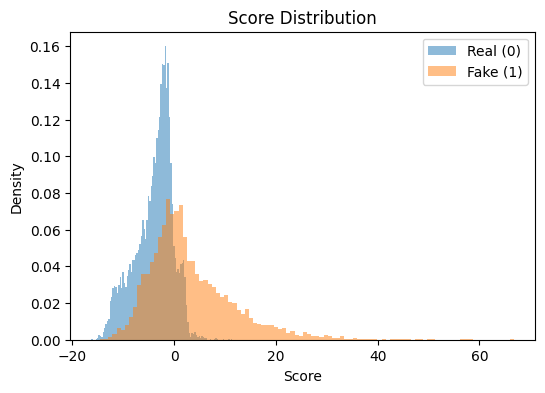

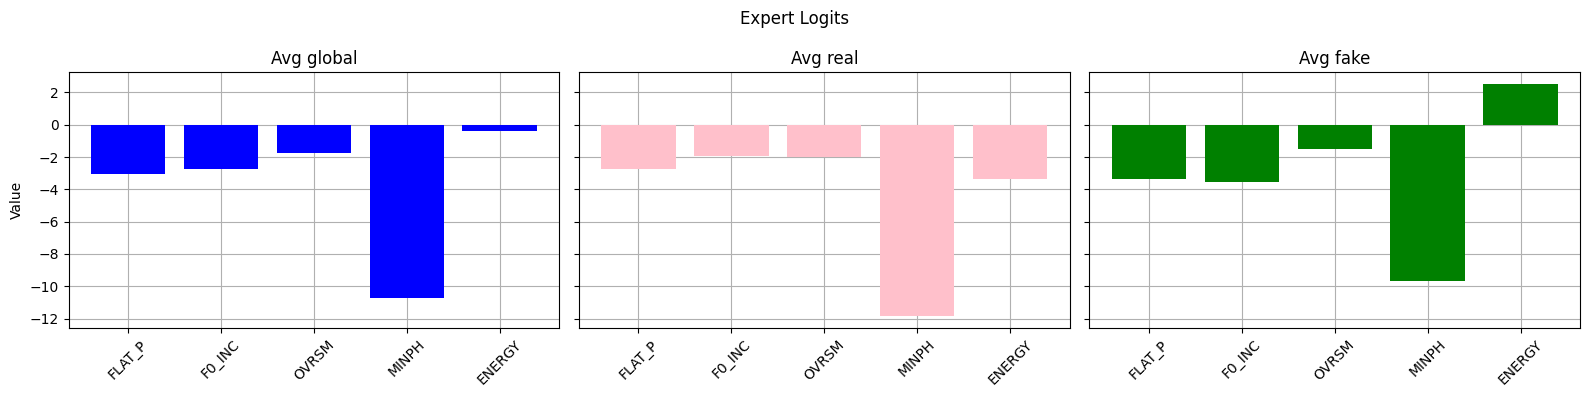

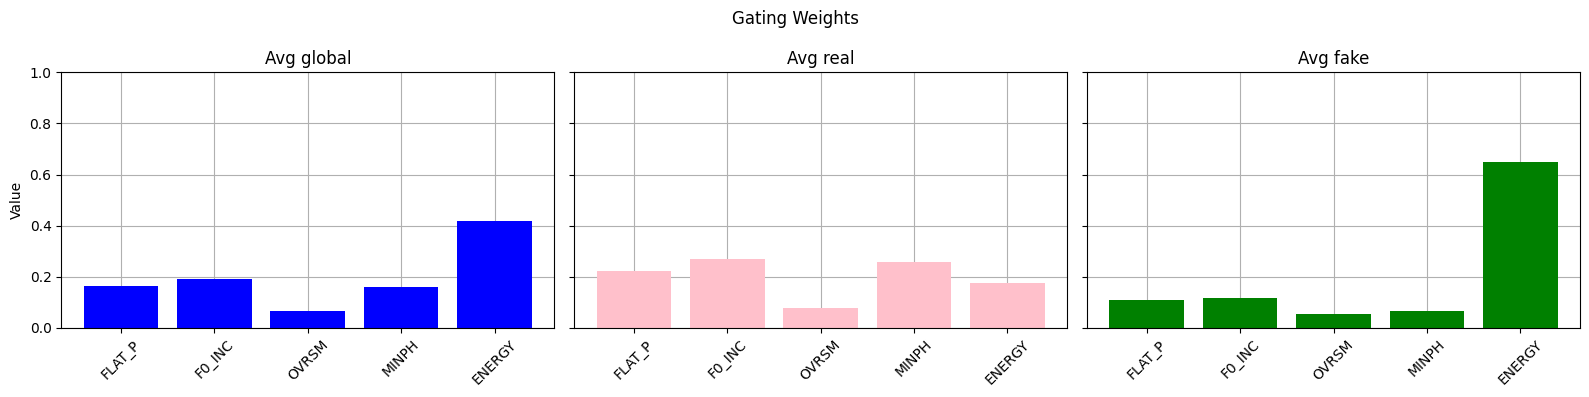

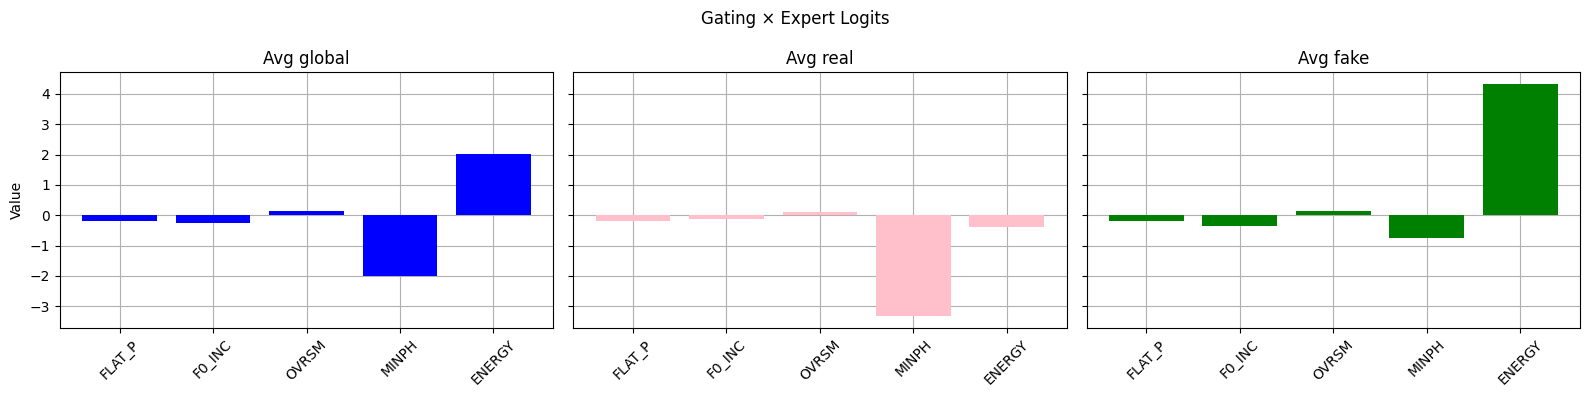

In [40]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv19/TargetCheck/ALL"
model_name = "frozen_5_exp_new_calib_fixed"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

## Per generator performance
[INDIVIDUAL EXPERT RESULTS WITHIN MOE SHOULD MATCH RESULTS FROM INDIVIDUAL EXPERT EVALUTION]

A01

Individual Experts' Performance:
AUC: 57.62%, EER: 44.21%
AUC: 38.02%, EER: 59.30%
AUC: 79.52%, EER: 30.20%
AUC: 73.13%, EER: 33.44%
AUC: 79.96%, EER: 25.29%

MoE Performance:
AUC: 82.56%, EER: 24.76%


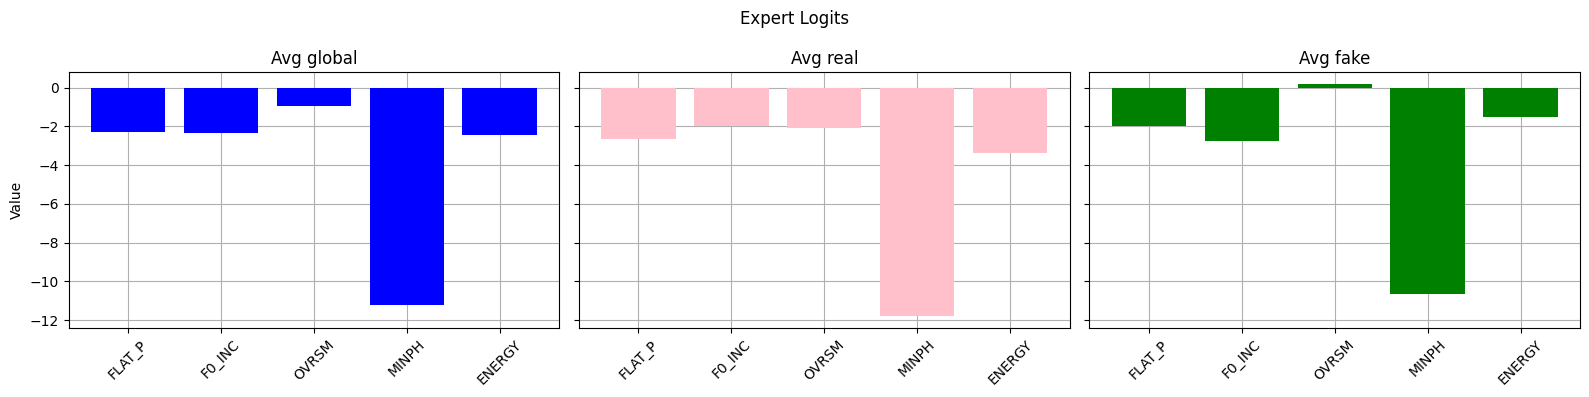

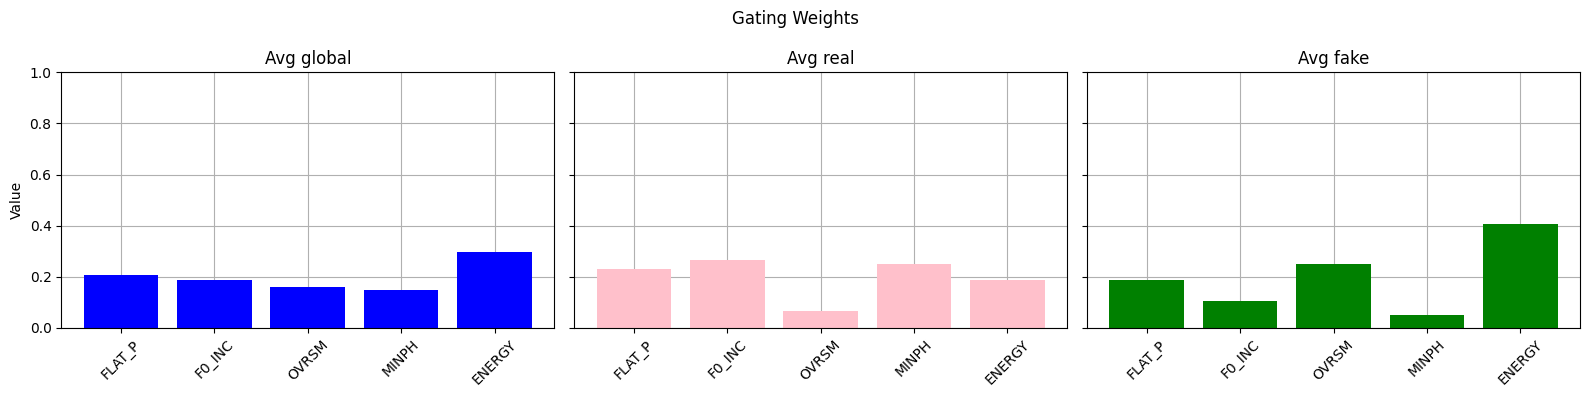

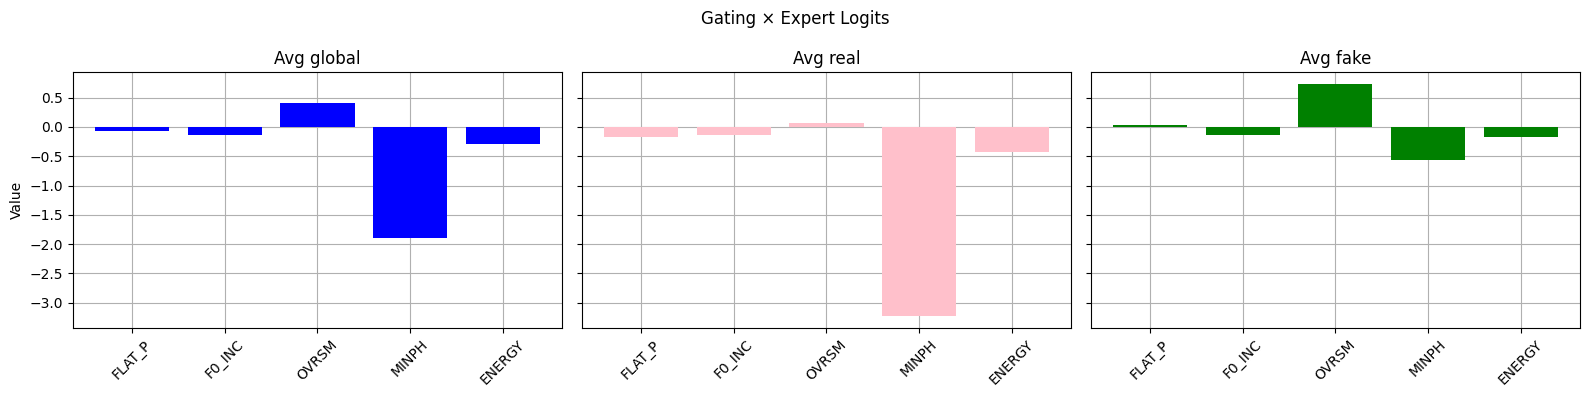

-----------------------------------
A02

Individual Experts' Performance:
AUC: 30.83%, EER: 63.45%
AUC: 16.08%, EER: 75.13%
AUC: 66.08%, EER: 39.49%
AUC: 72.41%, EER: 34.75%
AUC: 71.92%, EER: 32.28%

MoE Performance:
AUC: 68.78%, EER: 38.07%


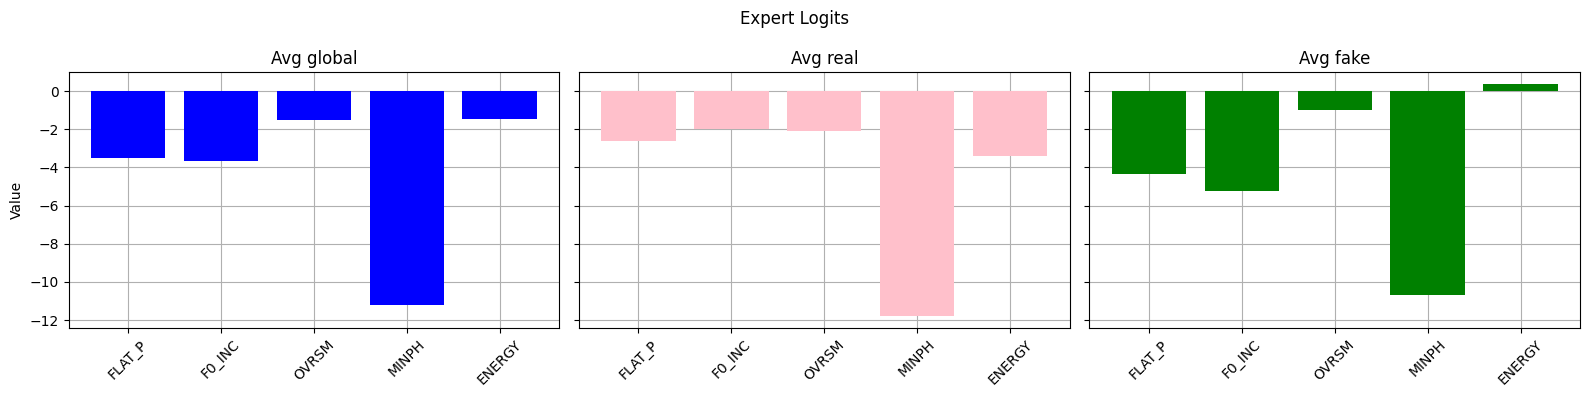

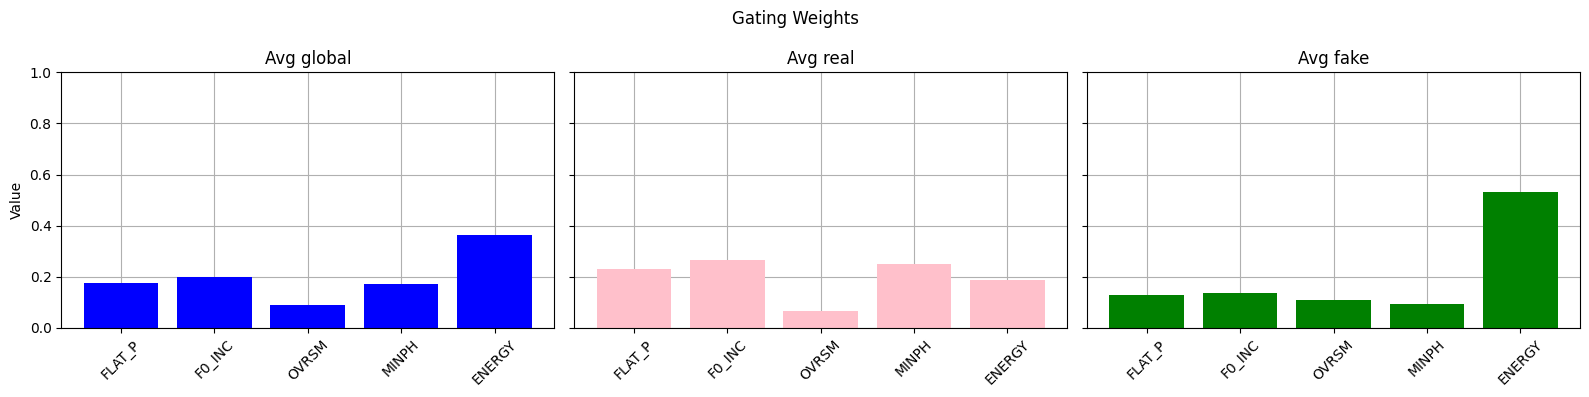

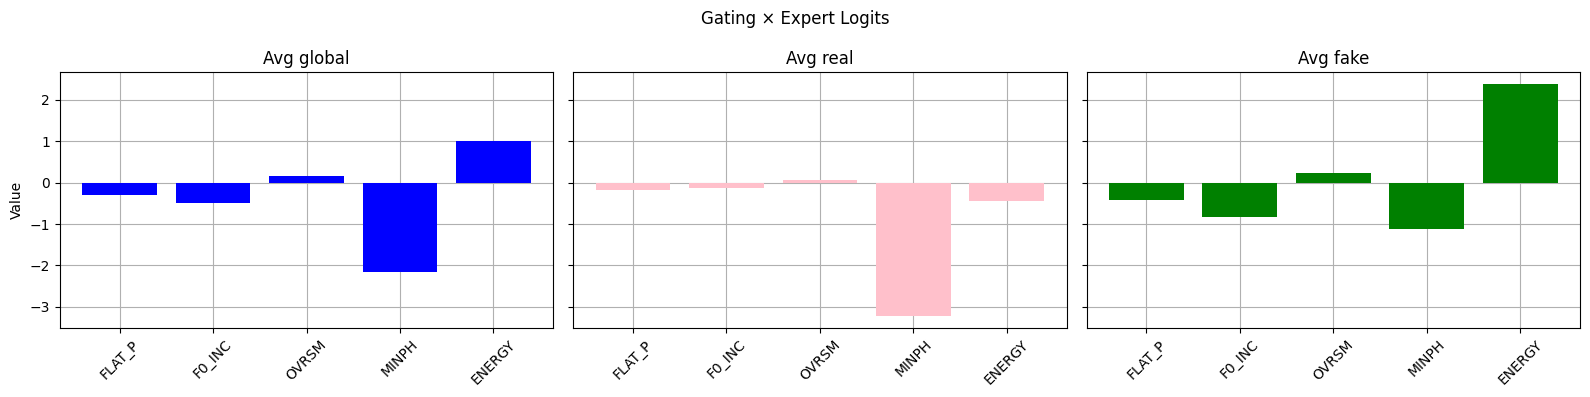

-----------------------------------
A03

Individual Experts' Performance:
AUC: 39.10%, EER: 58.45%
AUC: 22.04%, EER: 70.35%
AUC: 63.72%, EER: 40.51%
AUC: 88.08%, EER: 20.00%
AUC: 96.54%, EER: 9.14%

MoE Performance:
AUC: 92.78%, EER: 13.92%


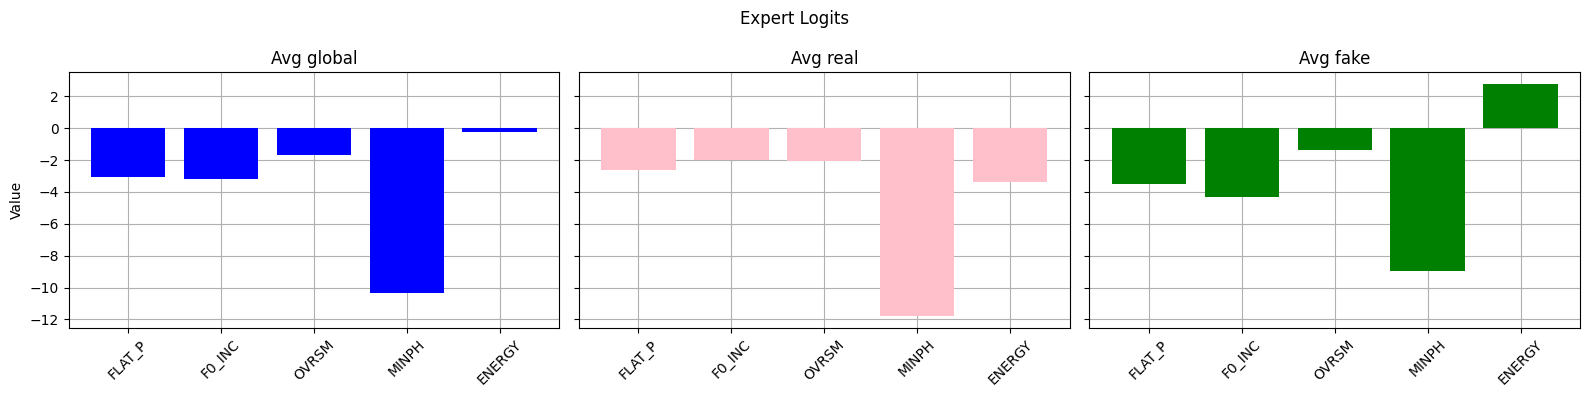

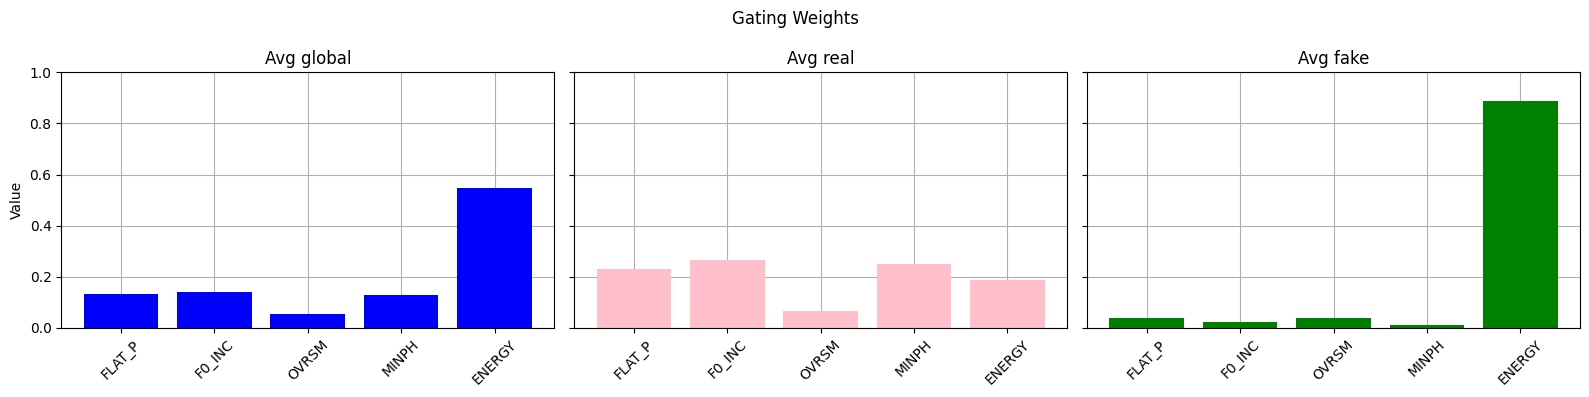

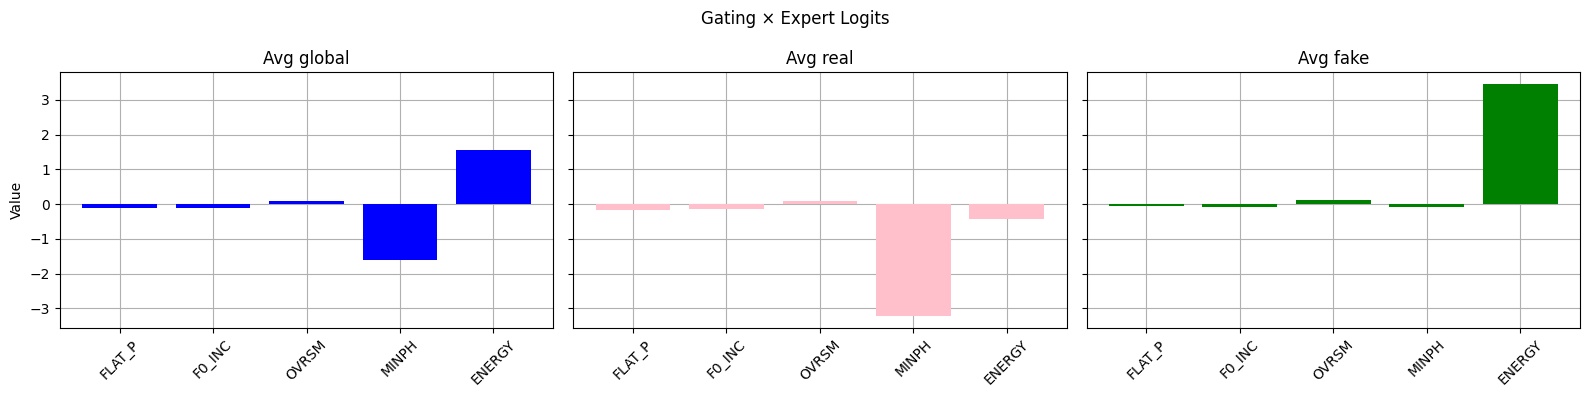

-----------------------------------
A04

Individual Experts' Performance:
AUC: 56.84%, EER: 45.48%
AUC: 77.23%, EER: 30.46%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 89.75%, EER: 19.06%

MoE Performance:
AUC: 89.23%, EER: 21.51%


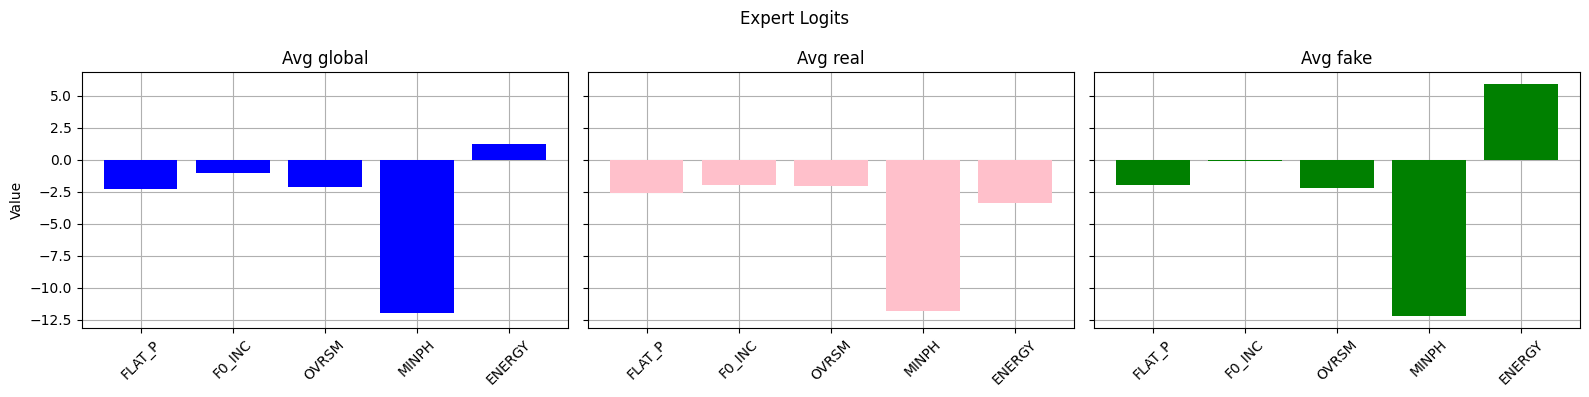

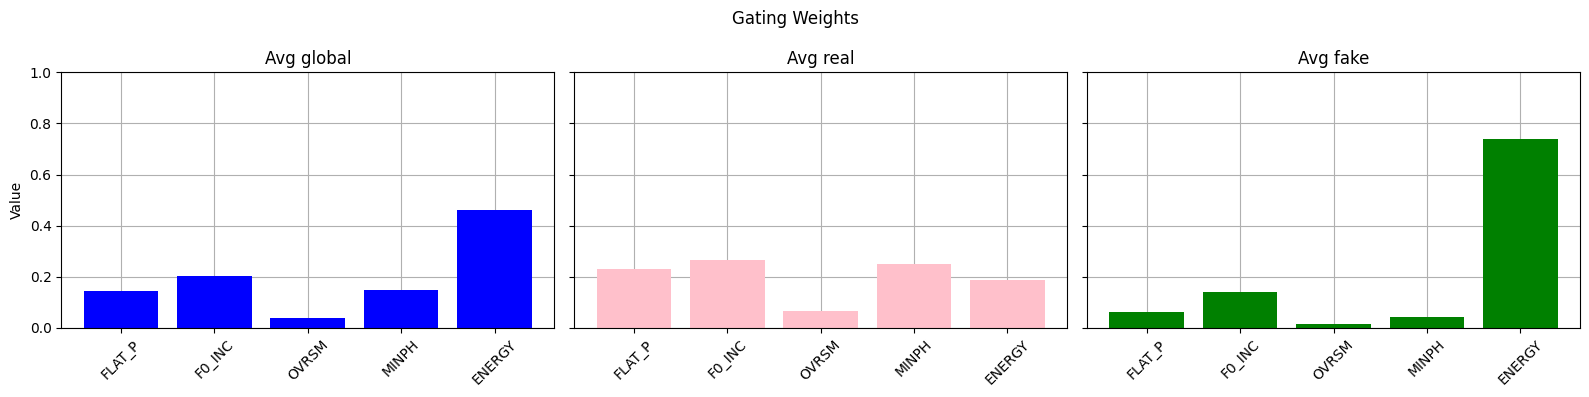

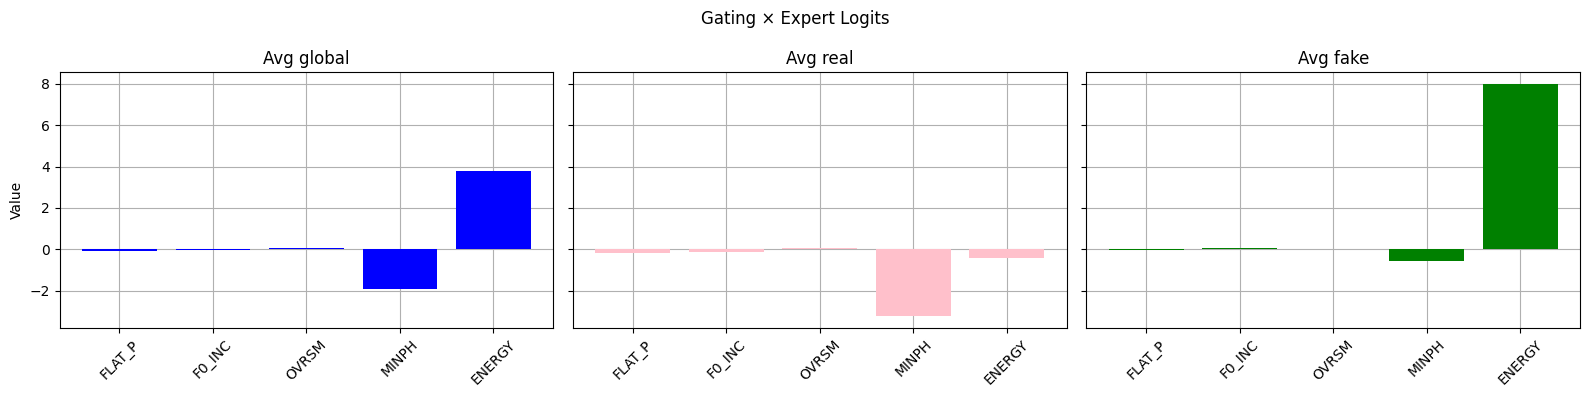

-----------------------------------
A07

Individual Experts' Performance:
AUC: 28.99%, EER: 64.61%
AUC: 13.25%, EER: 78.18%
AUC: 38.91%, EER: 58.76%
AUC: 83.97%, EER: 24.02%
AUC: 63.86%, EER: 38.74%

MoE Performance:
AUC: 45.50%, EER: 56.64%


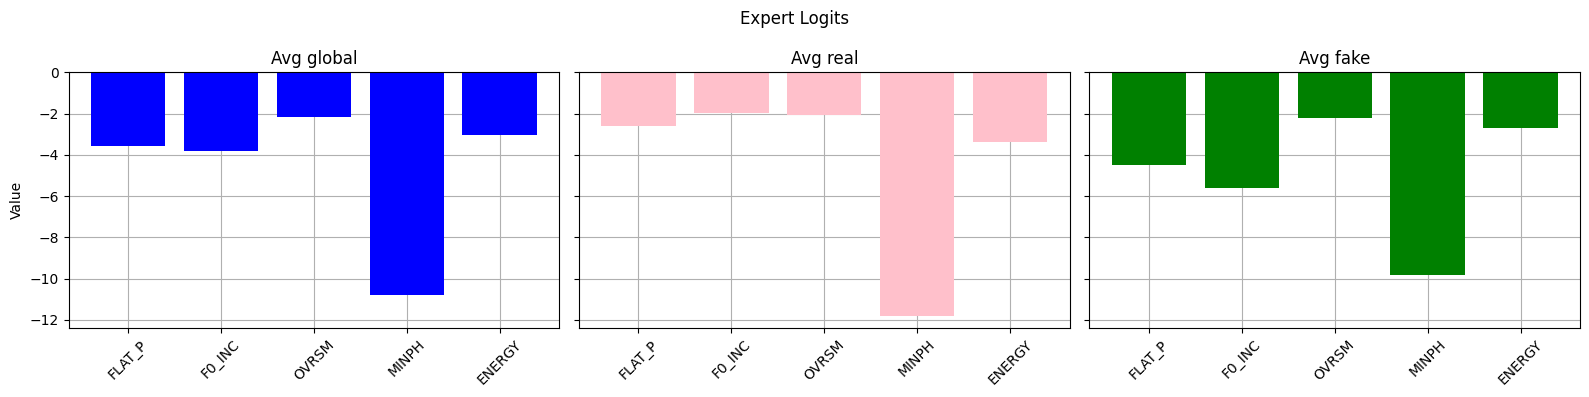

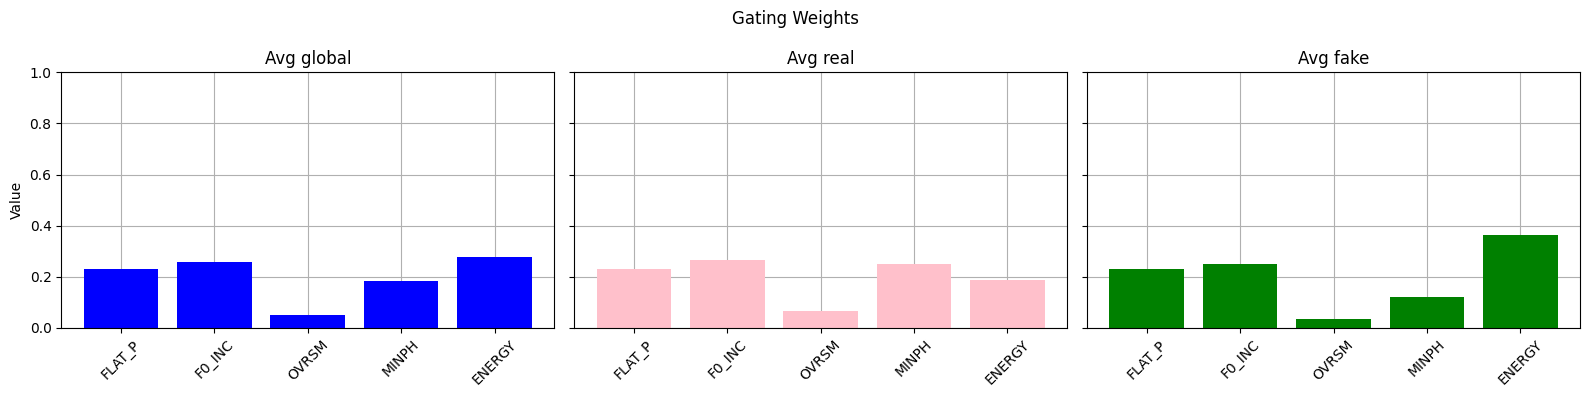

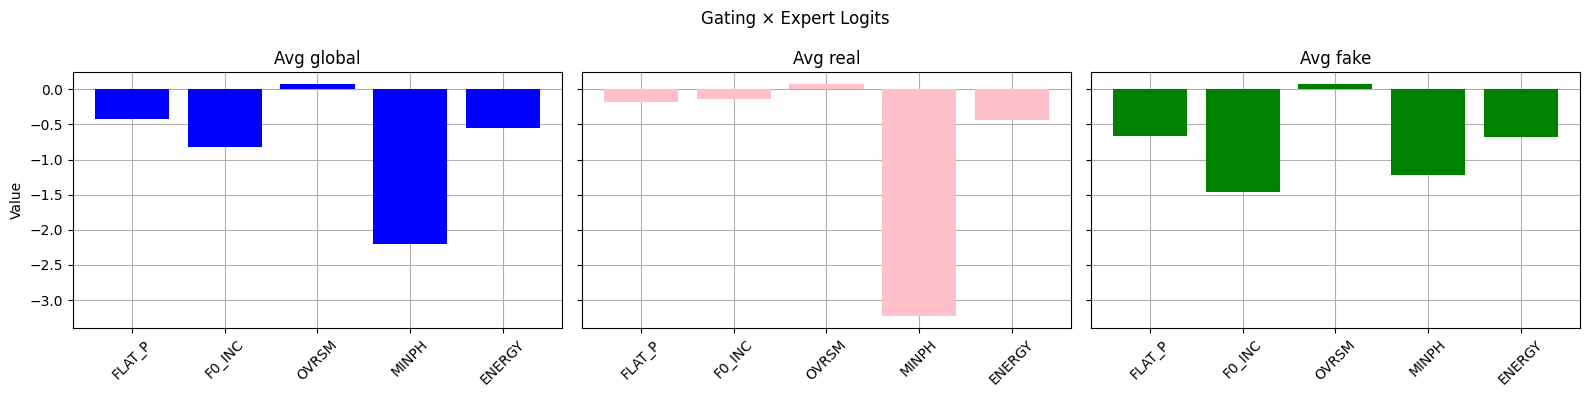

-----------------------------------
A08

Individual Experts' Performance:
AUC: 47.09%, EER: 51.51%
AUC: 30.23%, EER: 64.72%
AUC: 54.58%, EER: 48.78%
AUC: 97.17%, EER: 8.82%
AUC: 96.96%, EER: 8.37%

MoE Performance:
AUC: 94.56%, EER: 12.90%


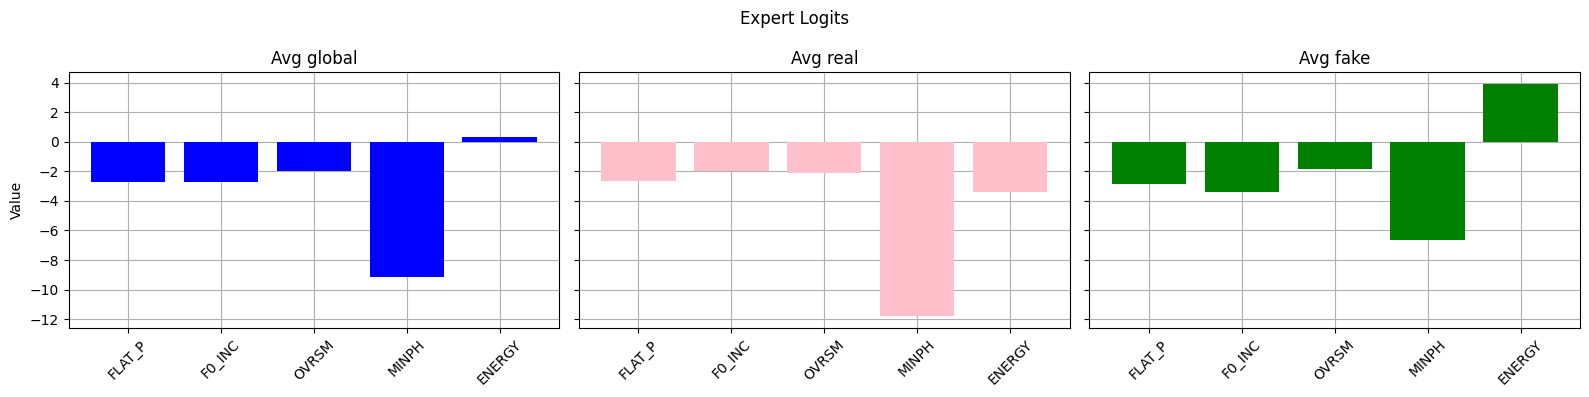

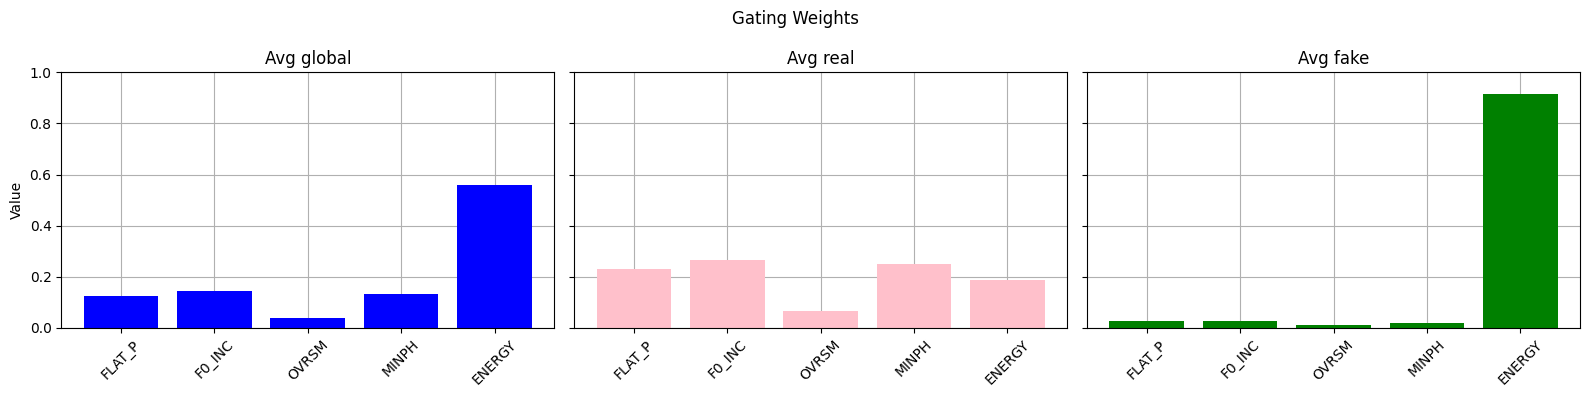

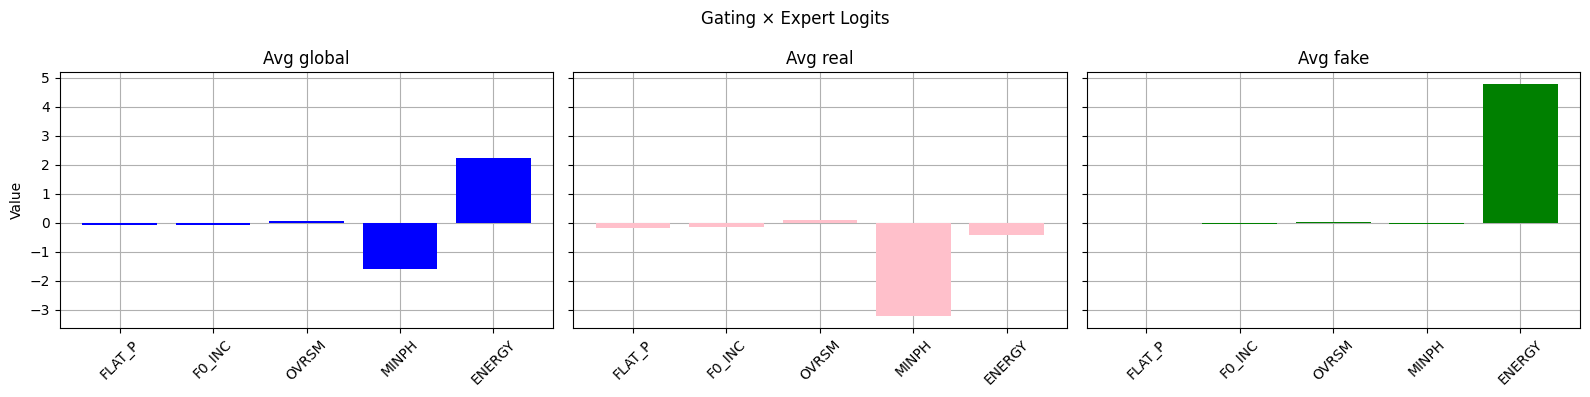

-----------------------------------
A09

Individual Experts' Performance:
AUC: 26.06%, EER: 67.94%
AUC: 13.62%, EER: 78.46%
AUC: 74.59%, EER: 33.87%
AUC: 98.97%, EER: 4.71%
AUC: 97.23%, EER: 8.62%

MoE Performance:
AUC: 94.90%, EER: 11.82%


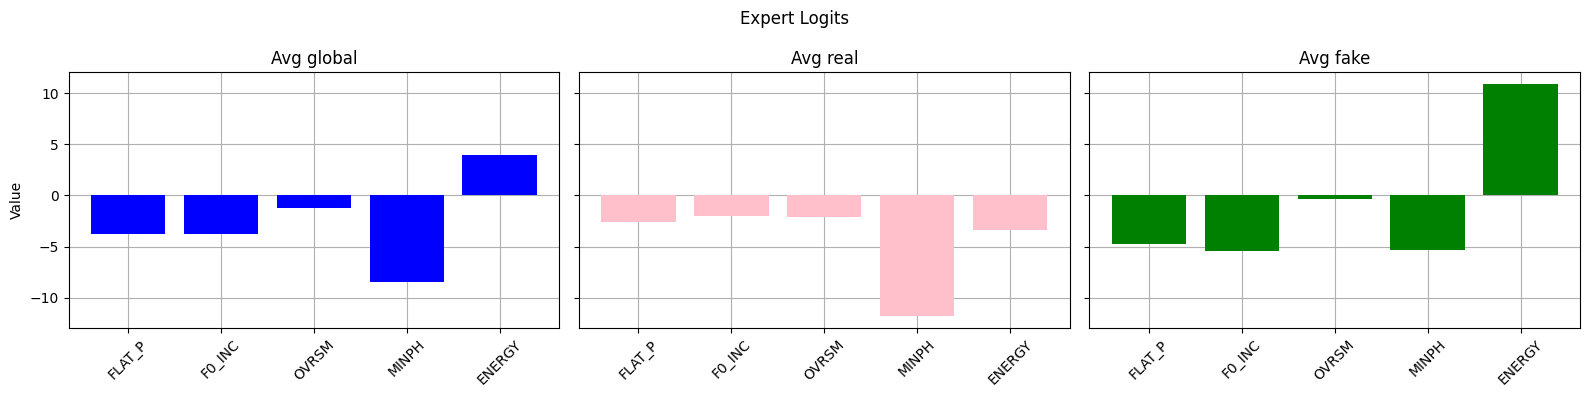

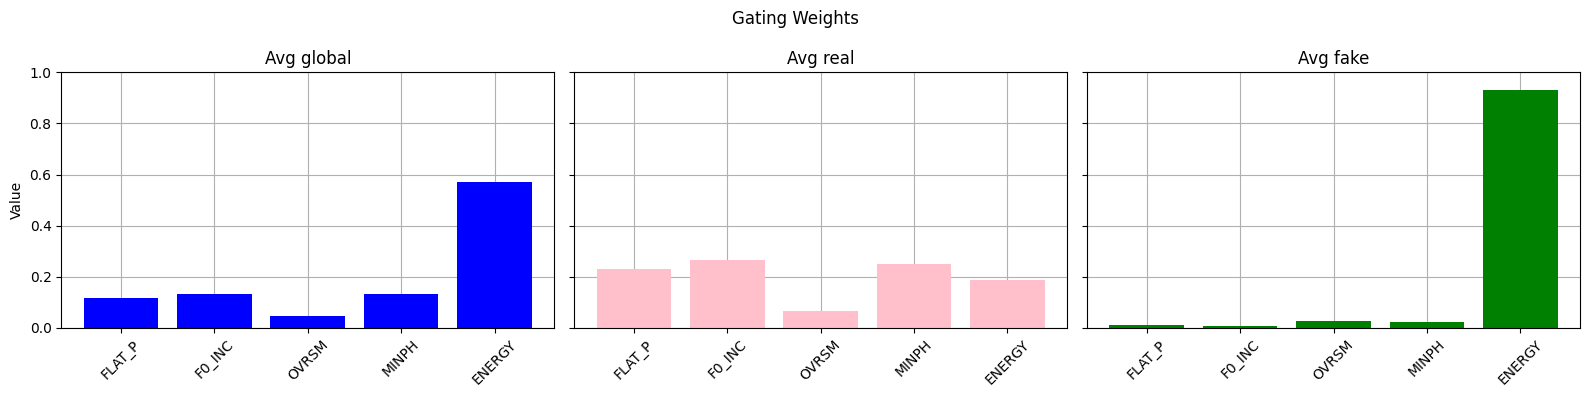

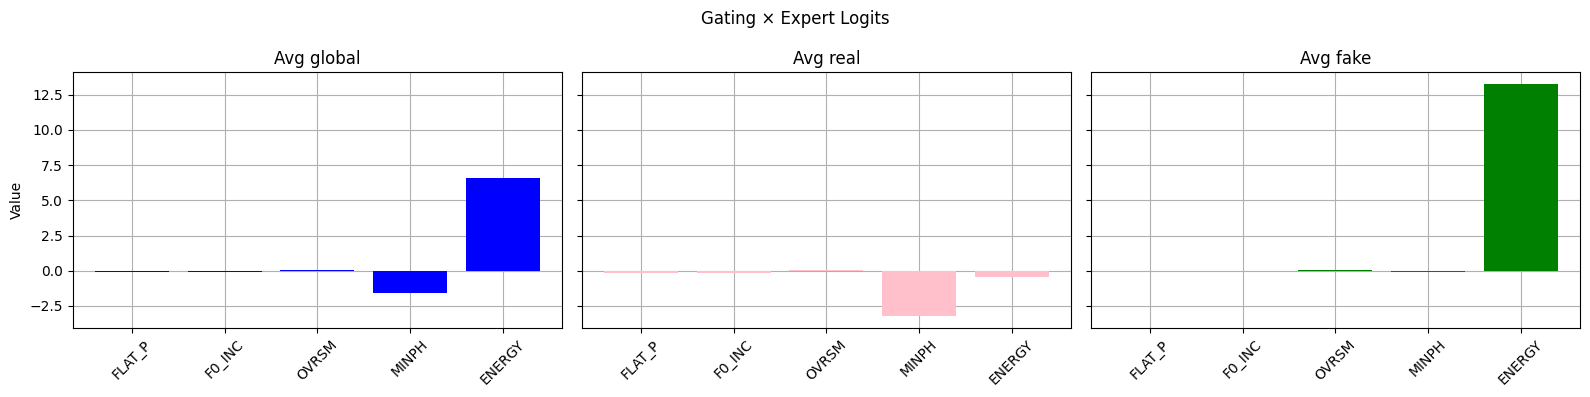

-----------------------------------
A10

Individual Experts' Performance:
AUC: 43.05%, EER: 55.47%
AUC: 39.44%, EER: 57.26%
AUC: 41.40%, EER: 57.68%
AUC: 68.30%, EER: 36.05%
AUC: 58.14%, EER: 43.89%

MoE Performance:
AUC: 50.71%, EER: 50.90%


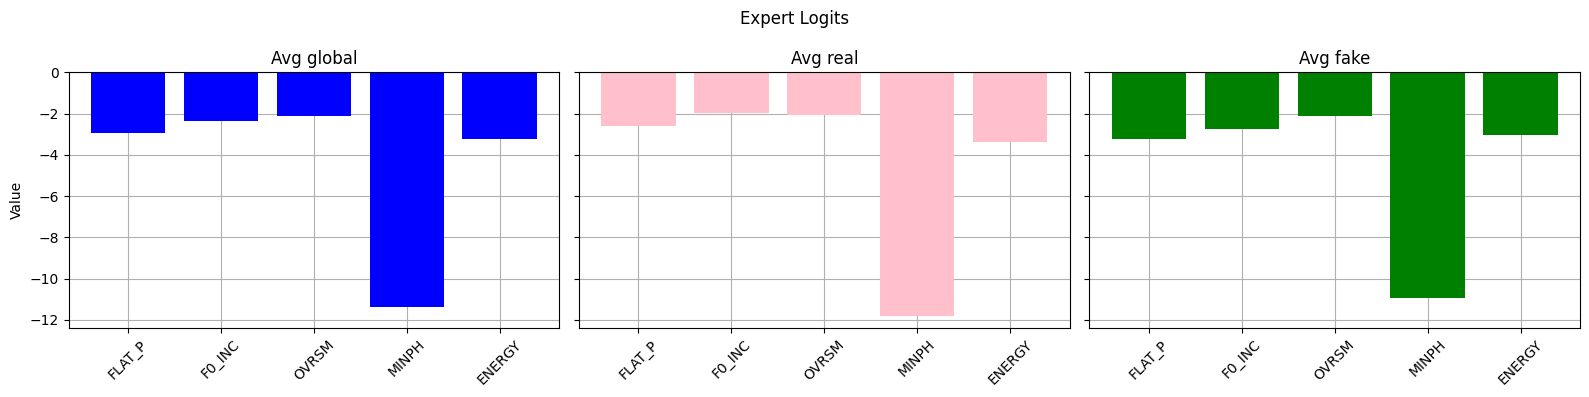

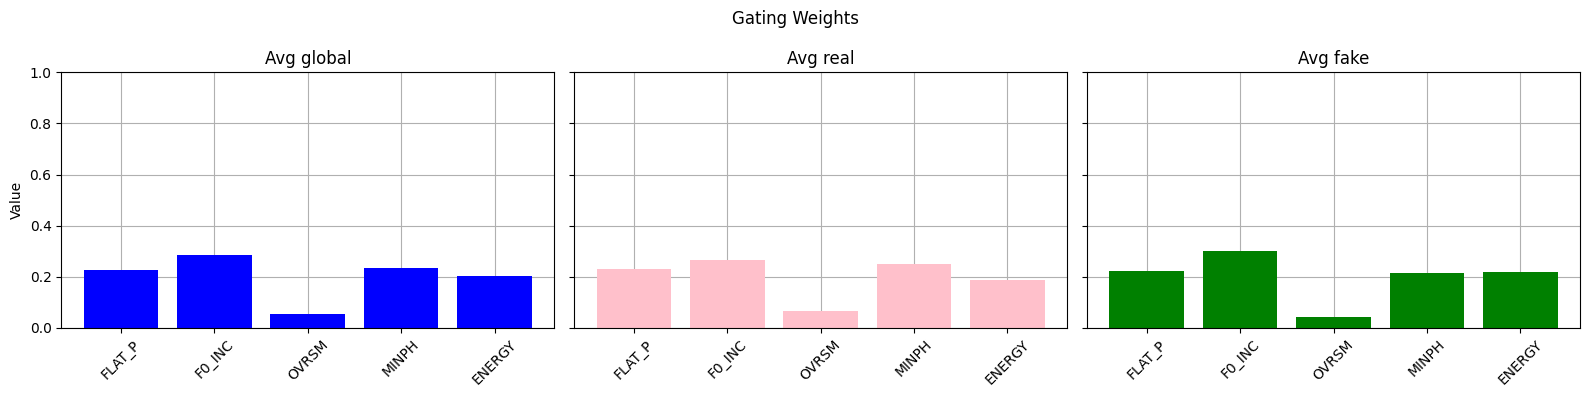

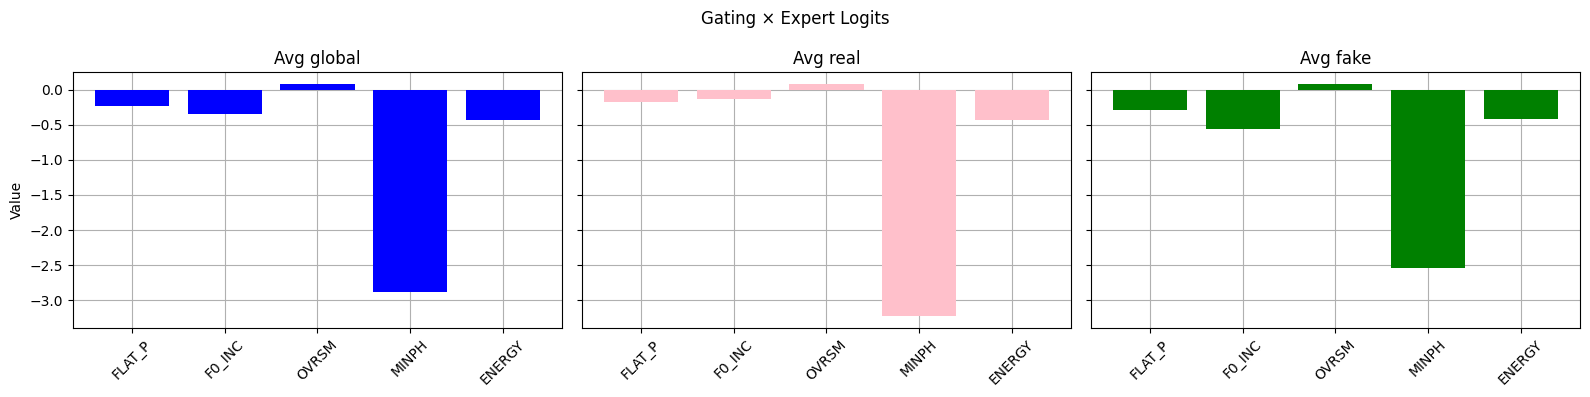

-----------------------------------
A11

Individual Experts' Performance:
AUC: 41.55%, EER: 56.11%
AUC: 36.79%, EER: 59.31%
AUC: 45.27%, EER: 56.09%
AUC: 78.28%, EER: 29.33%
AUC: 82.28%, EER: 25.19%

MoE Performance:
AUC: 81.38%, EER: 27.37%


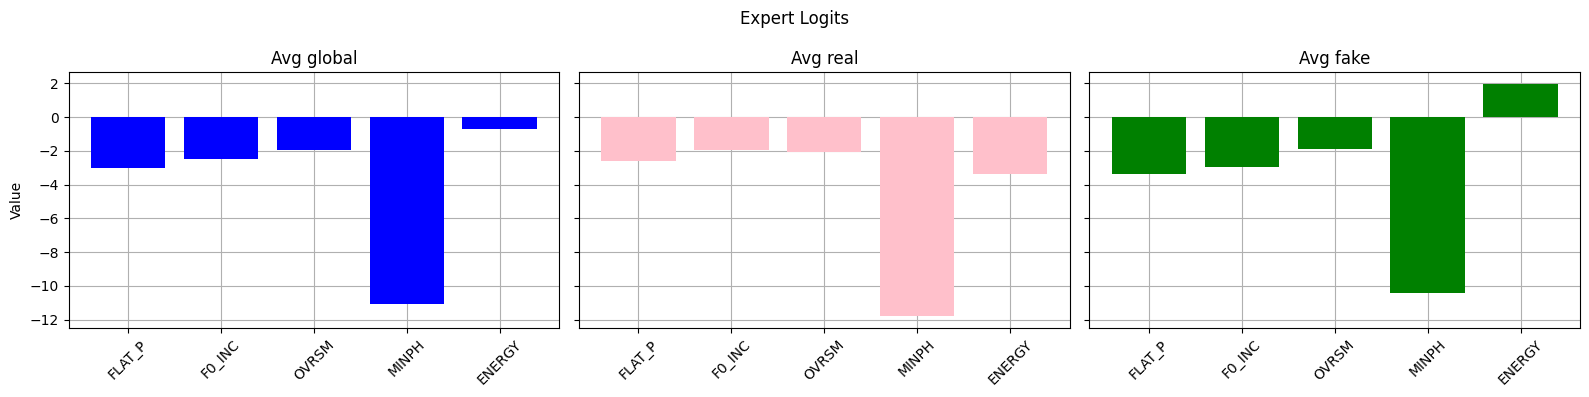

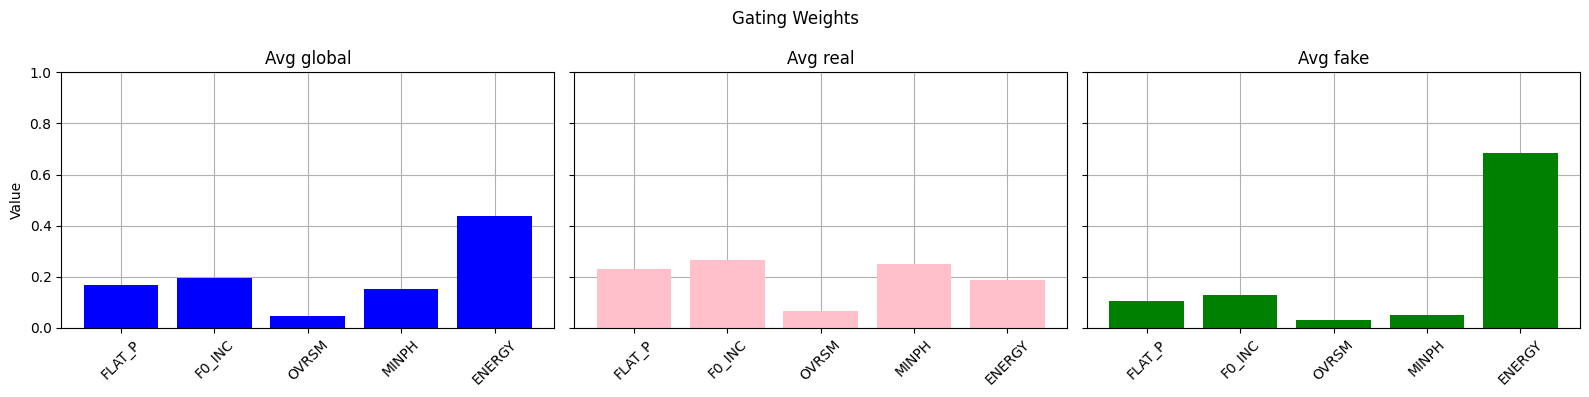

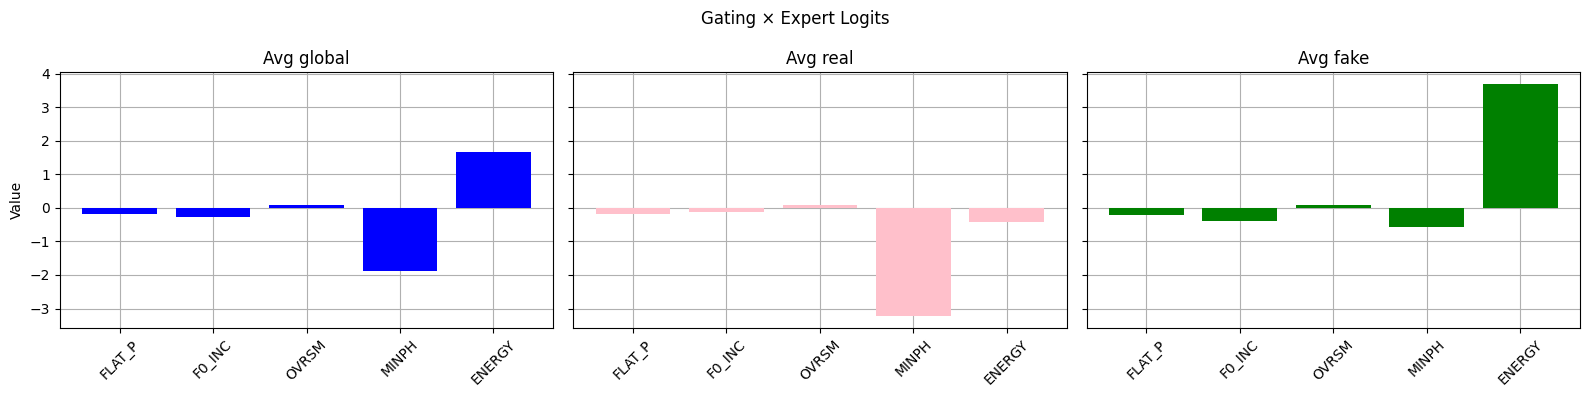

-----------------------------------
A12

Individual Experts' Performance:
AUC: 45.30%, EER: 54.55%
AUC: 41.08%, EER: 55.69%
AUC: 39.32%, EER: 58.45%
AUC: 59.22%, EER: 43.78%
AUC: 86.44%, EER: 18.93%

MoE Performance:
AUC: 86.70%, EER: 20.32%


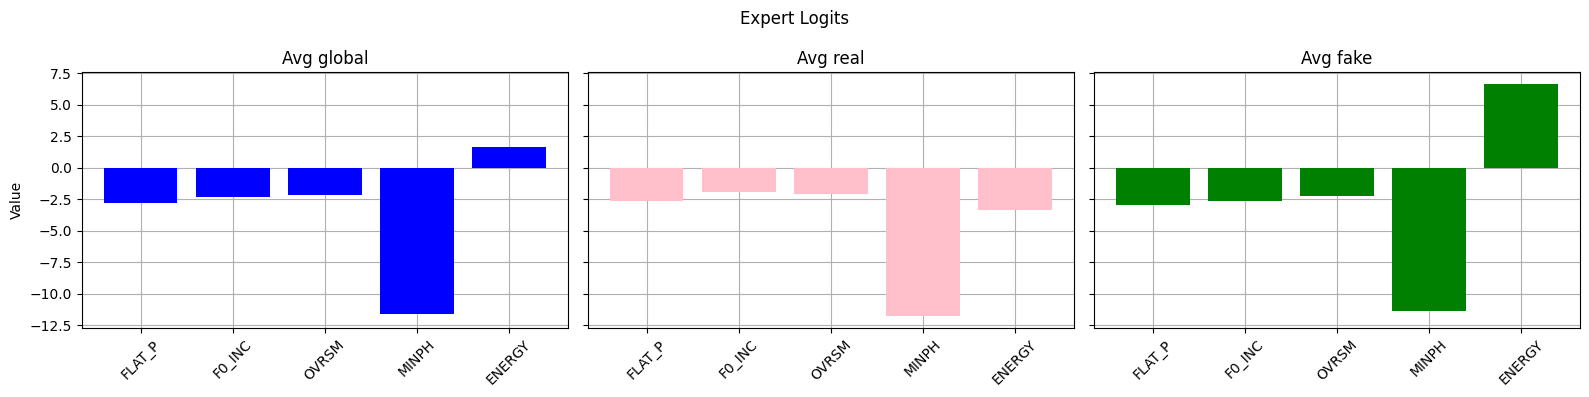

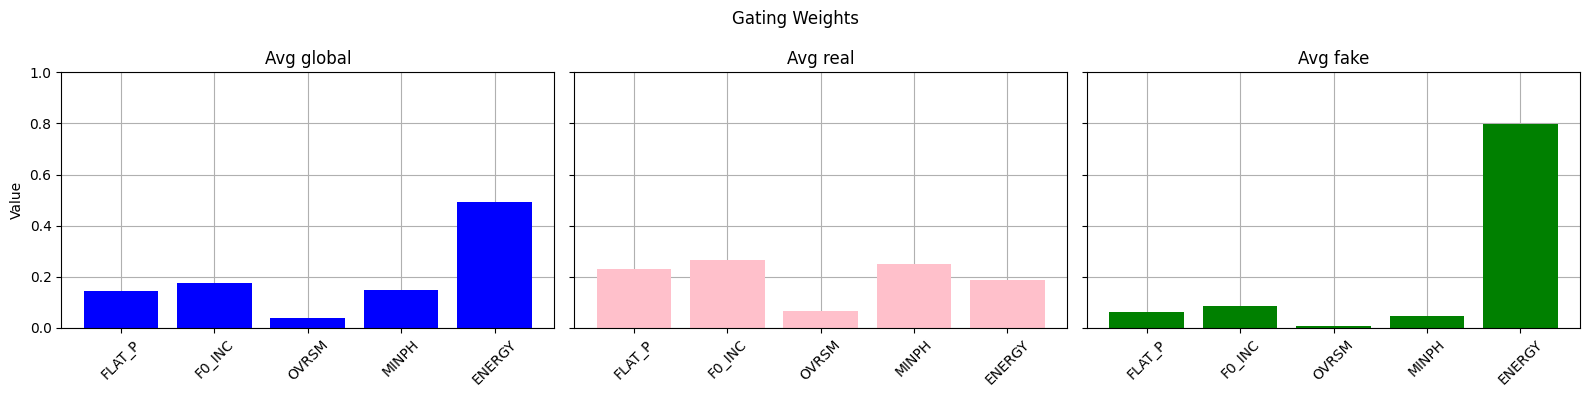

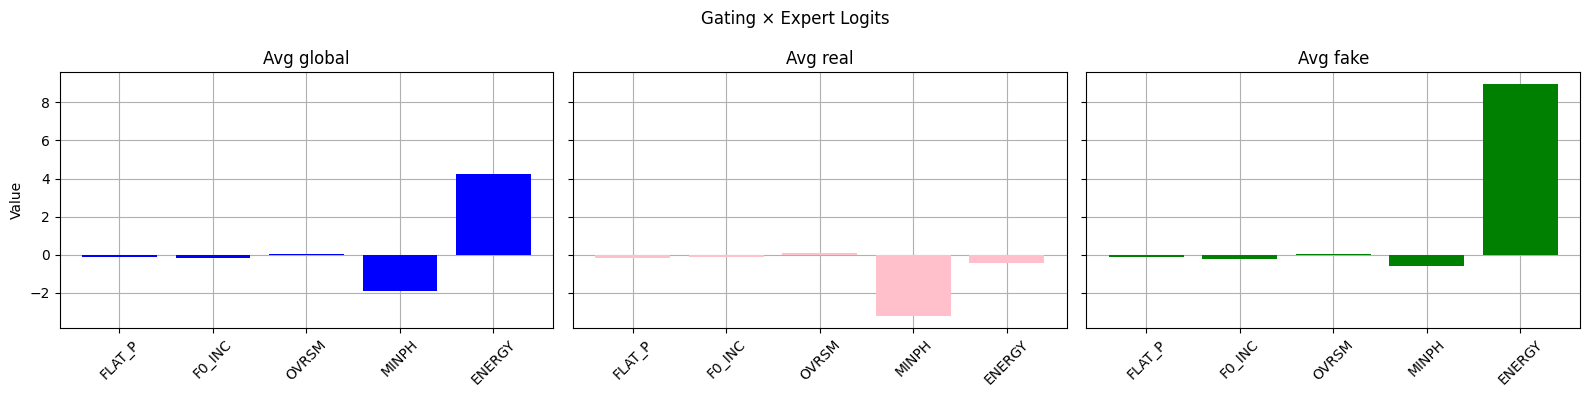

-----------------------------------


In [6]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/asv19/TargetCheck/{g}"
    model_name = "frozen_5_exp_new_calib_fixed"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=True)
    print("-----------------------------------")

## Test data from ASVspoof 5

### Overall performance


Individual Experts' Performance:
AUC: 56.97%, EER: 45.49%
AUC: 51.52%, EER: 49.08%
AUC: 47.04%, EER: 51.80%
AUC: 56.87%, EER: 44.66%
AUC: 49.72%, EER: 50.55%

MoE Performance:
AUC: 49.75%, EER: 50.58%
Loaded 25006 samples
Real mean score: 16.9964
Fake mean score: 17.2938



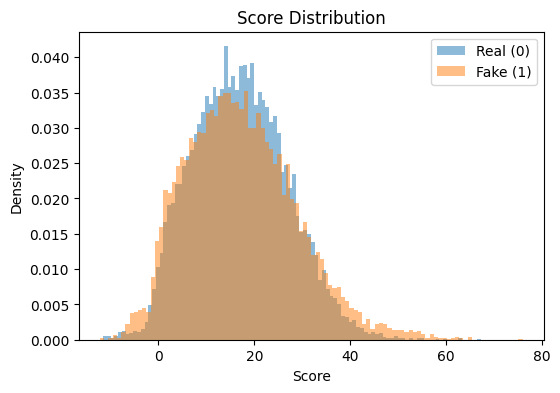

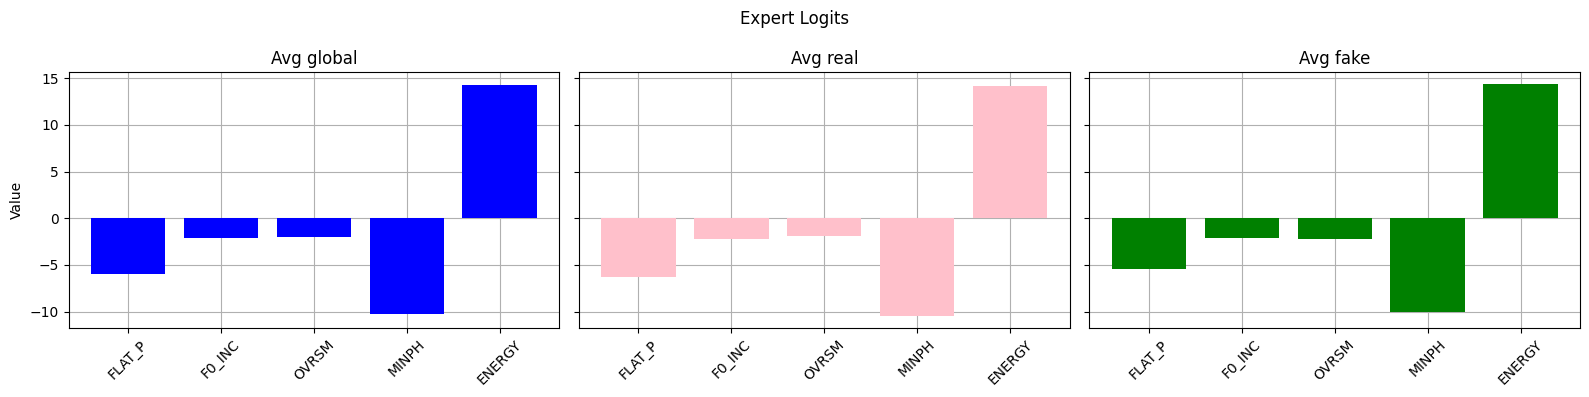

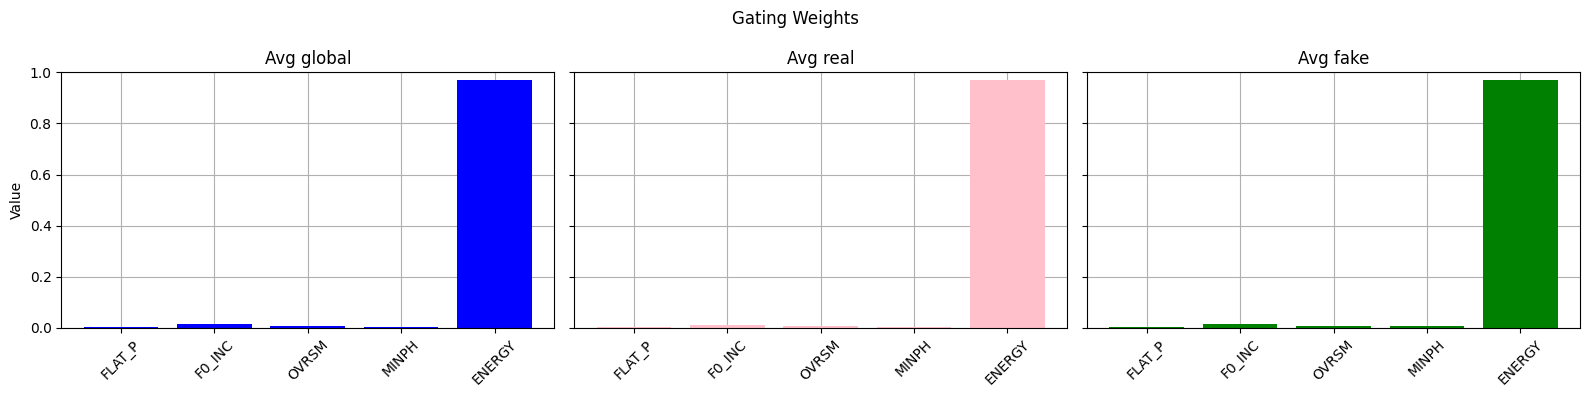

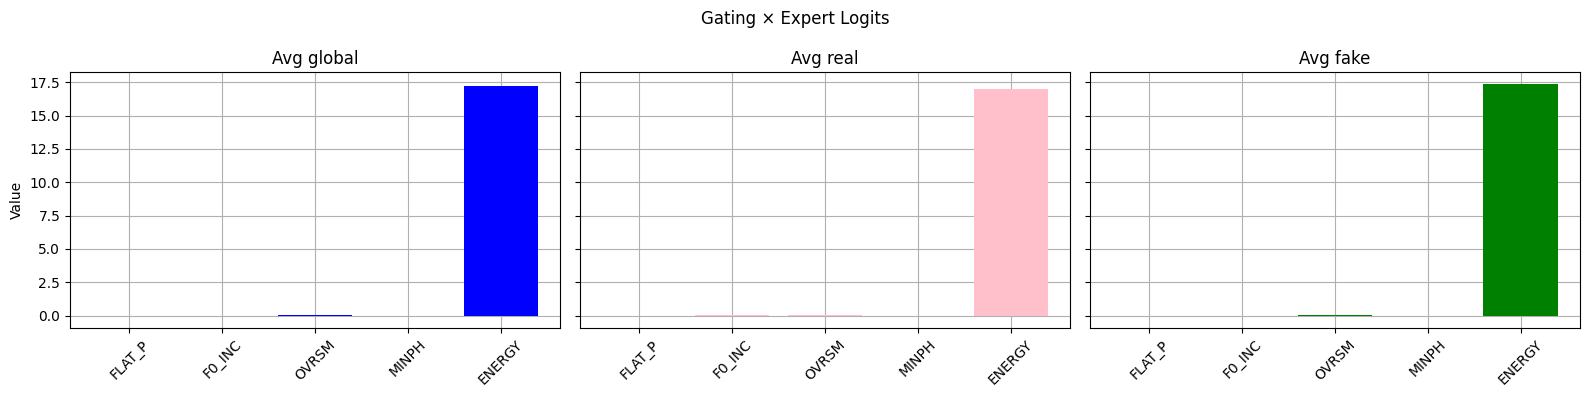

In [39]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/TargetCheck/ALL"
model_name = "frozen_5_exp_new_calib_fixed"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

### Per generator

In [41]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/TargetCheck/{g}"
    model_name = "frozen_5_exp_new_calib_fixed"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=False)
    print("-----------------------------------")

A01

Individual Experts' Performance:
AUC: 59.56%, EER: 43.37%
AUC: 60.29%, EER: 43.88%
AUC: 50.19%, EER: 48.95%
AUC: 53.77%, EER: 46.18%
AUC: 53.04%, EER: 48.59%

MoE Performance:
AUC: 53.02%, EER: 48.75%
-----------------------------------
A02

Individual Experts' Performance:
AUC: 61.41%, EER: 41.67%
AUC: 58.09%, EER: 45.00%
AUC: 49.96%, EER: 50.00%
AUC: 54.43%, EER: 45.98%
AUC: 55.65%, EER: 45.88%

MoE Performance:
AUC: 55.69%, EER: 45.68%
-----------------------------------
A03

Individual Experts' Performance:
AUC: 58.36%, EER: 44.40%
AUC: 55.93%, EER: 46.80%
AUC: 49.69%, EER: 50.30%
AUC: 61.76%, EER: 39.90%
AUC: 50.87%, EER: 49.90%

MoE Performance:
AUC: 50.91%, EER: 49.70%
-----------------------------------
A04

Individual Experts' Performance:
AUC: 60.17%, EER: 42.99%
AUC: 58.69%, EER: 44.98%
AUC: 40.14%, EER: 56.22%
AUC: 65.80%, EER: 37.05%
AUC: 48.41%, EER: 51.10%

MoE Performance:
AUC: 48.34%, EER: 51.16%
-----------------------------------
A05

Individual Experts' Perform

### Sanity Check on ASVspoof 5
#### All manipulations applied


Individual Experts' Performance:
AUC: 92.33%, EER: 15.30%
AUC: 96.00%, EER: 9.50%
AUC: 91.37%, EER: 13.30%
AUC: 100.00%, EER: 0.00%
AUC: 66.71%, EER: 38.40%

MoE Performance:
AUC: 65.58%, EER: 39.70%
Loaded 2000 samples
Real mean score: 17.8635
Fake mean score: 24.0243



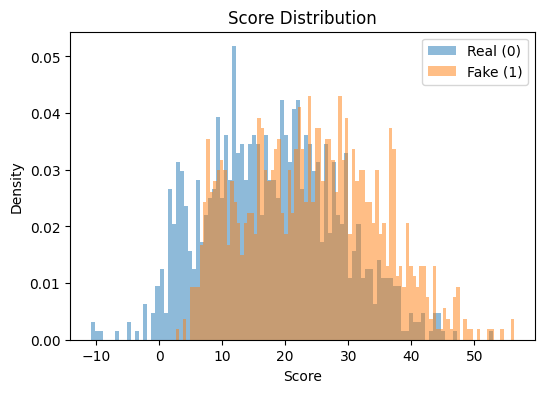

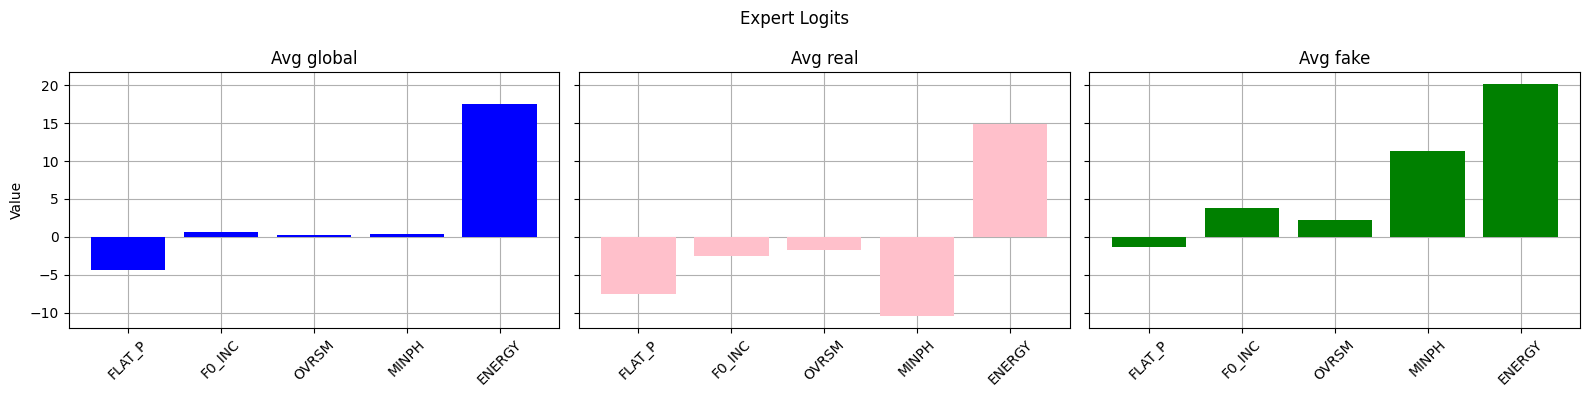

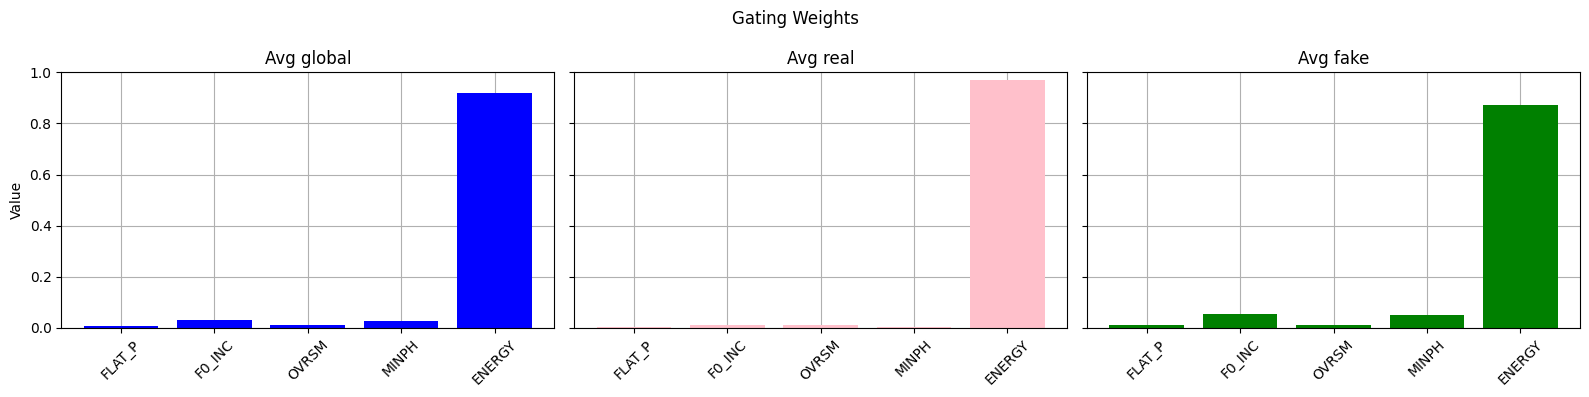

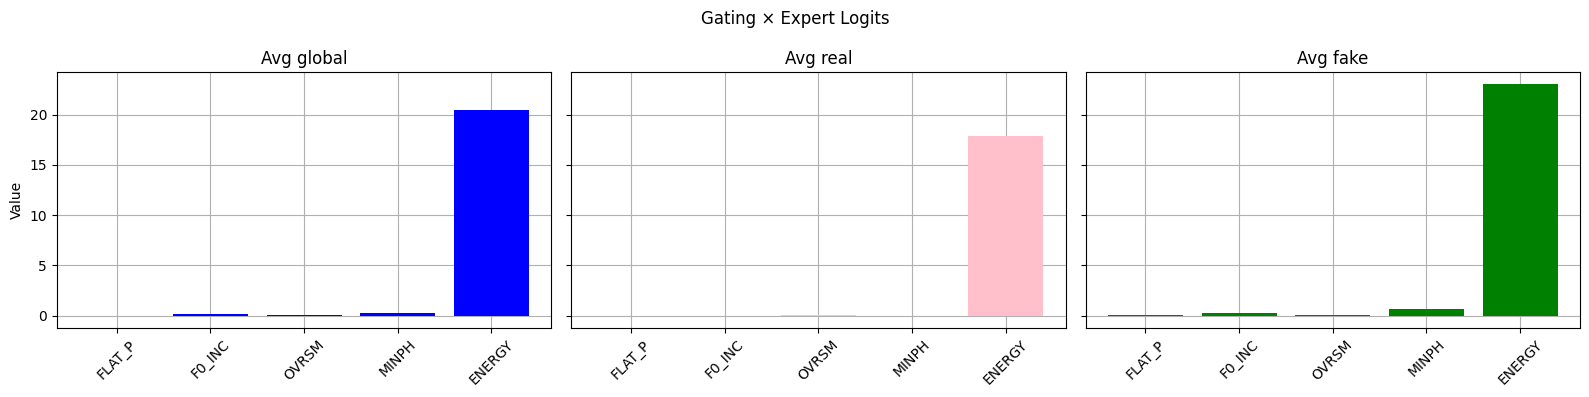

In [25]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/SanityCheck/ALL"
model_name = "frozen_5_exp_new_calib_fixed"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

#### One manipulation at a time

In [26]:
manip_list = ['flat_pitch', 'f0_incons', 'oversmooth', 'min_phase', 'energy']
for m in manip_list:
    print(m)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/SanityCheck/{m}"
    model_name = "frozen_5_exp_new_calib_fixed"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=False)
    print("-----------------------------------")

flat_pitch

Individual Experts' Performance:
AUC: 92.33%, EER: 15.30%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%

MoE Performance:
AUC: 48.80%, EER: 50.70%
-----------------------------------
f0_incons

Individual Experts' Performance:
AUC: 50.00%, EER: 50.00%
AUC: 95.88%, EER: 9.60%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%

MoE Performance:
AUC: 49.19%, EER: 51.00%
-----------------------------------
oversmooth

Individual Experts' Performance:
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%
AUC: 91.37%, EER: 13.30%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%

MoE Performance:
AUC: 49.36%, EER: 50.40%
-----------------------------------
min_phase

Individual Experts' Performance:
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%
AUC: 50.00%, EER: 50.00%
AUC: 100.00%, EER: 0.00%
AUC: 50.00%, EER: 50.00%

MoE Performance:
AUC: 52.20%, EER: 50.50%
-----------------------------------
energy


# As above model, but TRAINING DATA is from ASV 5

## Test on ASV 5 

### Overall performance


Individual Experts' Performance:
AUC: 57.80%, EER: 44.61%
AUC: 60.90%, EER: 42.30%
AUC: 48.81%, EER: 50.93%
AUC: 50.97%, EER: 48.68%
AUC: 56.14%, EER: 45.22%

MoE Performance:
AUC: 55.05%, EER: 46.12%
Loaded 25006 samples
Real mean score: -3.4674
Fake mean score: -3.2263



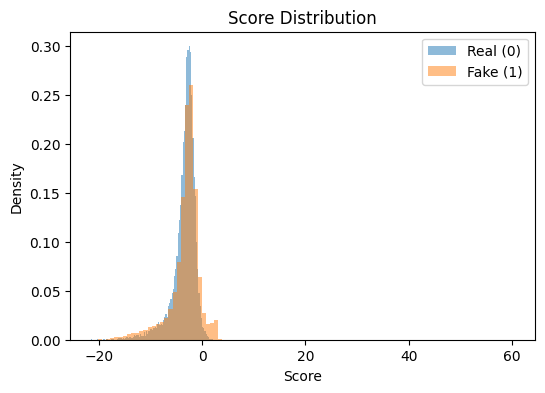

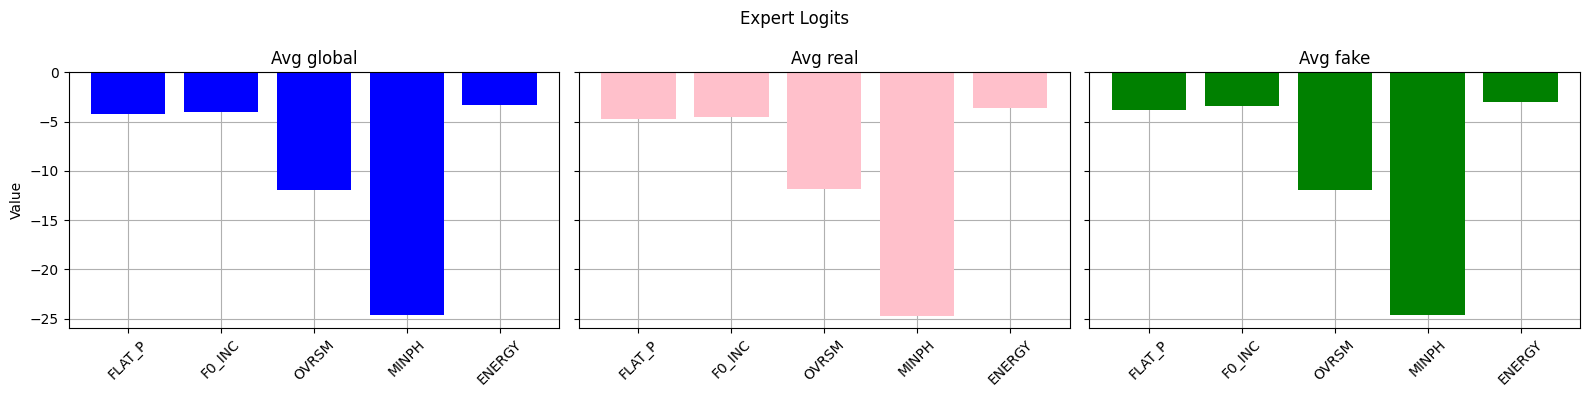

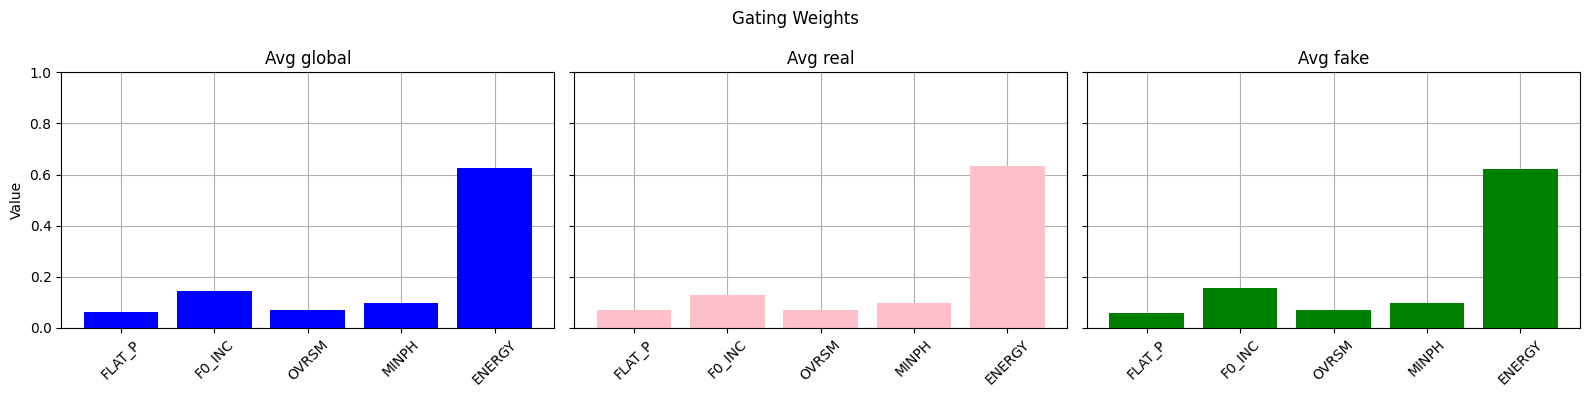

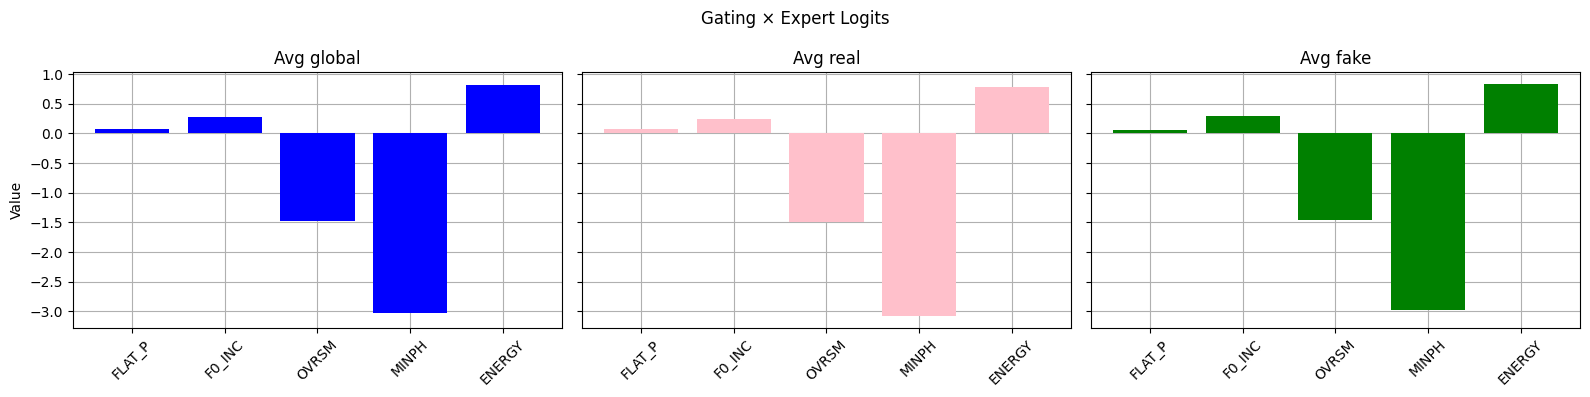

In [44]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/TargetCheck/ALL"
model_name = "asv5_frozen_5_exp_calib"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

### Per generator

A01

Individual Experts' Performance:
AUC: 66.33%, EER: 37.95%
AUC: 72.63%, EER: 33.13%
AUC: 50.64%, EER: 50.40%
AUC: 49.86%, EER: 50.15%
AUC: 63.87%, EER: 39.46%

MoE Performance:
AUC: 62.87%, EER: 40.56%


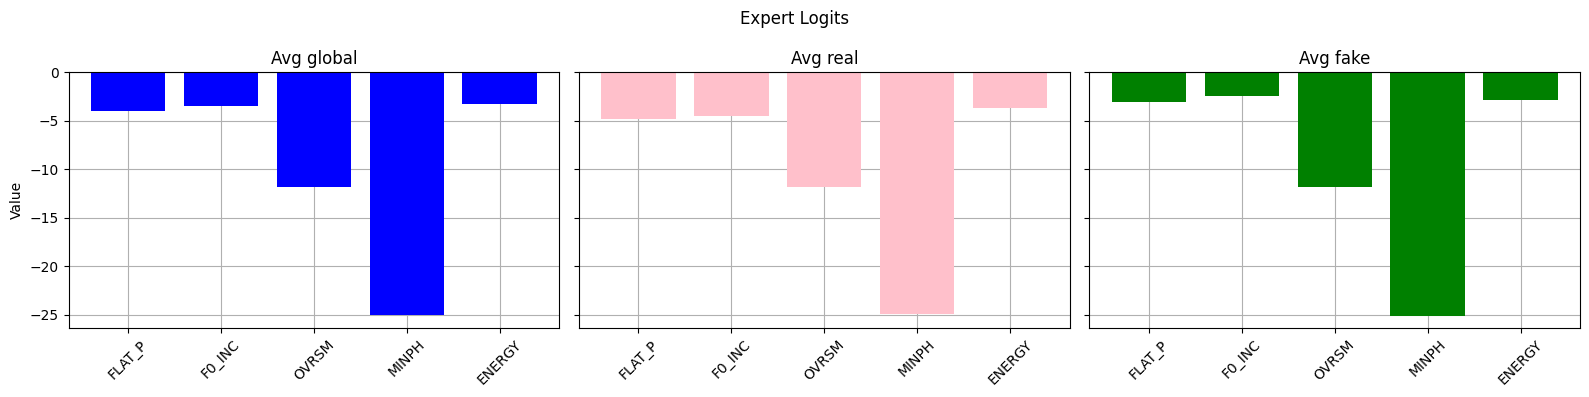

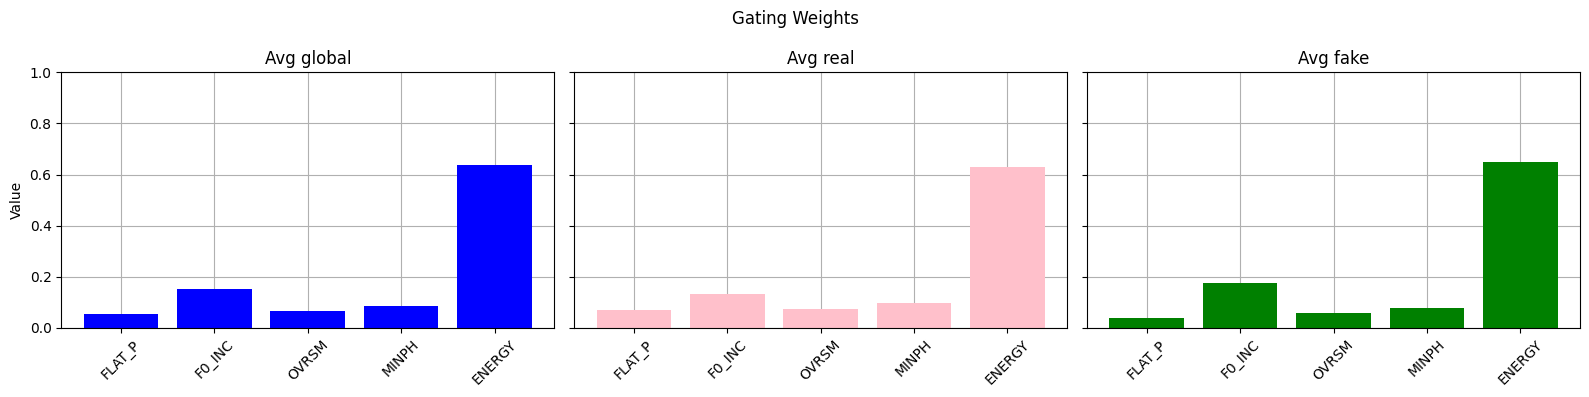

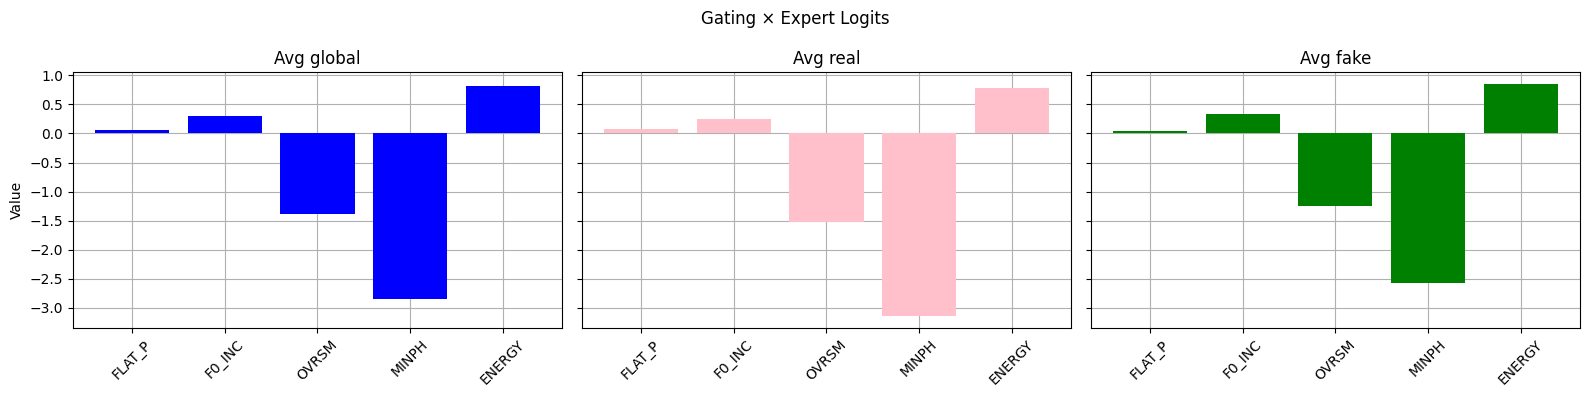

-----------------------------------
A02

Individual Experts' Performance:
AUC: 65.96%, EER: 37.95%
AUC: 70.69%, EER: 34.44%
AUC: 52.66%, EER: 48.20%
AUC: 48.88%, EER: 50.10%
AUC: 64.96%, EER: 38.90%

MoE Performance:
AUC: 63.82%, EER: 40.20%


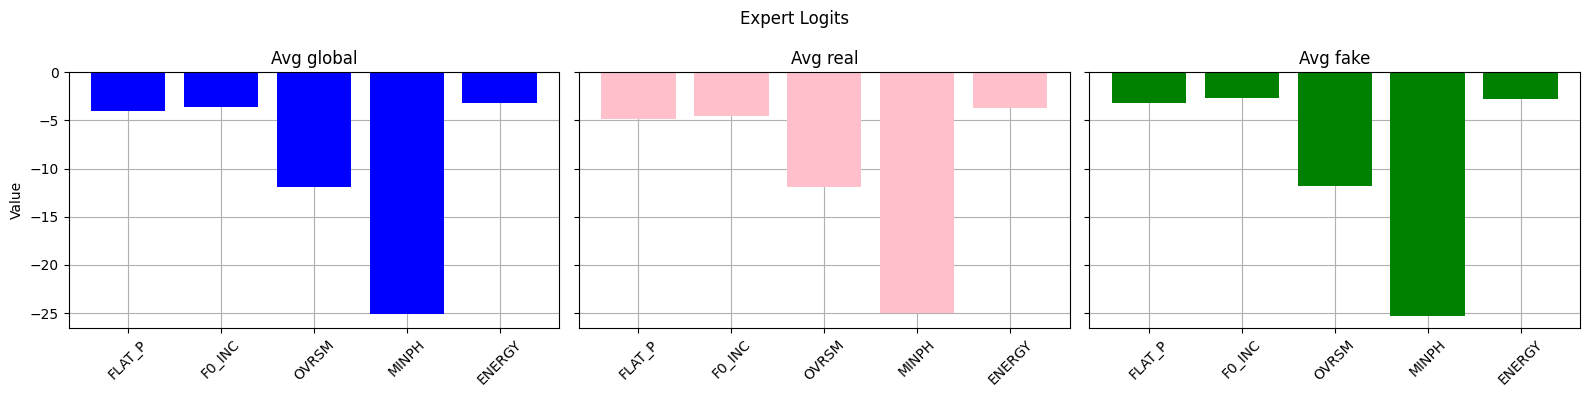

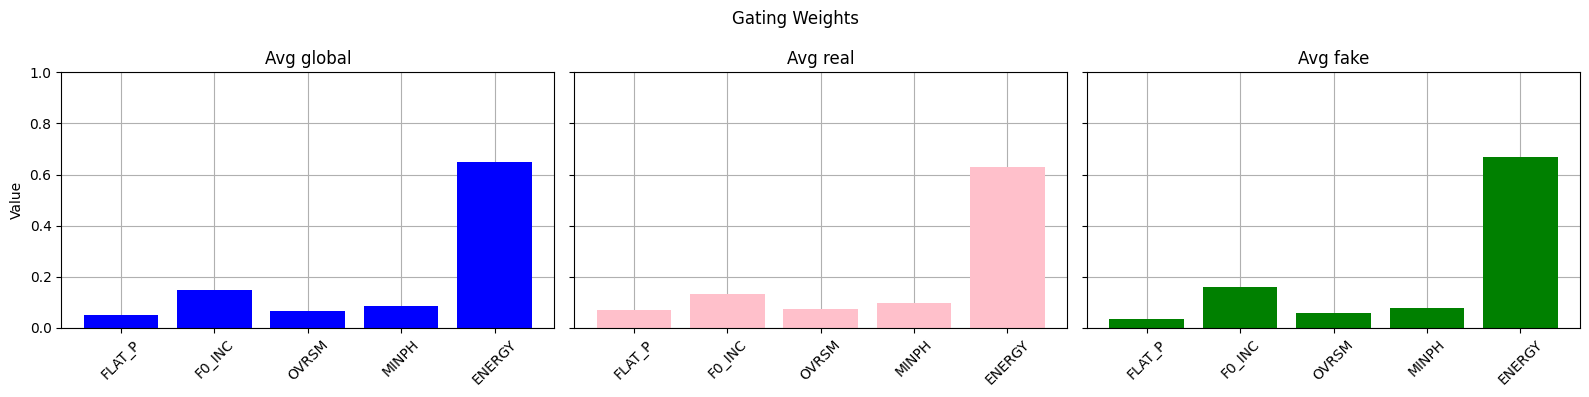

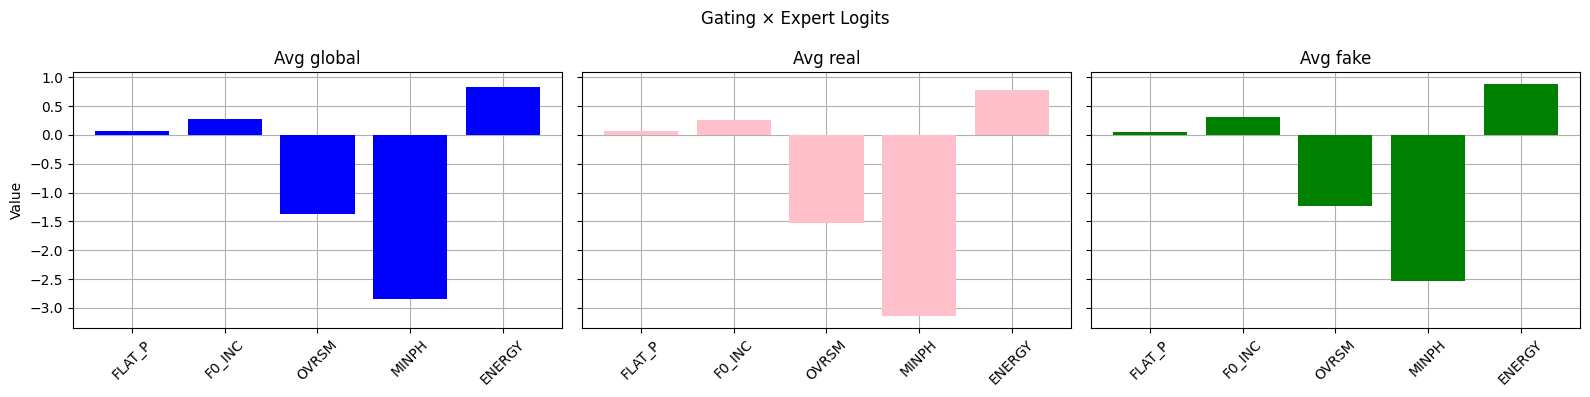

-----------------------------------
A03

Individual Experts' Performance:
AUC: 65.58%, EER: 39.00%
AUC: 68.01%, EER: 35.24%
AUC: 51.15%, EER: 49.50%
AUC: 58.70%, EER: 43.40%
AUC: 62.57%, EER: 40.00%

MoE Performance:
AUC: 61.11%, EER: 41.30%


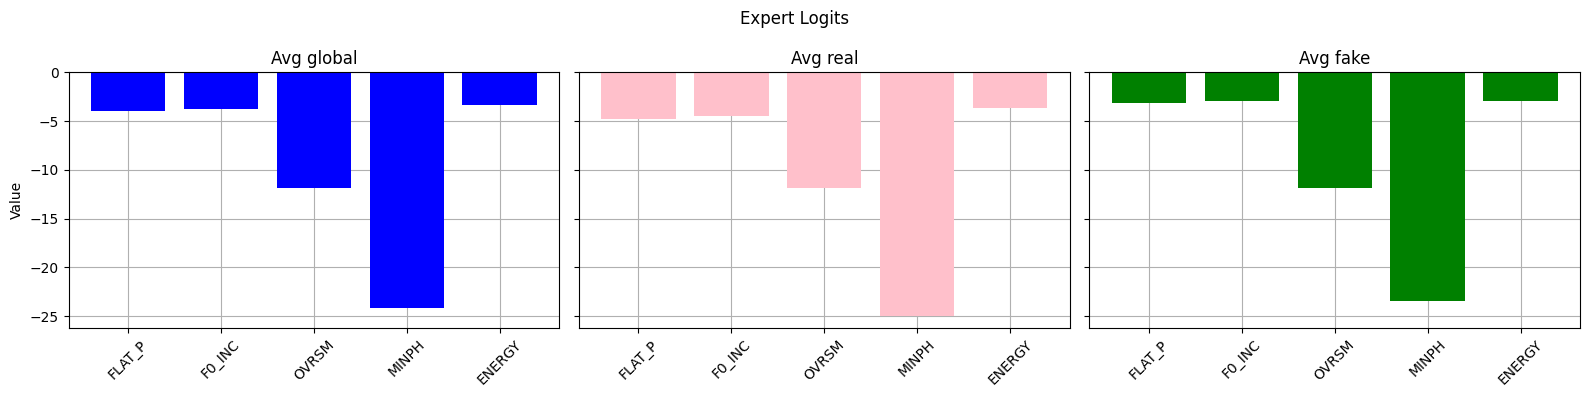

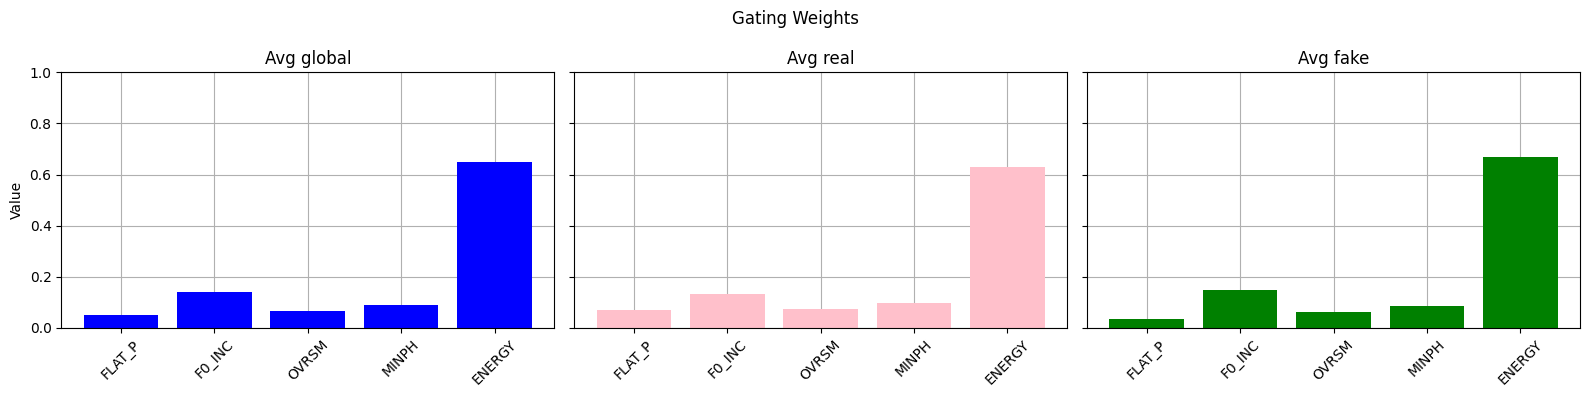

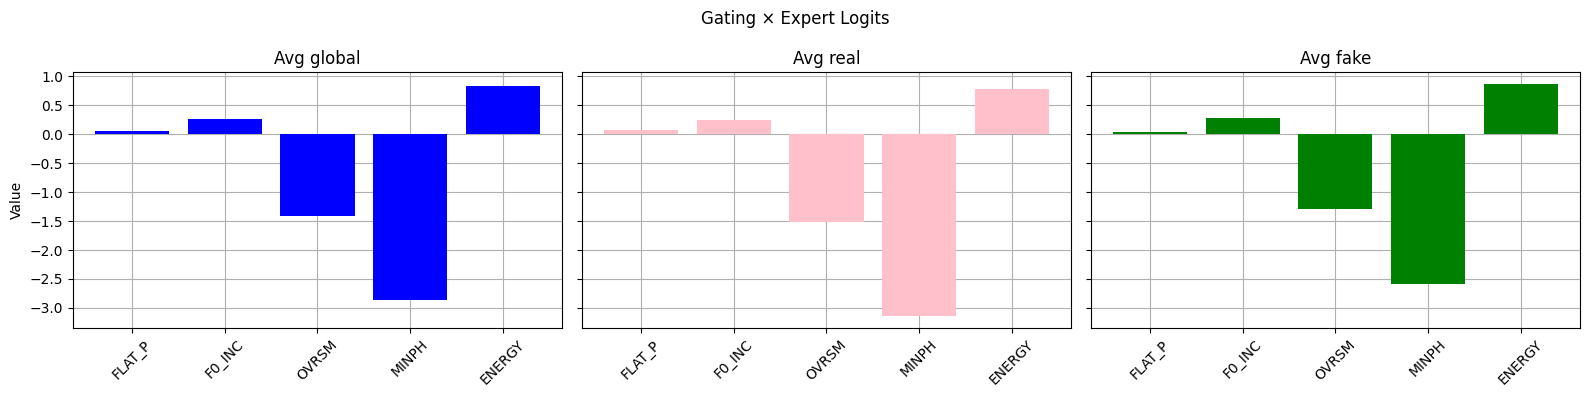

-----------------------------------
A04

Individual Experts' Performance:
AUC: 65.00%, EER: 38.65%
AUC: 68.26%, EER: 35.84%
AUC: 44.39%, EER: 53.48%
AUC: 57.25%, EER: 44.80%
AUC: 53.61%, EER: 47.43%

MoE Performance:
AUC: 58.87%, EER: 43.78%


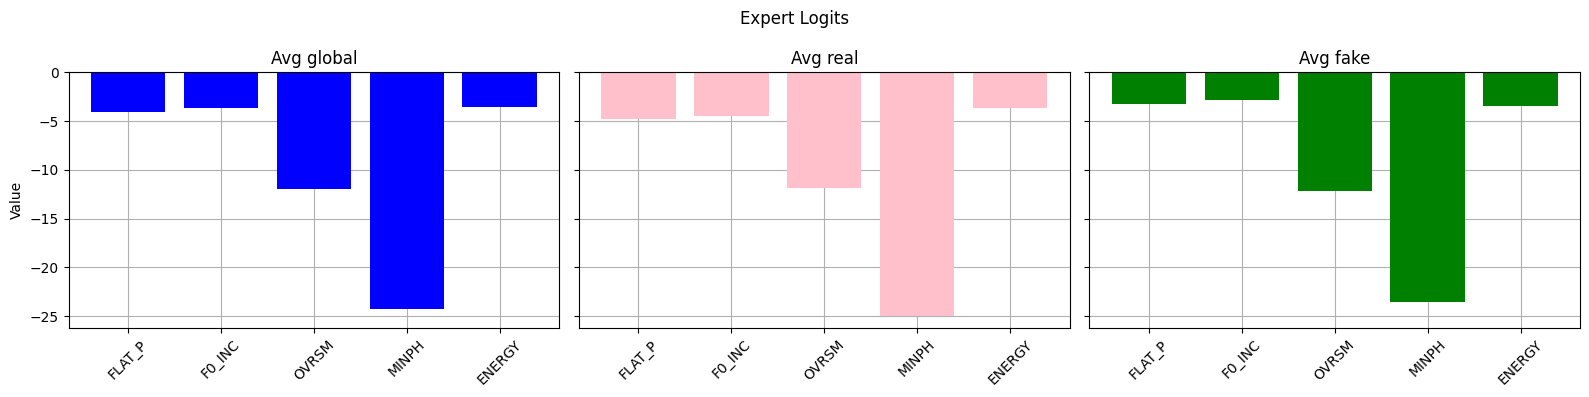

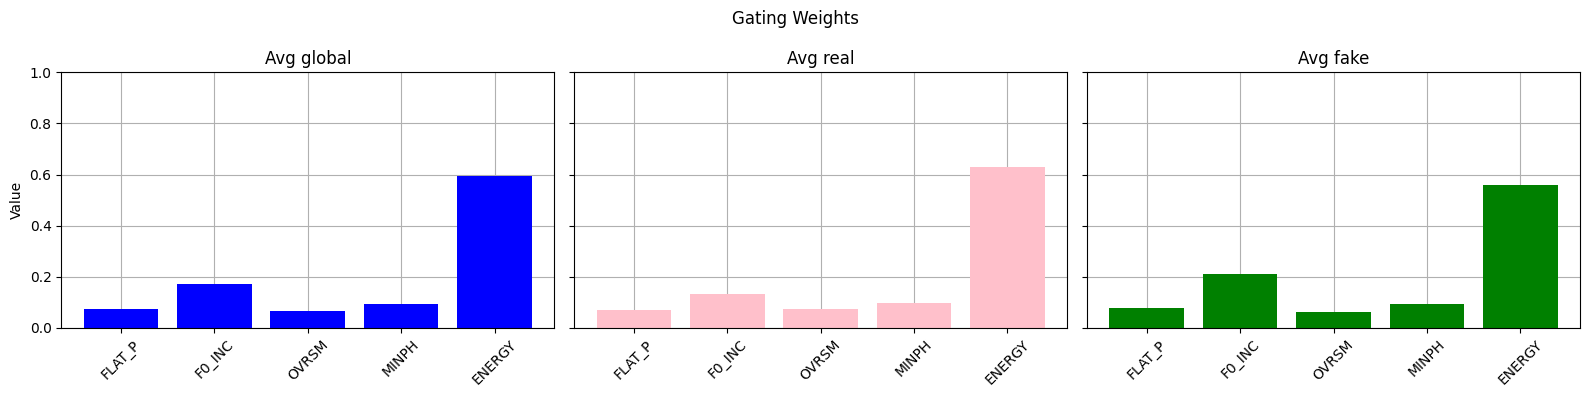

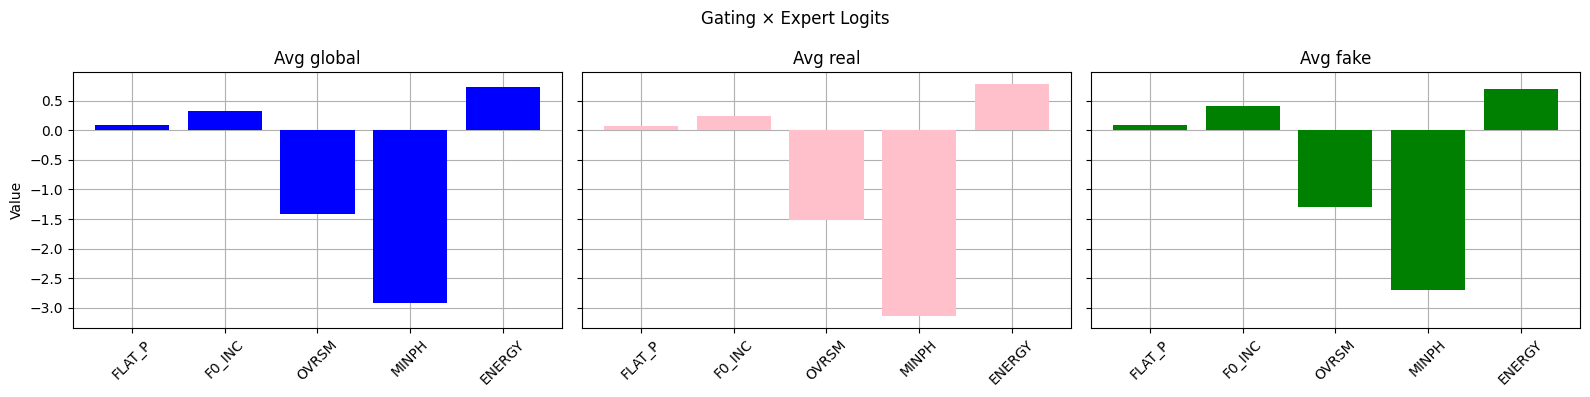

-----------------------------------
A05

Individual Experts' Performance:
AUC: 64.91%, EER: 38.45%
AUC: 67.80%, EER: 36.55%
AUC: 46.11%, EER: 52.51%
AUC: 60.55%, EER: 42.07%
AUC: 50.55%, EER: 50.30%

MoE Performance:
AUC: 58.78%, EER: 43.67%


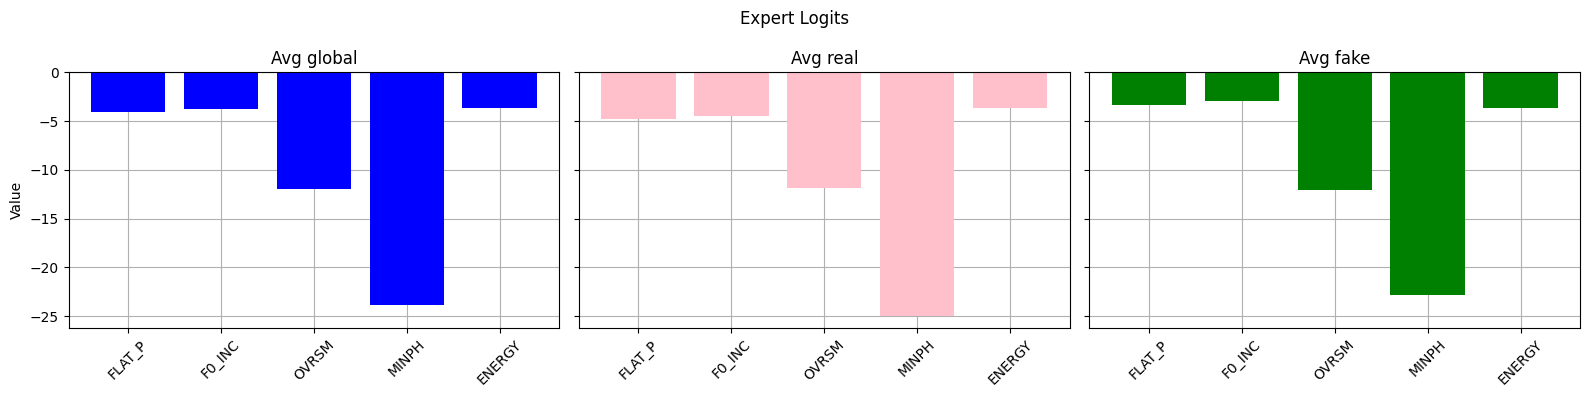

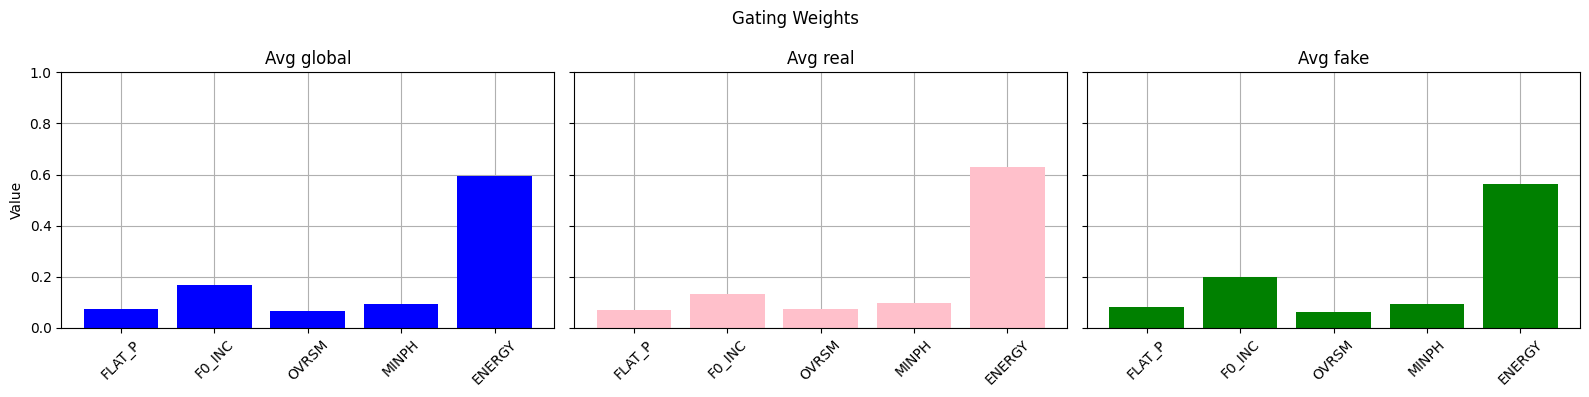

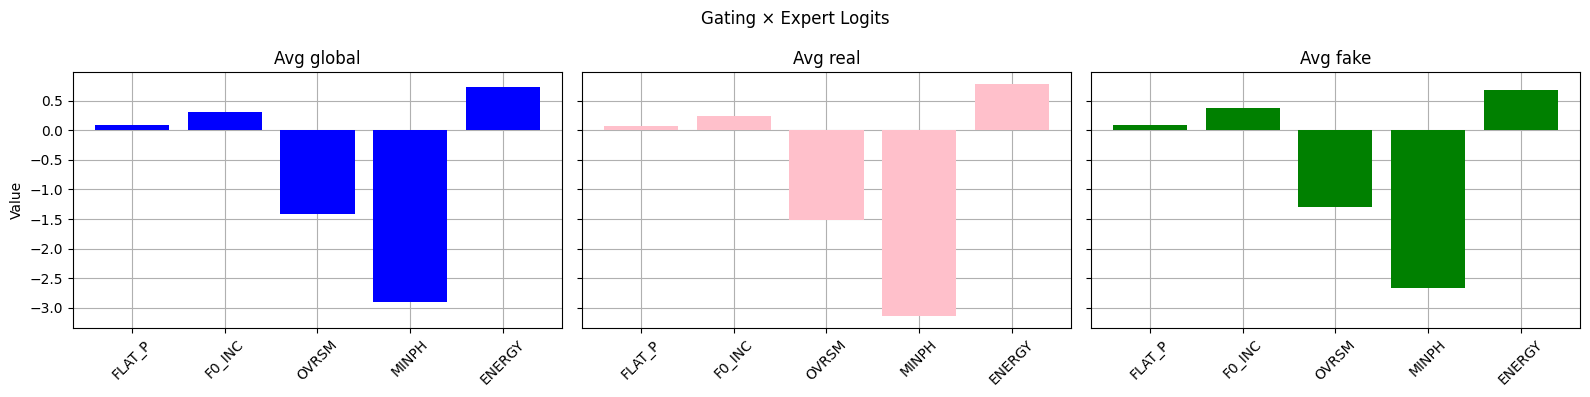

-----------------------------------
A06

Individual Experts' Performance:
AUC: 62.36%, EER: 40.16%
AUC: 64.45%, EER: 39.36%
AUC: 47.39%, EER: 51.81%
AUC: 52.82%, EER: 48.29%
AUC: 57.66%, EER: 44.48%

MoE Performance:
AUC: 60.82%, EER: 42.27%


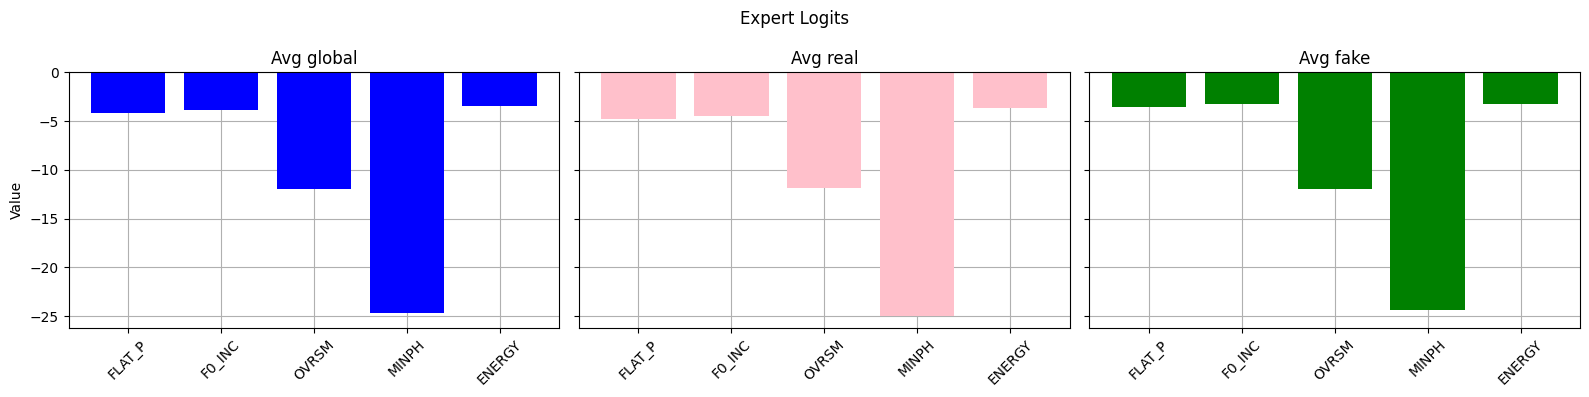

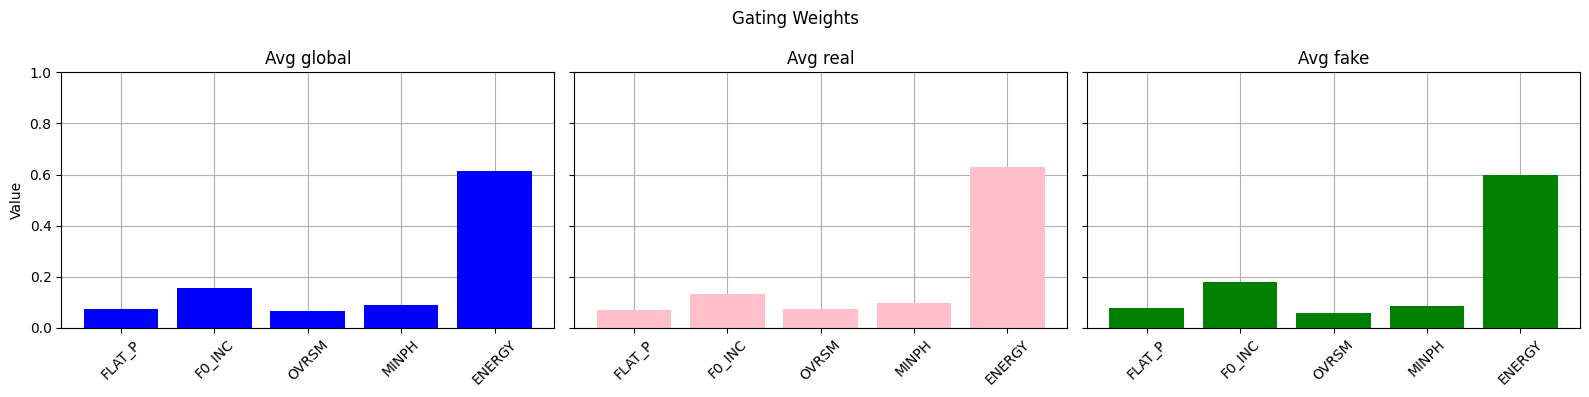

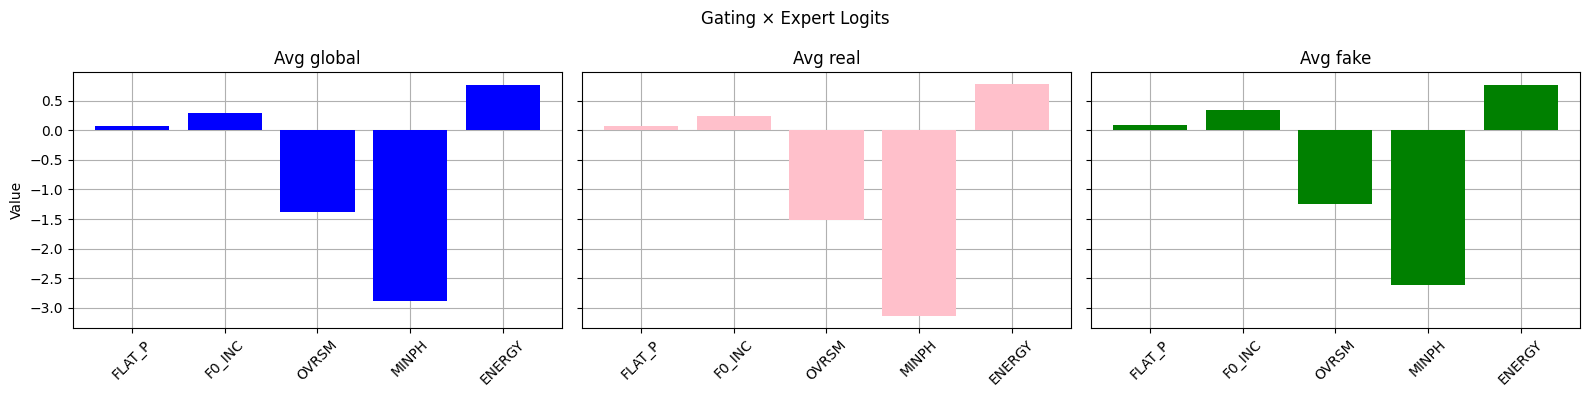

-----------------------------------
A07

Individual Experts' Performance:
AUC: 48.68%, EER: 51.75%
AUC: 38.88%, EER: 58.26%
AUC: 51.79%, EER: 49.45%
AUC: 74.26%, EER: 32.33%
AUC: 55.22%, EER: 46.25%

MoE Performance:
AUC: 49.73%, EER: 51.20%


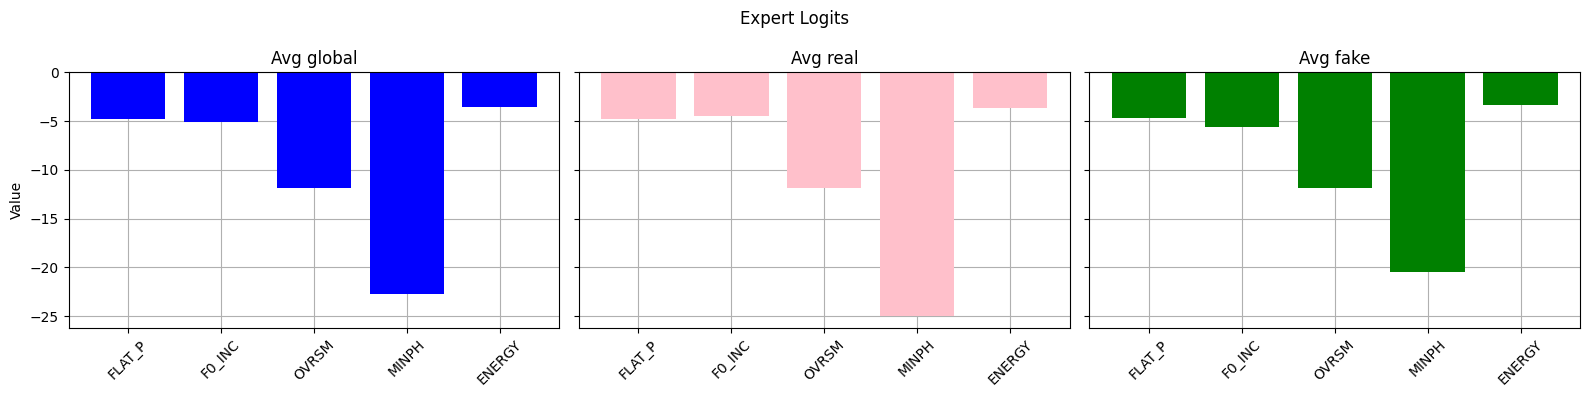

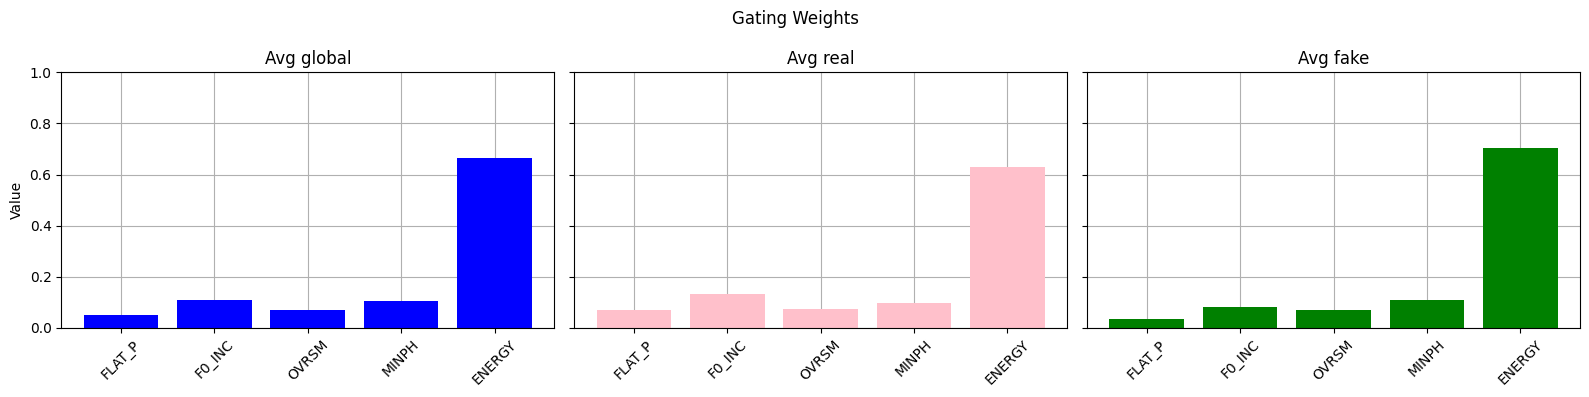

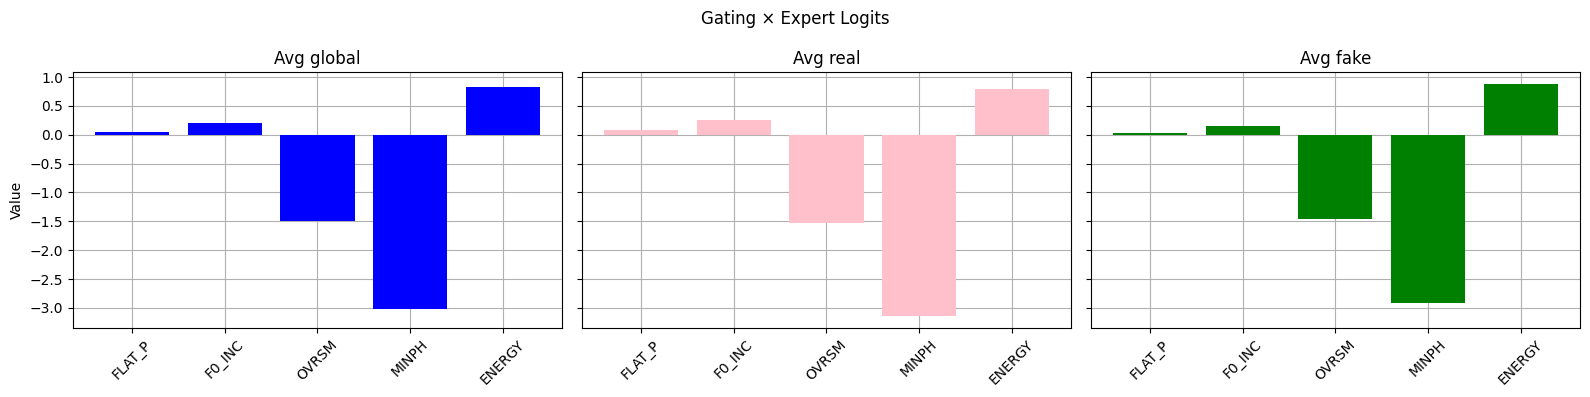

-----------------------------------
A08

Individual Experts' Performance:
AUC: 47.02%, EER: 53.41%
AUC: 40.36%, EER: 57.33%
AUC: 51.24%, EER: 49.40%
AUC: 53.43%, EER: 47.09%
AUC: 65.28%, EER: 38.64%

MoE Performance:
AUC: 55.95%, EER: 45.95%


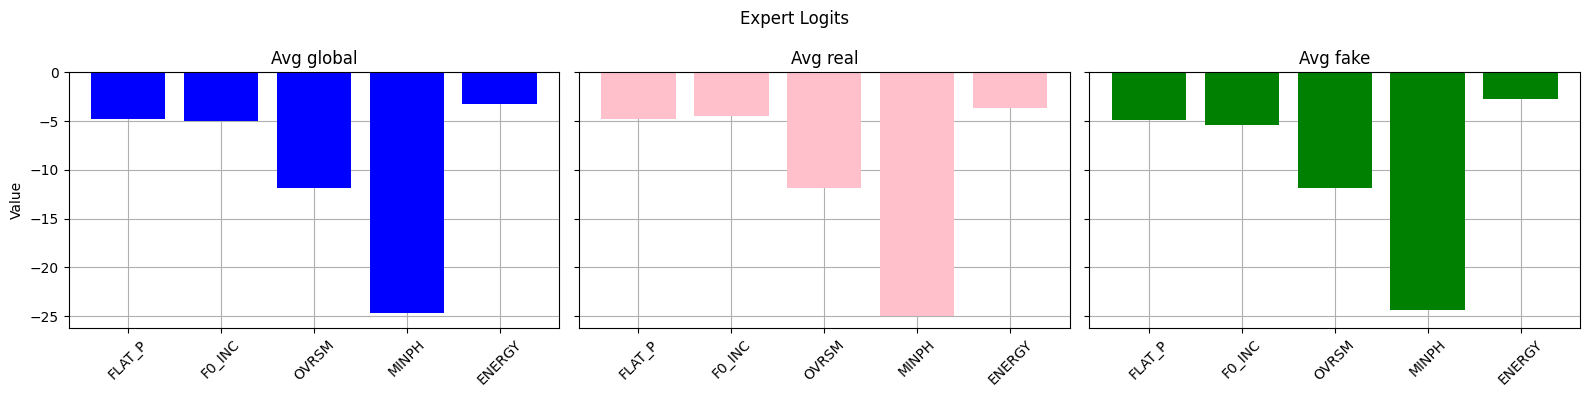

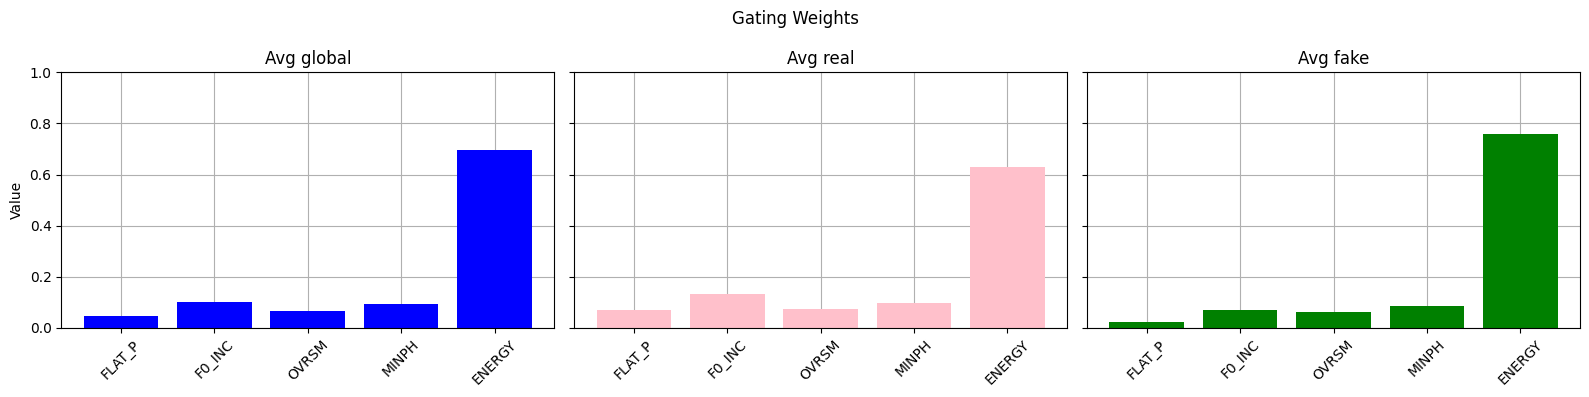

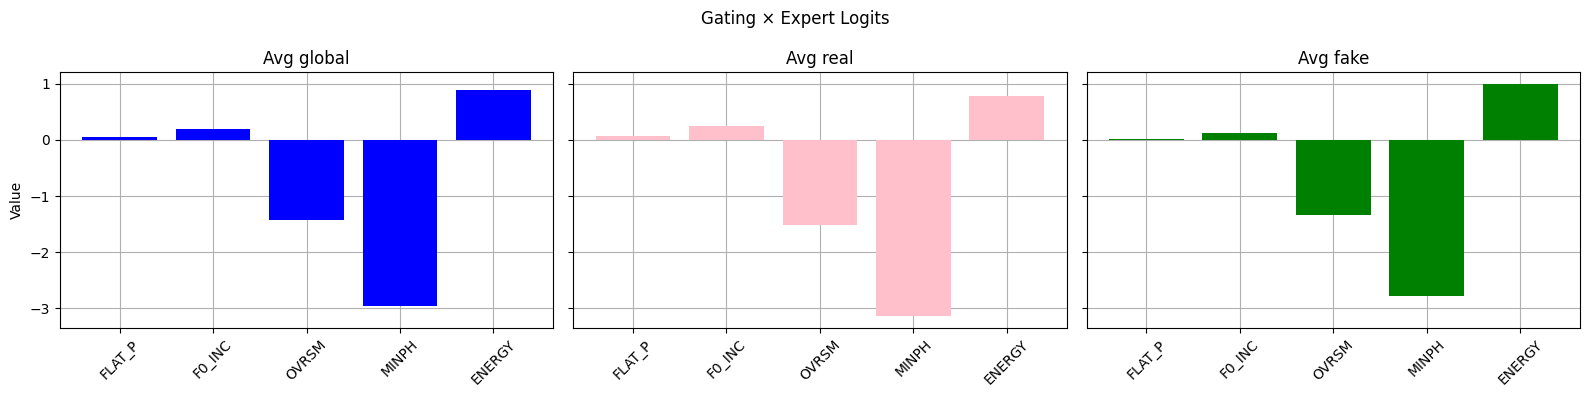

-----------------------------------
A09

Individual Experts' Performance:
AUC: 45.60%, EER: 54.52%
AUC: 44.26%, EER: 54.90%
AUC: 48.97%, EER: 51.20%
AUC: 60.52%, EER: 41.80%
AUC: 16.44%, EER: 77.31%

MoE Performance:
AUC: 16.36%, EER: 78.11%


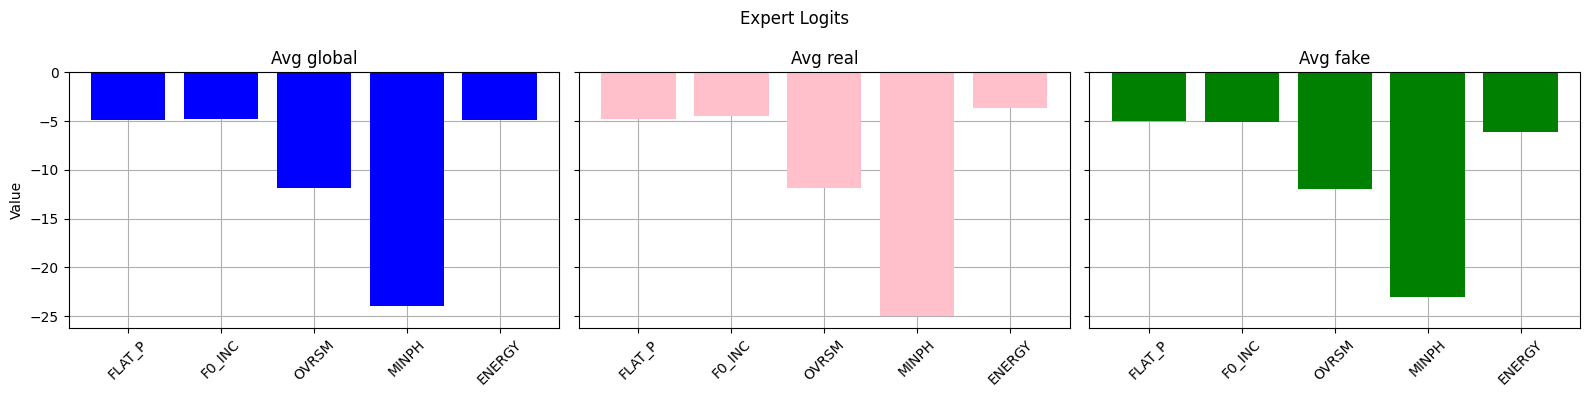

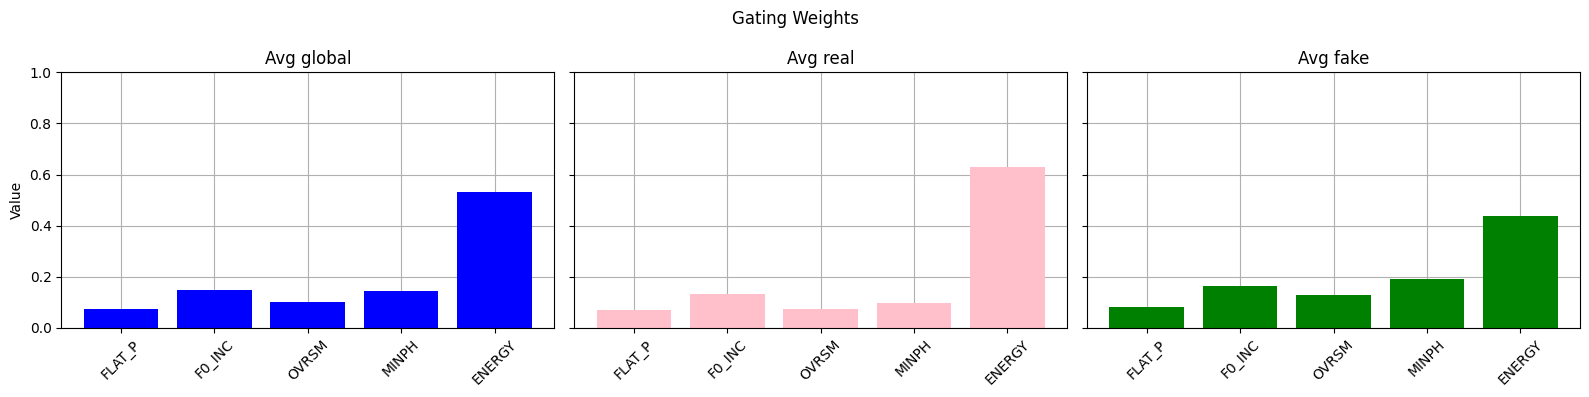

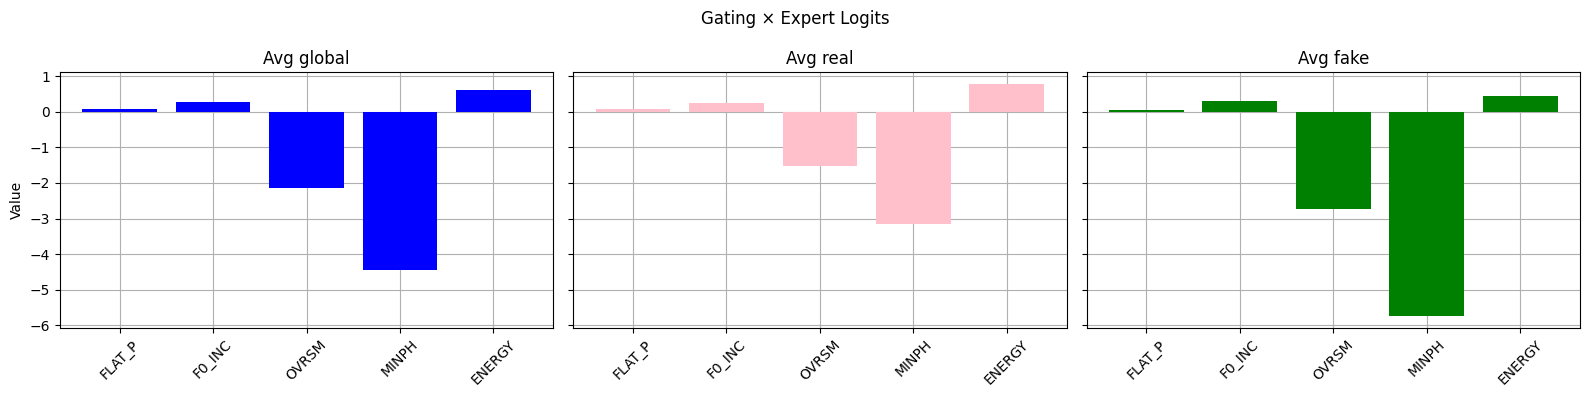

-----------------------------------
A10

Individual Experts' Performance:
AUC: 46.63%, EER: 53.82%
AUC: 45.12%, EER: 53.70%
AUC: 46.83%, EER: 52.00%
AUC: 62.16%, EER: 41.40%
AUC: 15.62%, EER: 78.92%

MoE Performance:
AUC: 16.56%, EER: 77.90%


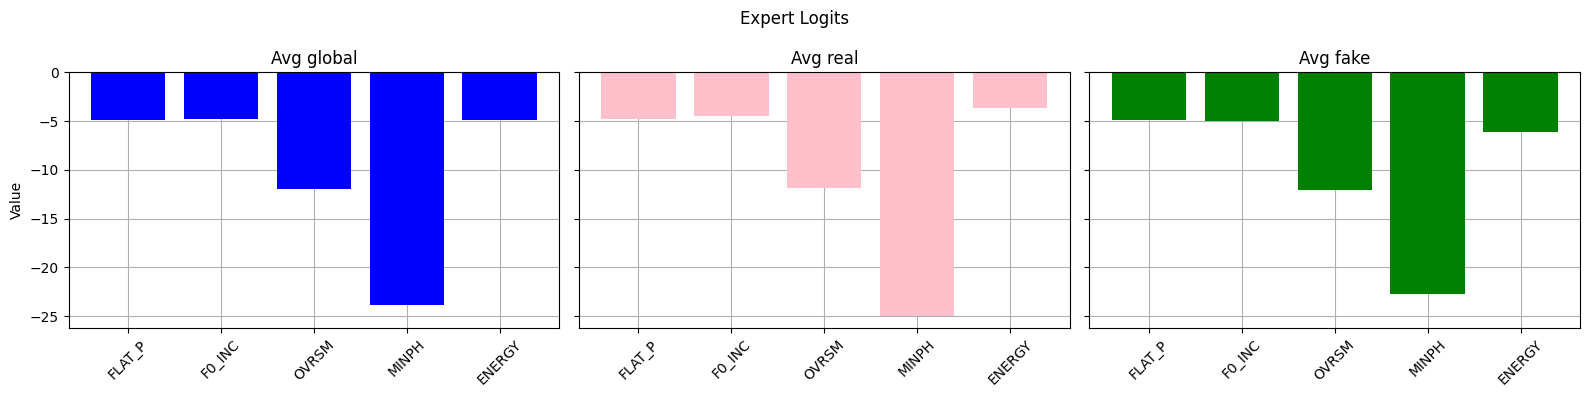

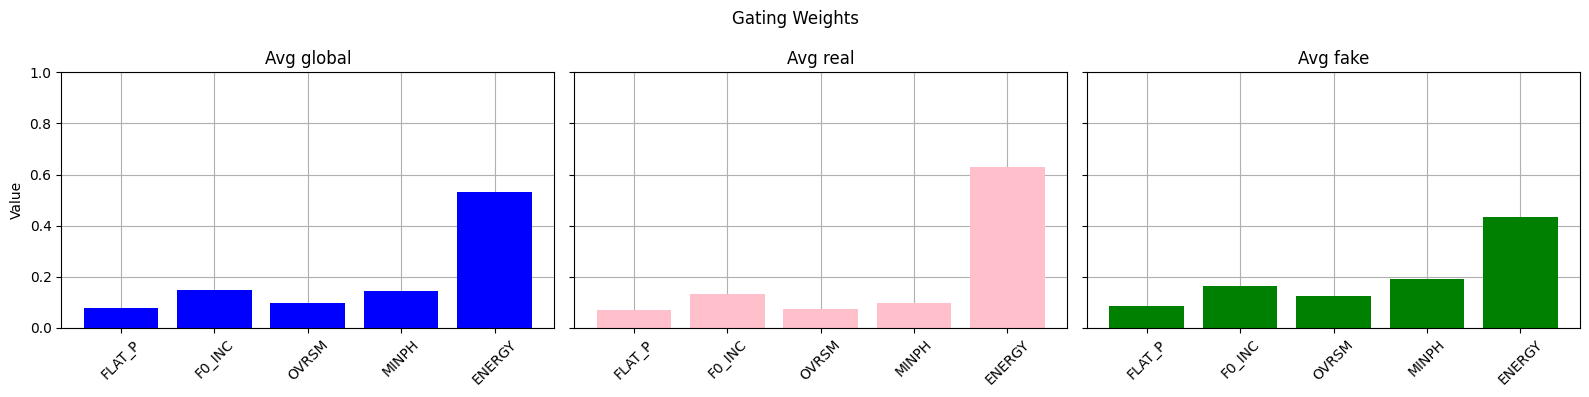

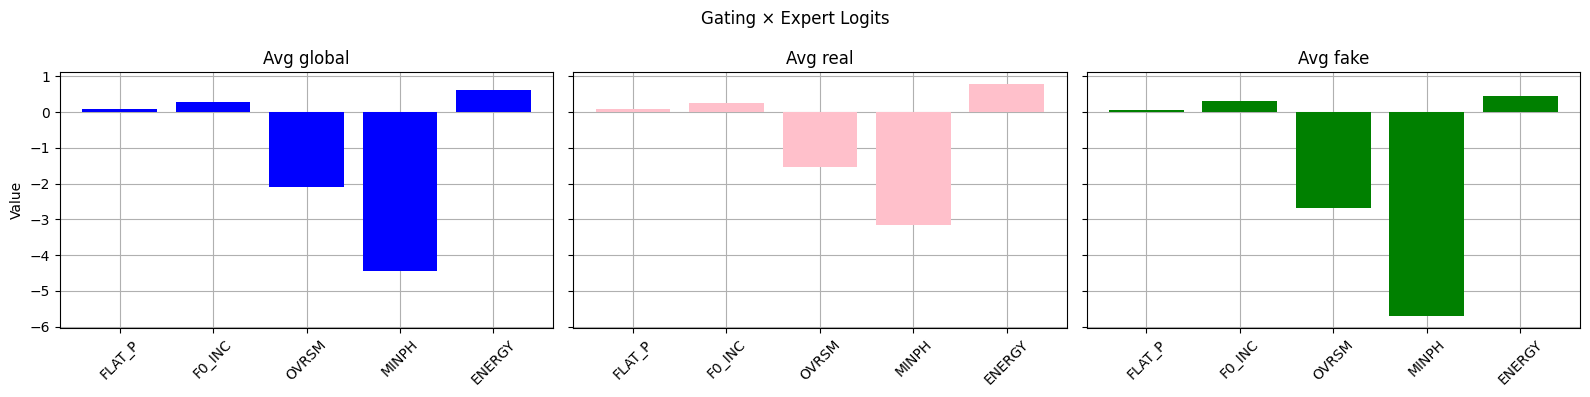

-----------------------------------
A11

Individual Experts' Performance:
AUC: 52.49%, EER: 48.97%
AUC: 54.01%, EER: 47.13%
AUC: 47.77%, EER: 51.61%
AUC: 32.69%, EER: 62.11%
AUC: 84.00%, EER: 25.77%

MoE Performance:
AUC: 76.57%, EER: 31.93%


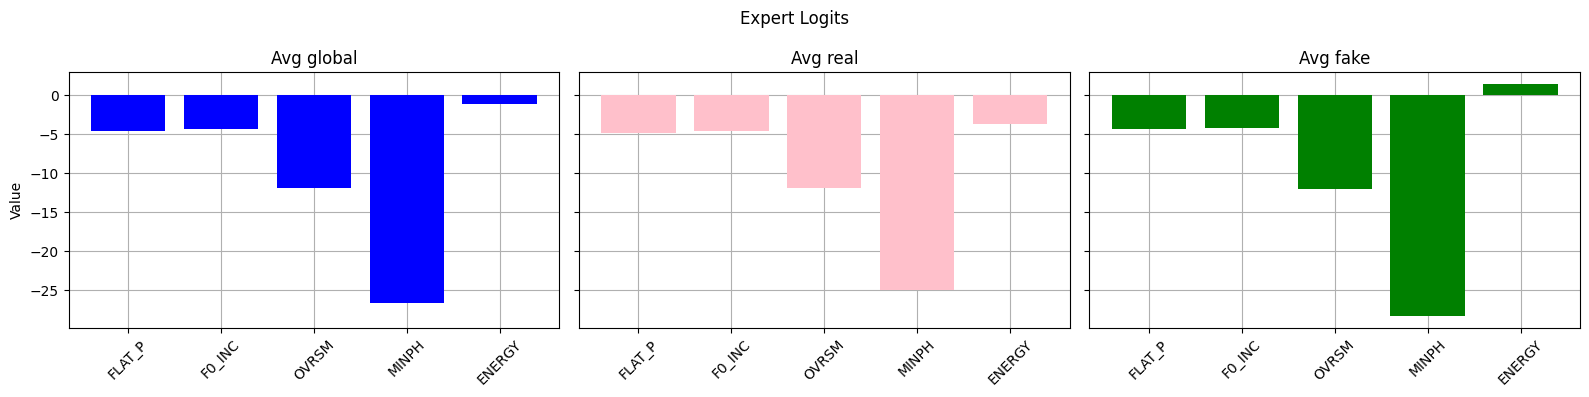

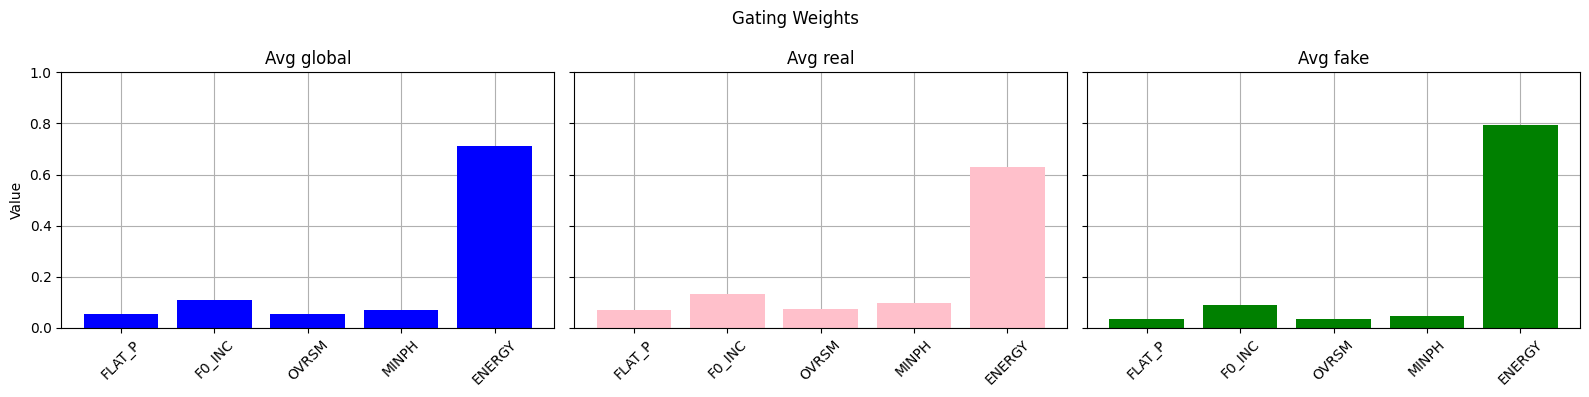

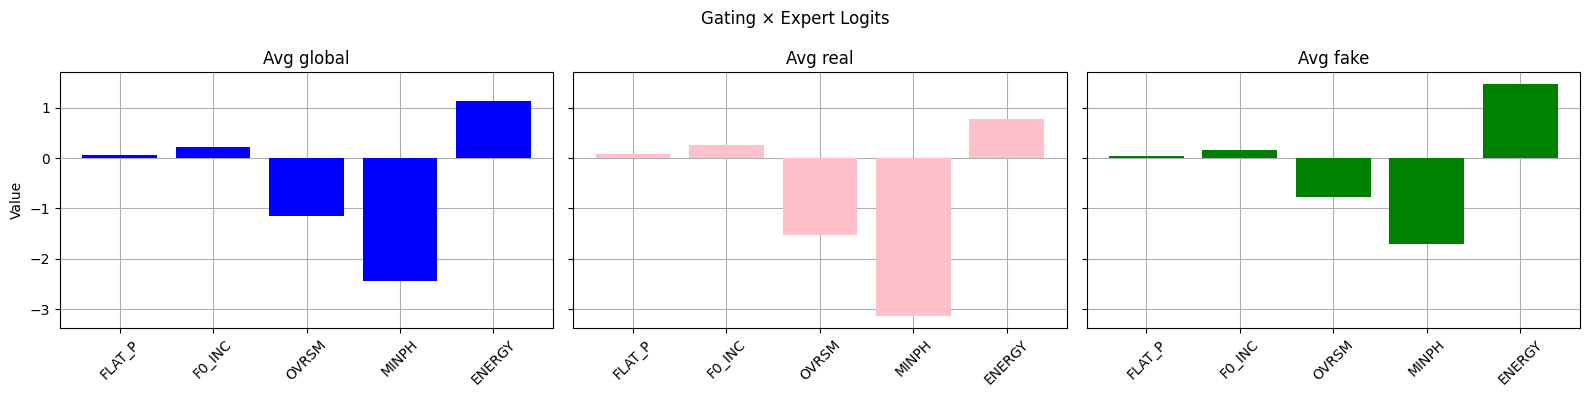

-----------------------------------
A12

Individual Experts' Performance:
AUC: 67.74%, EER: 36.97%
AUC: 92.70%, EER: 14.93%
AUC: 43.14%, EER: 55.01%
AUC: 17.87%, EER: 74.55%
AUC: 89.37%, EER: 17.43%

MoE Performance:
AUC: 85.48%, EER: 22.34%


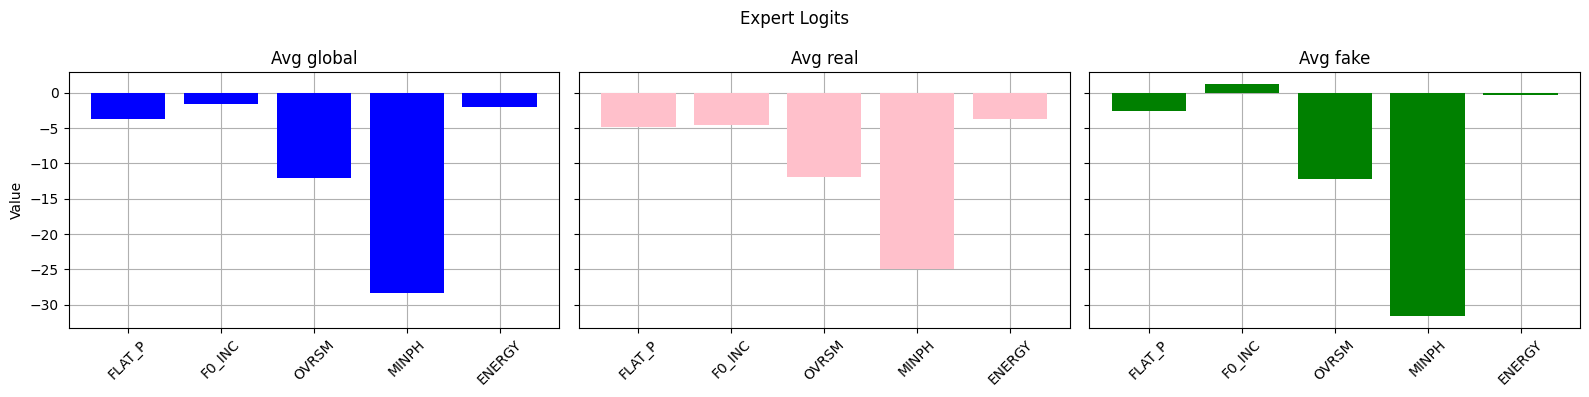

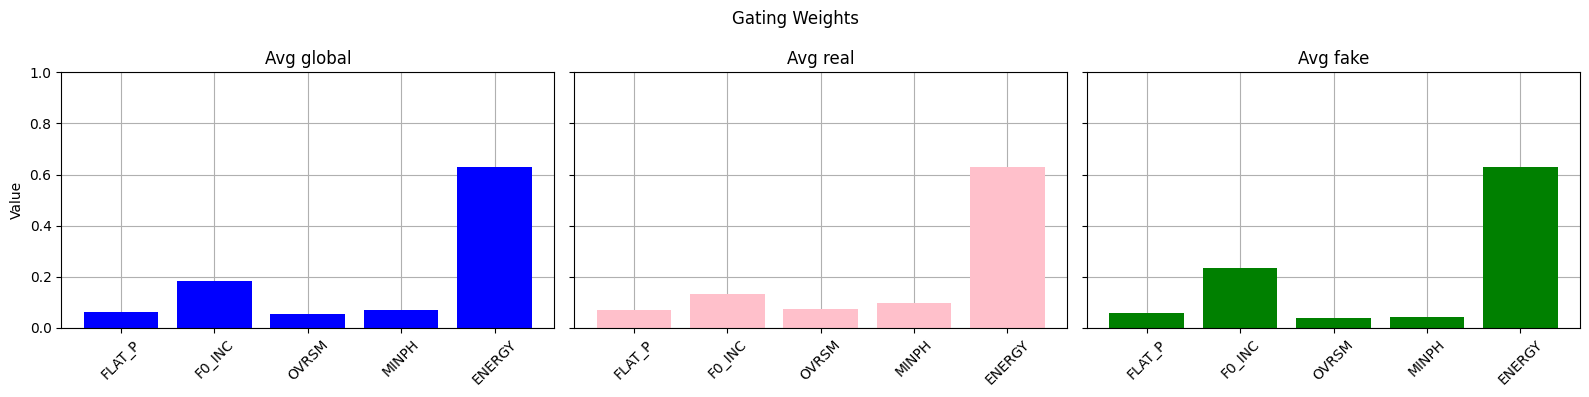

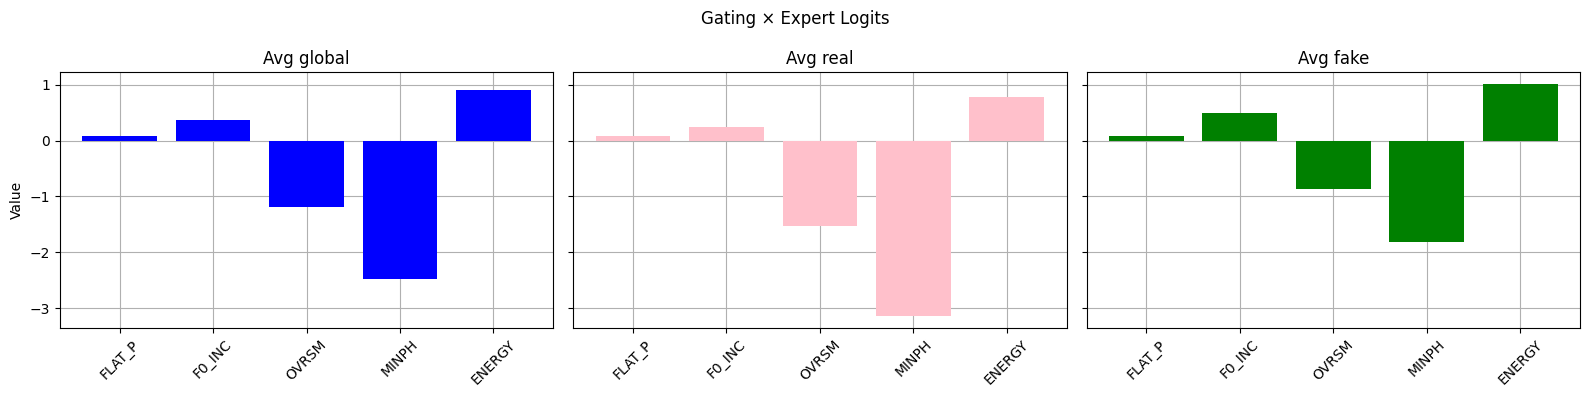

-----------------------------------
A14

Individual Experts' Performance:
AUC: 76.92%, EER: 28.80%
AUC: 84.84%, EER: 24.00%
AUC: 45.97%, EER: 54.12%
AUC: 50.02%, EER: 49.60%
AUC: 90.70%, EER: 16.67%

MoE Performance:
AUC: 93.78%, EER: 14.40%


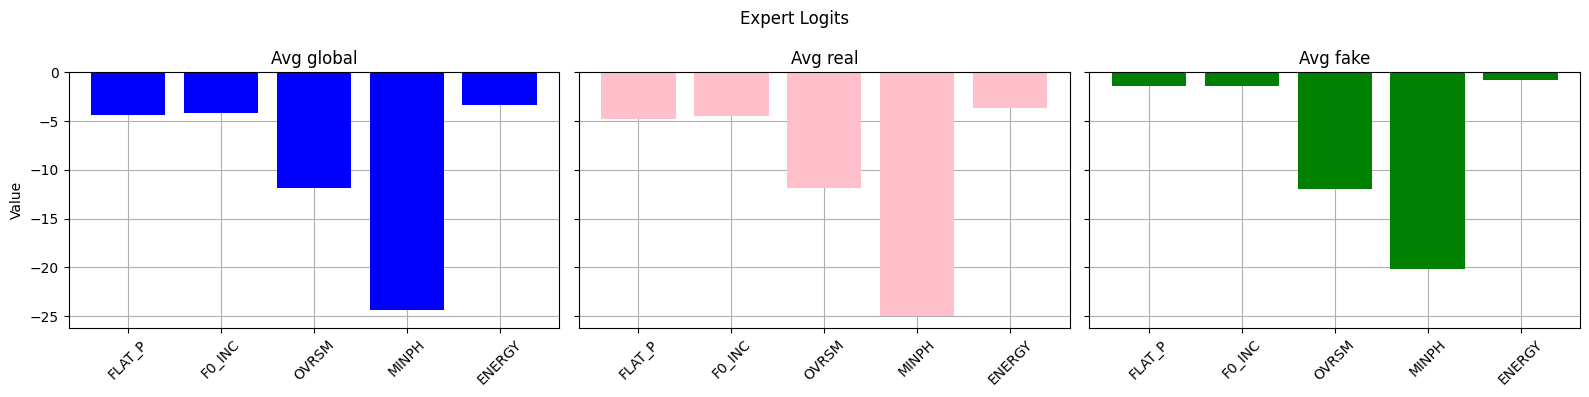

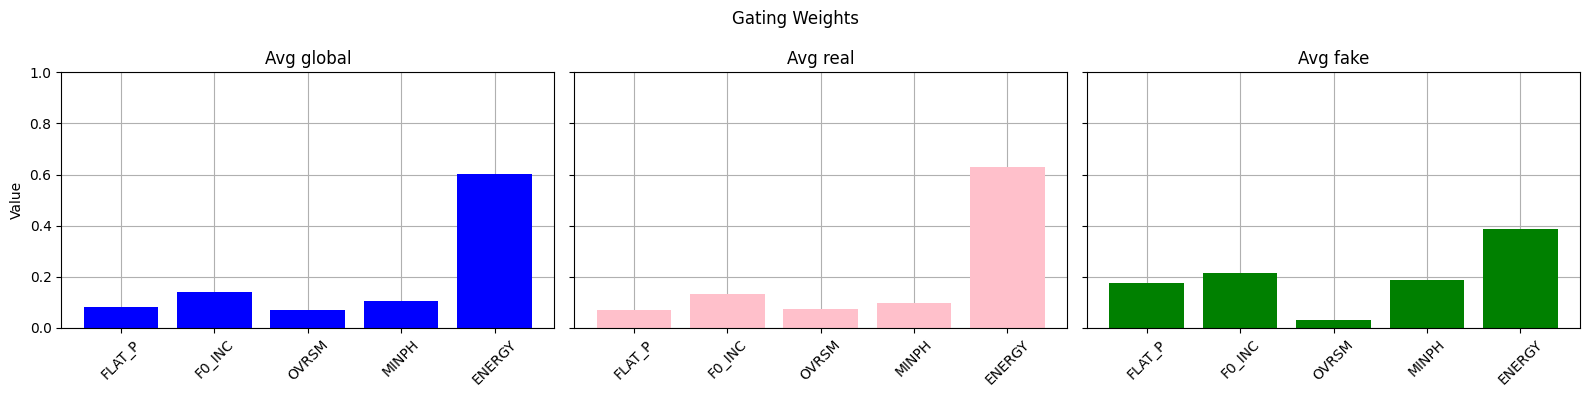

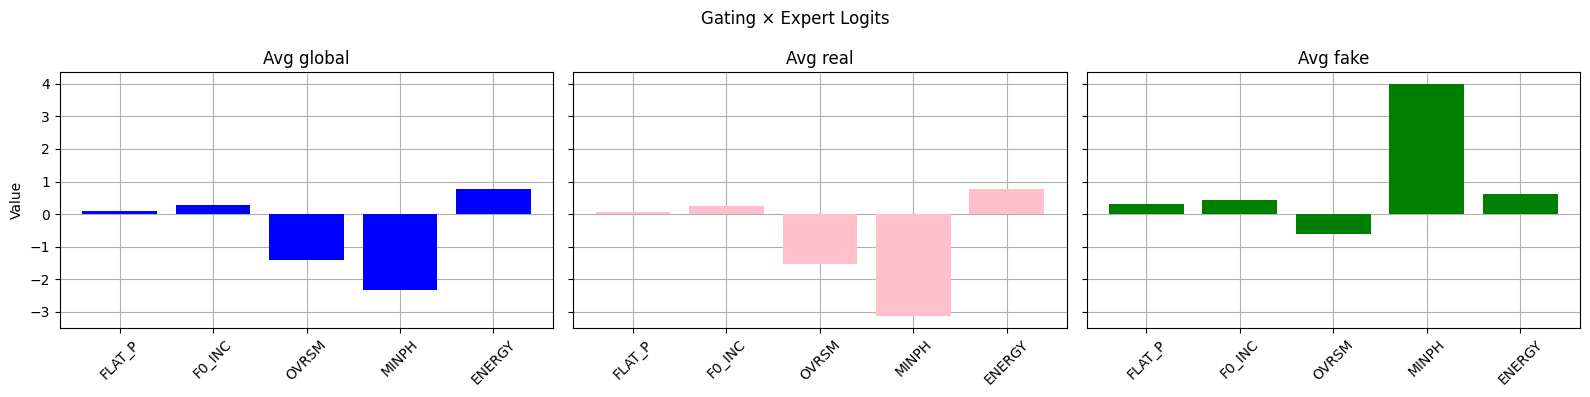

-----------------------------------


In [4]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/TargetCheck/{g}"
    model_name = "asv5_frozen_5_exp_calib"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=True)
    print("-----------------------------------")

## Test on ASV 19

### Overall performance


Individual Experts' Performance:
AUC: 39.28%, EER: 58.02%
AUC: 34.22%, EER: 61.21%
AUC: 65.36%, EER: 37.51%
AUC: 71.19%, EER: 34.94%
AUC: 66.96%, EER: 37.22%

MoE Performance:
AUC: 57.19%, EER: 45.75%
Loaded 19171 samples
Real mean score: -2.6731
Fake mean score: -2.4167



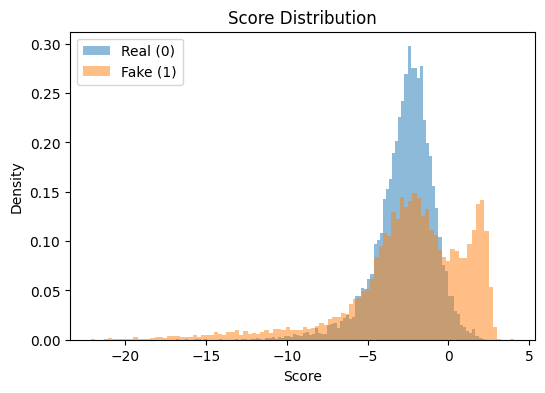

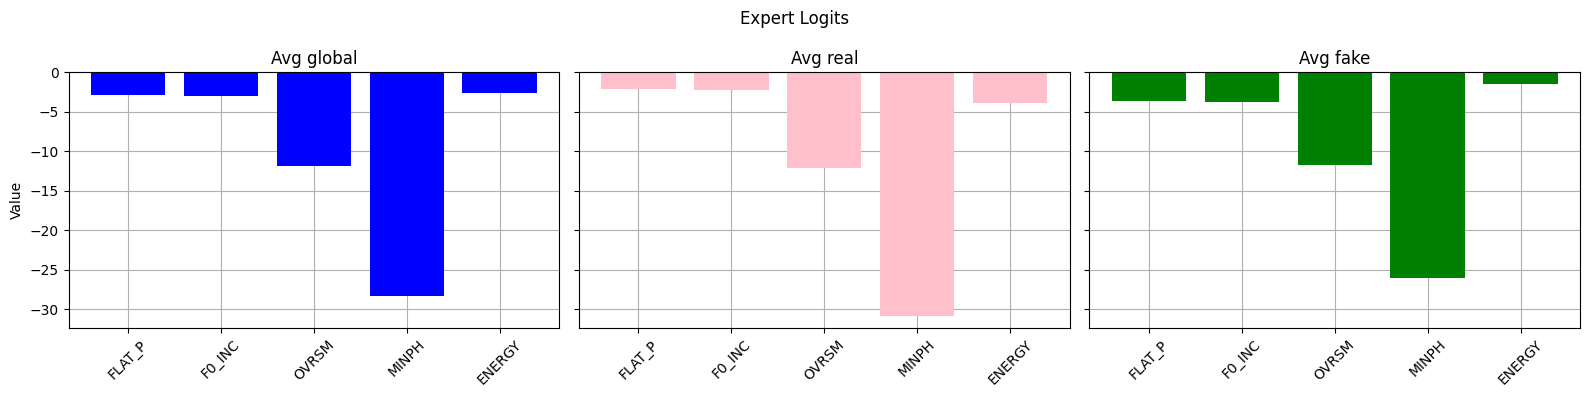

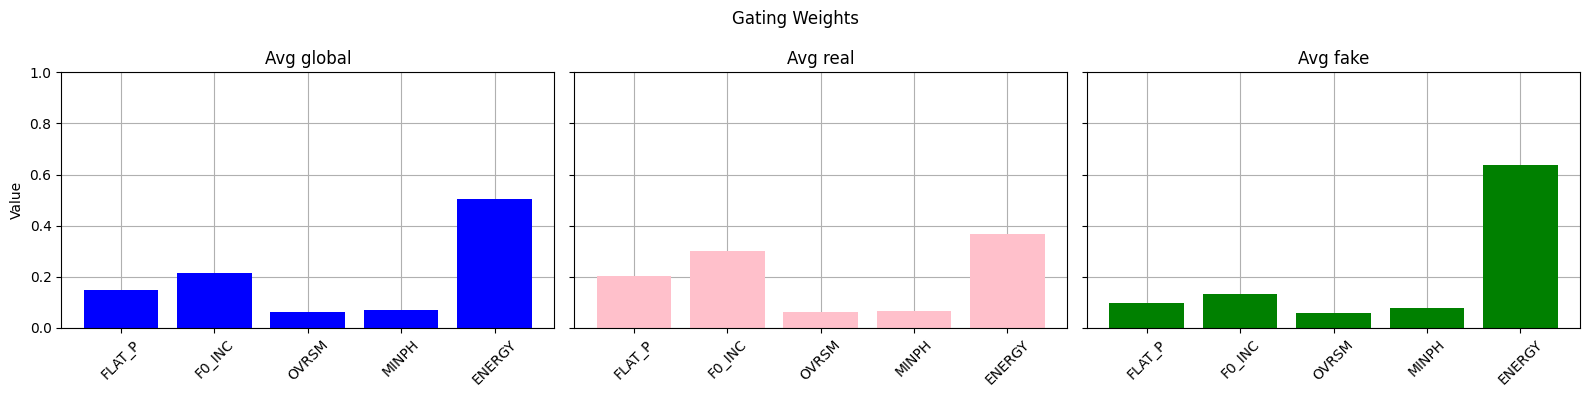

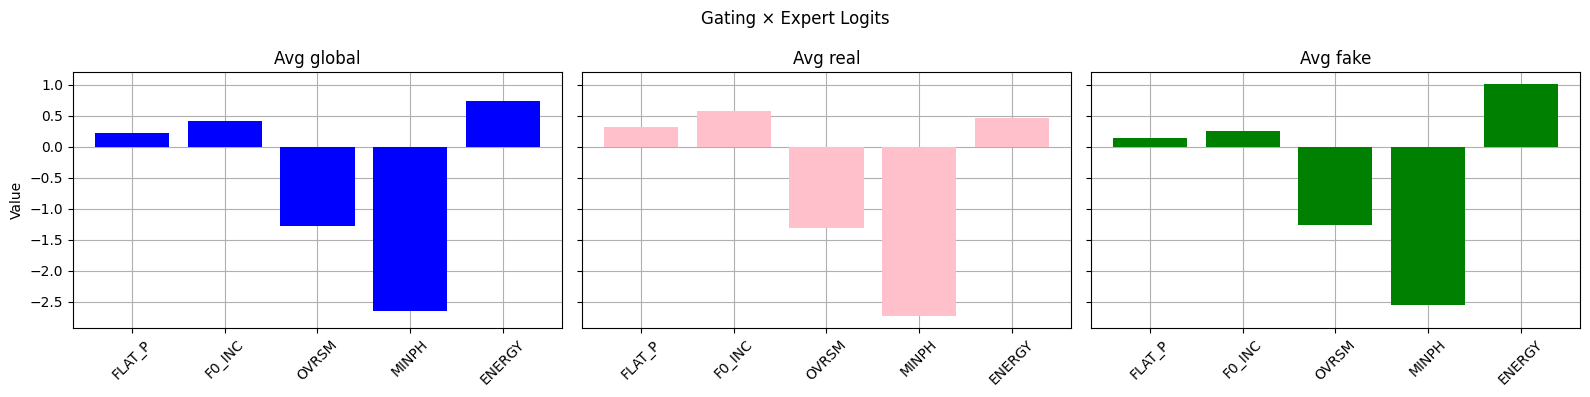

In [7]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv19/TargetCheck/ALL"
model_name = "asv5_frozen_5_exp_calib"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

# MoE-asv19 on Wavefake

In [30]:
generator_list = ["tts_ljspeech", "ljspeech_full_band_melgan", "ljspeech_hifiGAN", "ljspeech_melgan",
                                  "ljspeech_melgan_large", "ljspeech_multi_band_melgan", "ljspeech_parallel_wavegan",
                                  "ljspeech_waveglow"]
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/wf/TargetCheck/{g}"
    model_name = "asv5_frozen_5_exp_calib"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=False)
    print("-----------------------------------")

tts_ljspeech

Individual Experts' Performance:
AUC: 41.47%, EER: 57.40%
AUC: 49.99%, EER: 49.10%
AUC: 53.55%, EER: 47.70%
AUC: 75.19%, EER: 32.40%
AUC: 55.21%, EER: 46.70%

MoE Performance:
AUC: 48.03%, EER: 51.40%
-----------------------------------
ljspeech_full_band_melgan

Individual Experts' Performance:
AUC: 47.64%, EER: 52.20%
AUC: 52.90%, EER: 46.90%
AUC: 52.55%, EER: 48.80%
AUC: 49.95%, EER: 52.20%
AUC: 43.83%, EER: 54.70%

MoE Performance:
AUC: 44.97%, EER: 54.00%
-----------------------------------
ljspeech_hifiGAN

Individual Experts' Performance:
AUC: 48.47%, EER: 51.60%
AUC: 53.29%, EER: 47.20%
AUC: 51.66%, EER: 48.90%
AUC: 58.60%, EER: 45.60%
AUC: 47.96%, EER: 52.50%

MoE Performance:
AUC: 49.60%, EER: 50.30%
-----------------------------------
ljspeech_melgan

Individual Experts' Performance:
AUC: 49.75%, EER: 50.90%
AUC: 51.20%, EER: 49.00%
AUC: 53.56%, EER: 47.80%
AUC: 61.28%, EER: 43.60%
AUC: 37.80%, EER: 58.70%

MoE Performance:
AUC: 43.22%, EER: 55.70%
------------

# MoE-asv19 on MLAAD (eng)

In [31]:
generator_list = ['Mars5', 'MatchaTTS', 'MeloTTS', 'Metavoice-1B', 'OpenVoiceV2', 'WhisperSpeech', 'e2-tts',
                                  'f5-tts', 'facebook_mms-tts-eng', 'griffin_lim', 'microsoft_speecht5_tts', 'optispeech',
                                  'parler_tts_large_v1', 'parler_tts_mini_v0.1', 'parler_tts_mini_v1', 'suno_bark-small',
                                  'suno_bark', 'tts_models_en_blizzard2013_capacitron-t2-c50', 'tts_models_en_ek1_tacotron2',
                                  'tts_models_en_jenny_jenny', 'tts_models_en_ljspeech_fast_pitch', 'tts_models_en_ljspeech_glow-tts',
                                  'tts_models_en_ljspeech_neural_hmm', 'tts_models_en_ljspeech_overflow', 'tts_models_en_ljspeech_speedy-speech',
                                  'tts_models_en_ljspeech_tacotron2-DCA', 'tts_models_en_ljspeech_tacotron2-DDC', 'tts_models_en_ljspeech_tacotron2-DDC_ph',
                                  'tts_models_en_ljspeech_vits--neon', 'tts_models_en_ljspeech_vits', 'tts_models_en_multi-dataset_tortoise-v2',
                                  'tts_models_en_sam_tacotron-DDC', 'tts_models_multilingual_multi-dataset_bark', 'tts_models_multilingual_multi-dataset_xtts_v1.1',
                                  'tts_models_multilingual_multi-dataset_xtts_v2', 'vixTTS']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/mlaad/TargetCheck/{g}"
    model_name = "asv5_frozen_5_exp_calib"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=False)
    print("-----------------------------------")

Mars5

Individual Experts' Performance:
AUC: 45.26%, EER: 53.38%
AUC: 39.13%, EER: 60.07%
AUC: 59.78%, EER: 43.92%
AUC: 52.49%, EER: 47.44%
AUC: 33.19%, EER: 64.53%

MoE Performance:
AUC: 39.97%, EER: 57.09%
-----------------------------------
MatchaTTS

Individual Experts' Performance:
AUC: 57.51%, EER: 43.99%
AUC: 46.95%, EER: 53.67%
AUC: 53.32%, EER: 49.00%
AUC: 70.51%, EER: 34.71%
AUC: 46.39%, EER: 52.23%

MoE Performance:
AUC: 46.42%, EER: 50.33%
-----------------------------------
MeloTTS

Individual Experts' Performance:
AUC: 52.32%, EER: 47.83%
AUC: 52.64%, EER: 47.16%
AUC: 58.35%, EER: 44.15%
AUC: 65.41%, EER: 38.80%
AUC: 40.42%, EER: 59.52%

MoE Performance:
AUC: 54.84%, EER: 45.24%
-----------------------------------
Metavoice-1B

Individual Experts' Performance:
AUC: 48.17%, EER: 50.17%
AUC: 53.36%, EER: 46.49%
AUC: 40.95%, EER: 57.58%
AUC: 49.82%, EER: 49.49%
AUC: 58.15%, EER: 45.12%

MoE Performance:
AUC: 68.83%, EER: 34.78%
-----------------------------------
OpenVoiceV2

# MoE WIFS_v3 - "way 2"


Individual Experts' Performance:
AUC: 57.80%, EER: 44.61%
AUC: 60.90%, EER: 42.30%
AUC: 48.81%, EER: 50.93%
AUC: 50.97%, EER: 48.68%
AUC: 56.14%, EER: 45.22%

MoE Performance:
AUC: 56.15%, EER: 45.83%
Loaded 25006 samples
Real mean score: -4.2368
Fake mean score: -3.1858



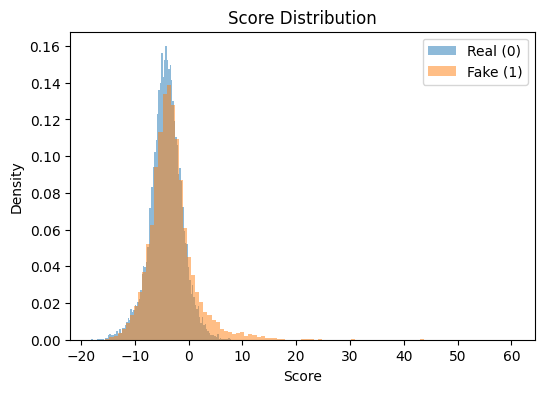

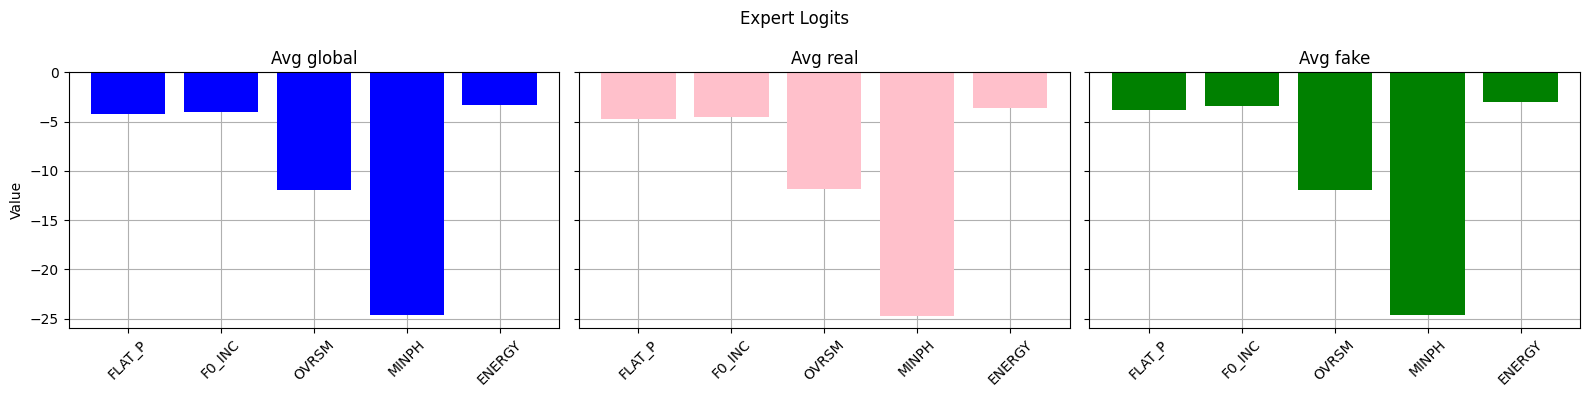

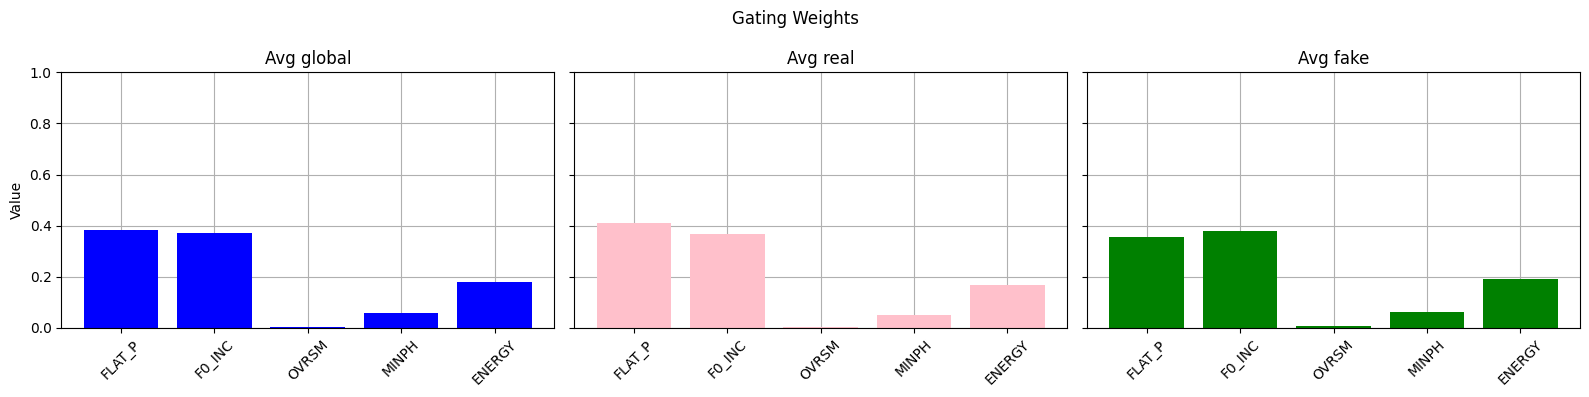

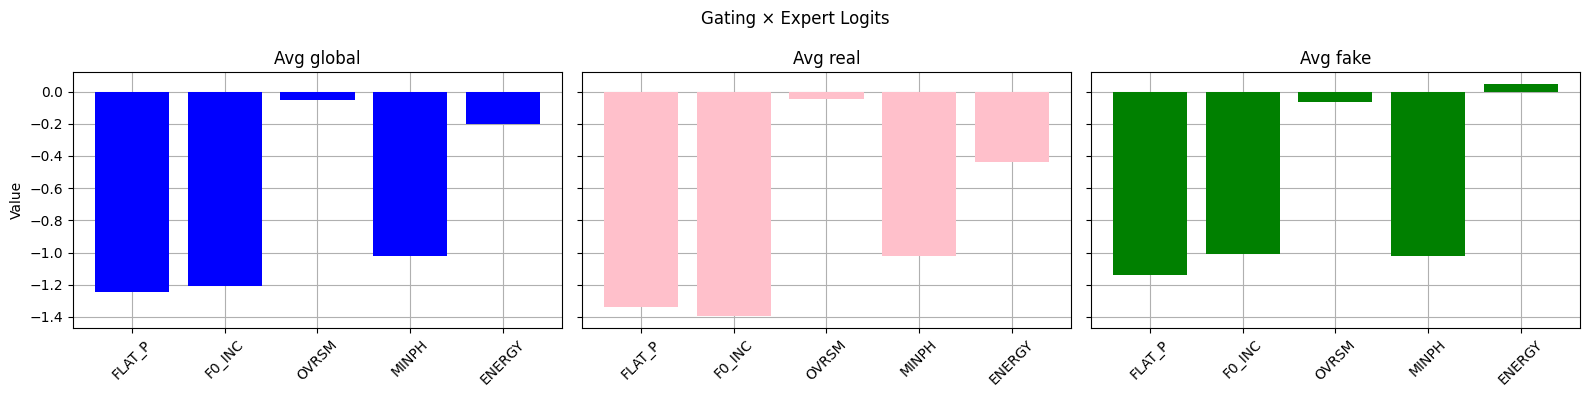

In [4]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/TargetCheck/ALL"
model_name = "asv5_frozen_5_exp_linear_comb"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
_, _, _ = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=True)

A01

Individual Experts' Performance:
AUC: 66.33%, EER: 37.95%
AUC: 72.63%, EER: 33.13%
AUC: 50.64%, EER: 50.40%
AUC: 49.86%, EER: 50.15%
AUC: 63.87%, EER: 39.46%

MoE Performance:
AUC: 65.77%, EER: 37.94%


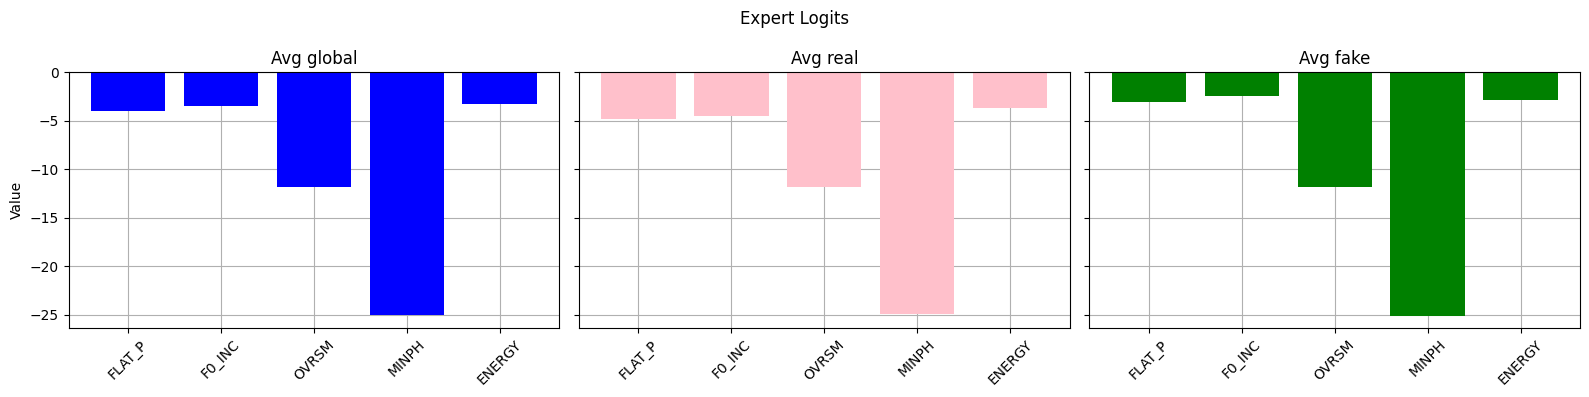

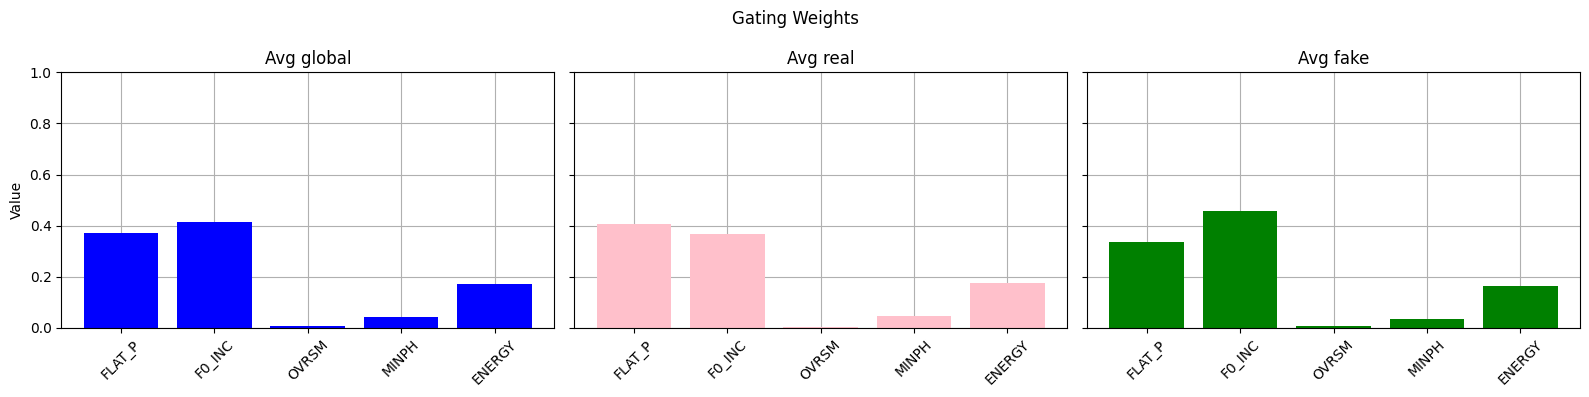

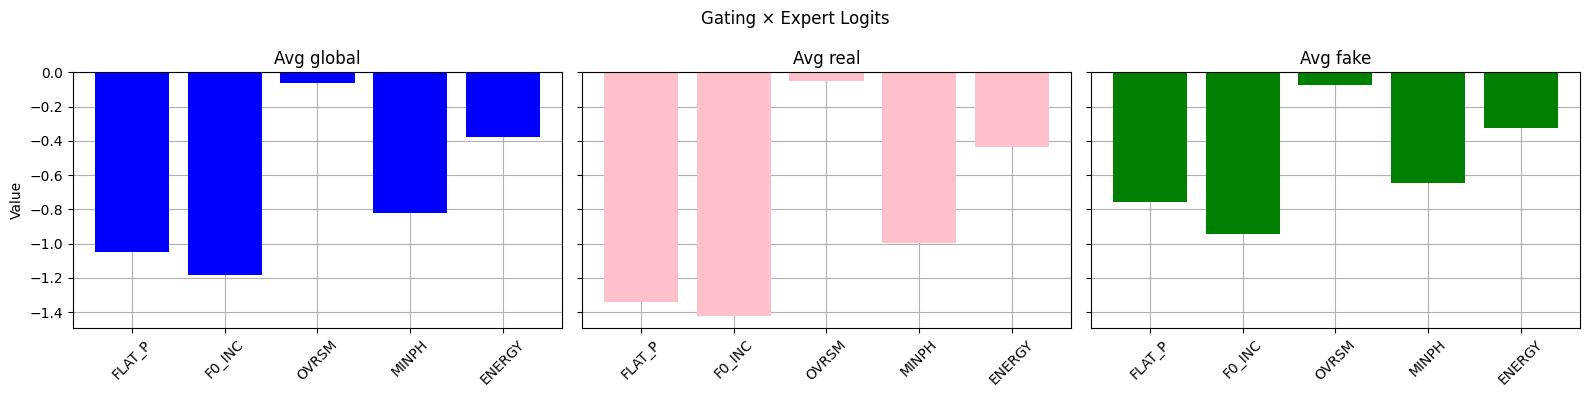

-----------------------------------
A02

Individual Experts' Performance:
AUC: 65.96%, EER: 37.95%
AUC: 70.69%, EER: 34.44%
AUC: 52.66%, EER: 48.20%
AUC: 48.88%, EER: 50.10%
AUC: 64.96%, EER: 38.90%

MoE Performance:
AUC: 64.73%, EER: 38.35%


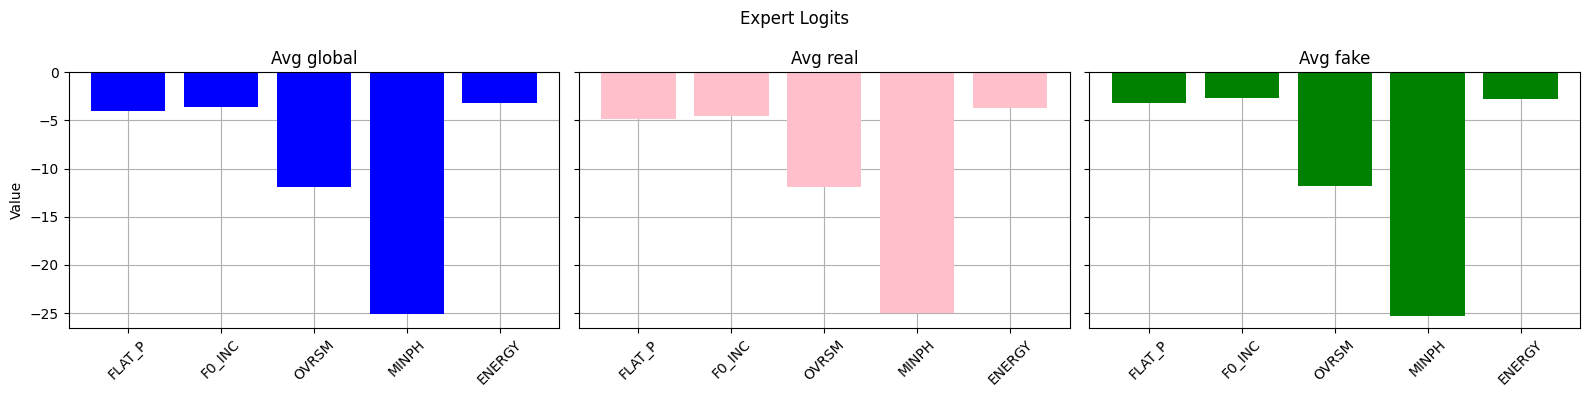

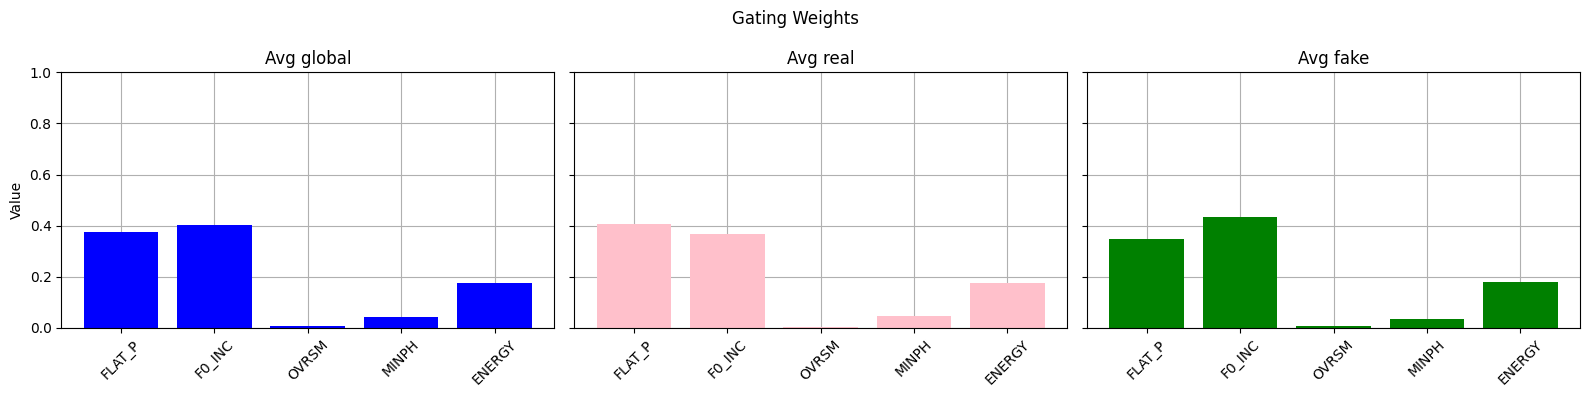

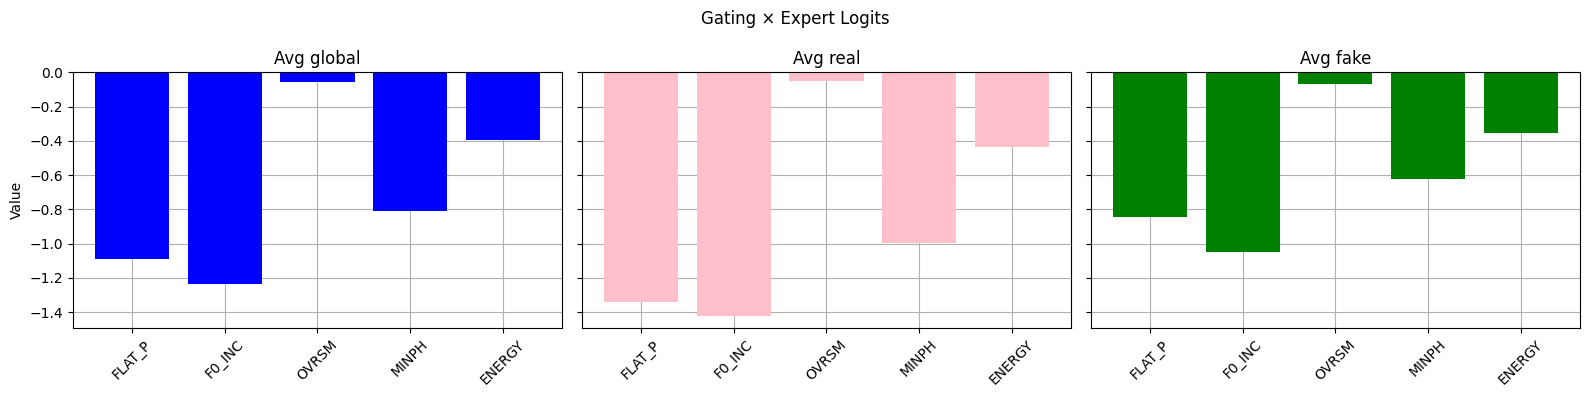

-----------------------------------
A03

Individual Experts' Performance:
AUC: 65.58%, EER: 39.00%
AUC: 68.01%, EER: 35.24%
AUC: 51.15%, EER: 49.50%
AUC: 58.70%, EER: 43.40%
AUC: 62.57%, EER: 40.00%

MoE Performance:
AUC: 60.21%, EER: 41.37%


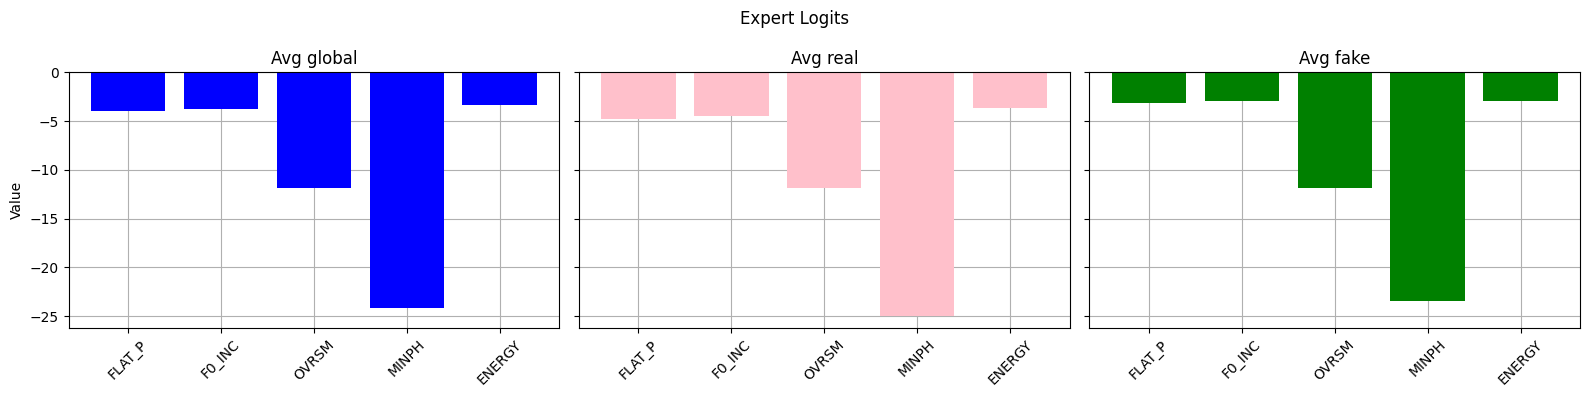

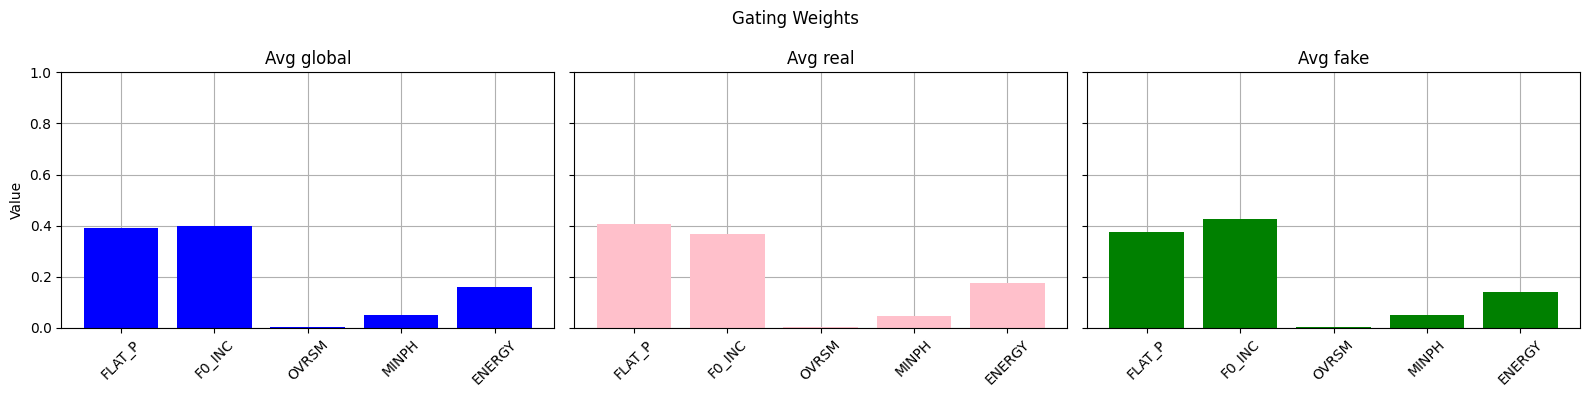

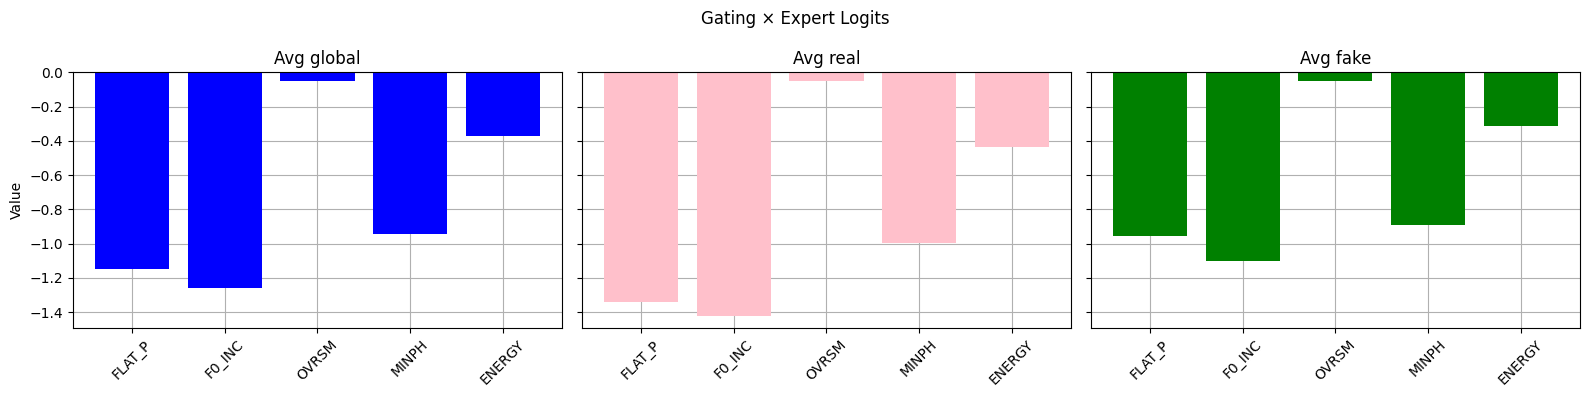

-----------------------------------
A04

Individual Experts' Performance:
AUC: 65.00%, EER: 38.65%
AUC: 68.26%, EER: 35.84%
AUC: 44.39%, EER: 53.48%
AUC: 57.25%, EER: 44.80%
AUC: 53.61%, EER: 47.43%

MoE Performance:
AUC: 57.17%, EER: 44.08%


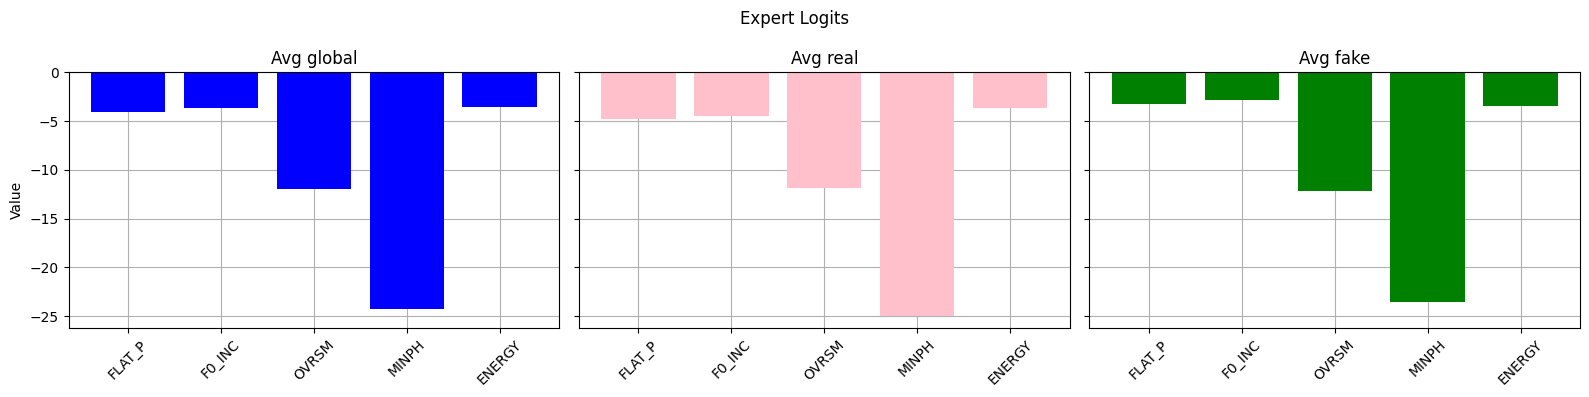

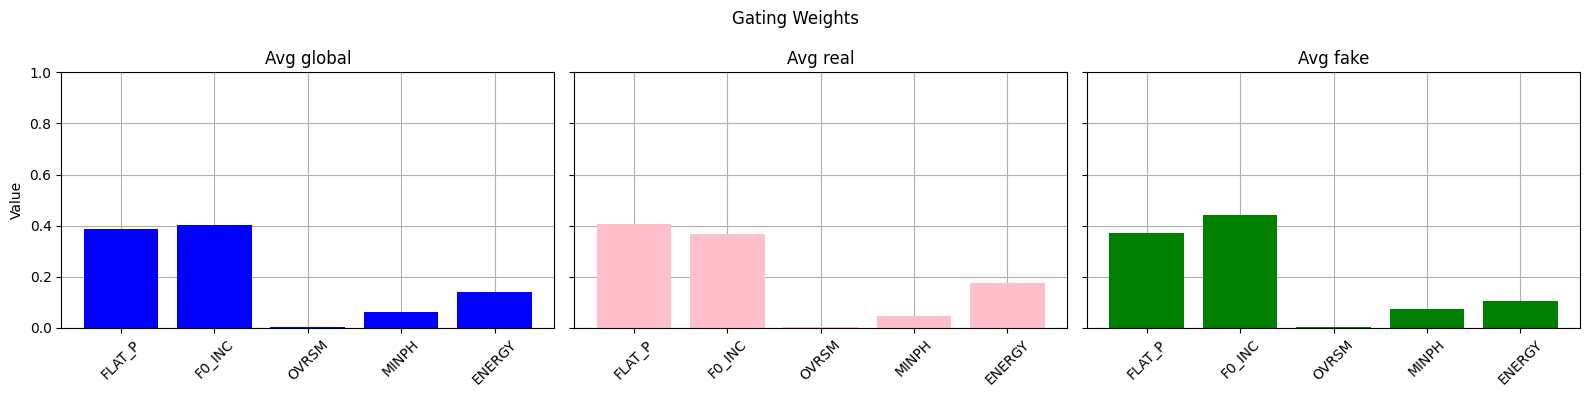

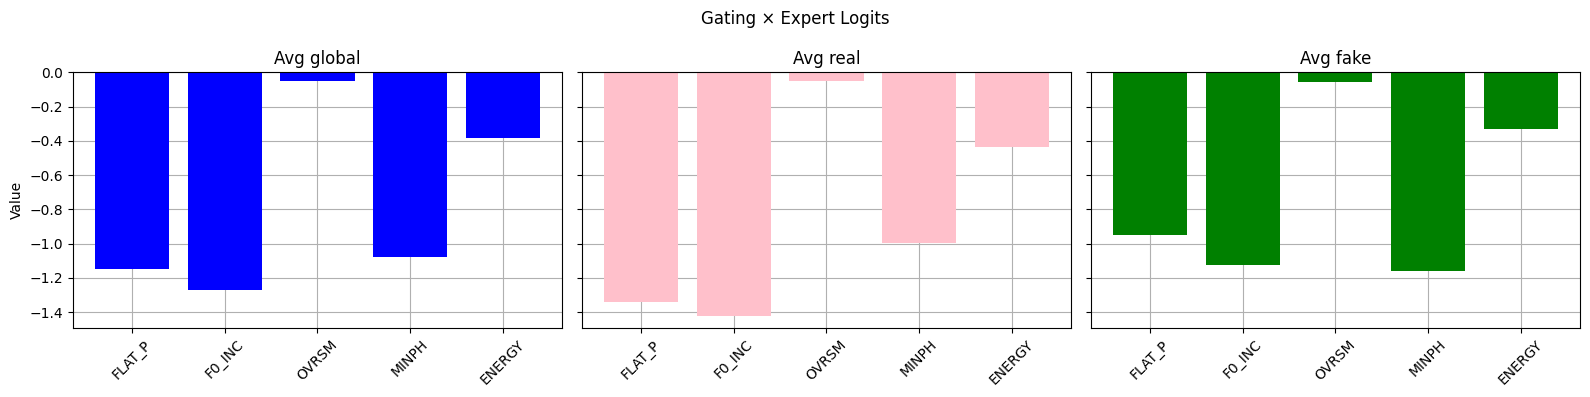

-----------------------------------
A05

Individual Experts' Performance:
AUC: 64.91%, EER: 38.45%
AUC: 67.80%, EER: 36.55%
AUC: 46.11%, EER: 52.51%
AUC: 60.55%, EER: 42.07%
AUC: 50.55%, EER: 50.30%

MoE Performance:
AUC: 55.56%, EER: 45.68%


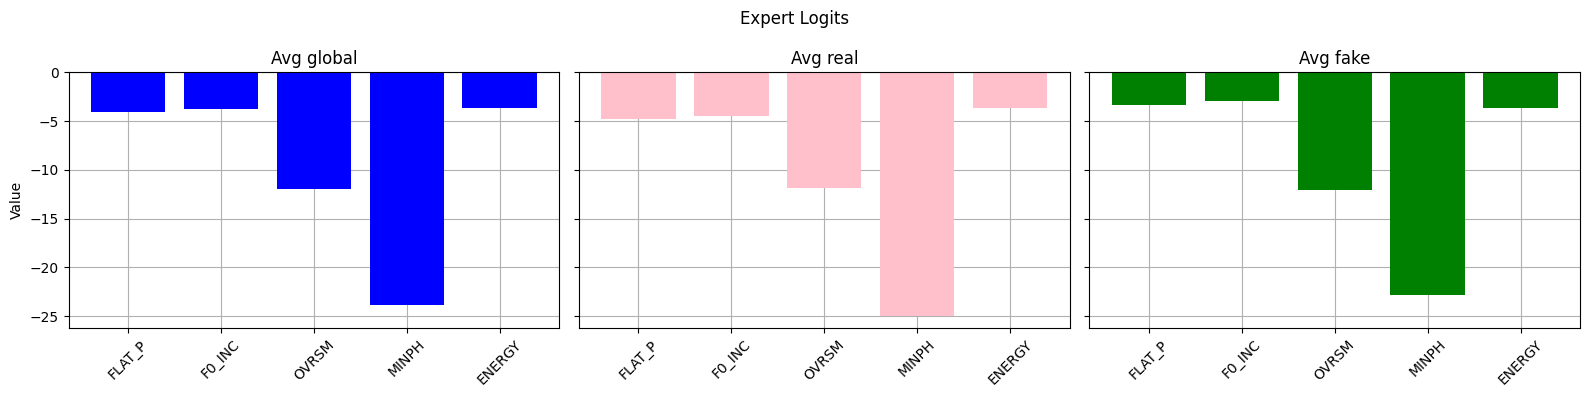

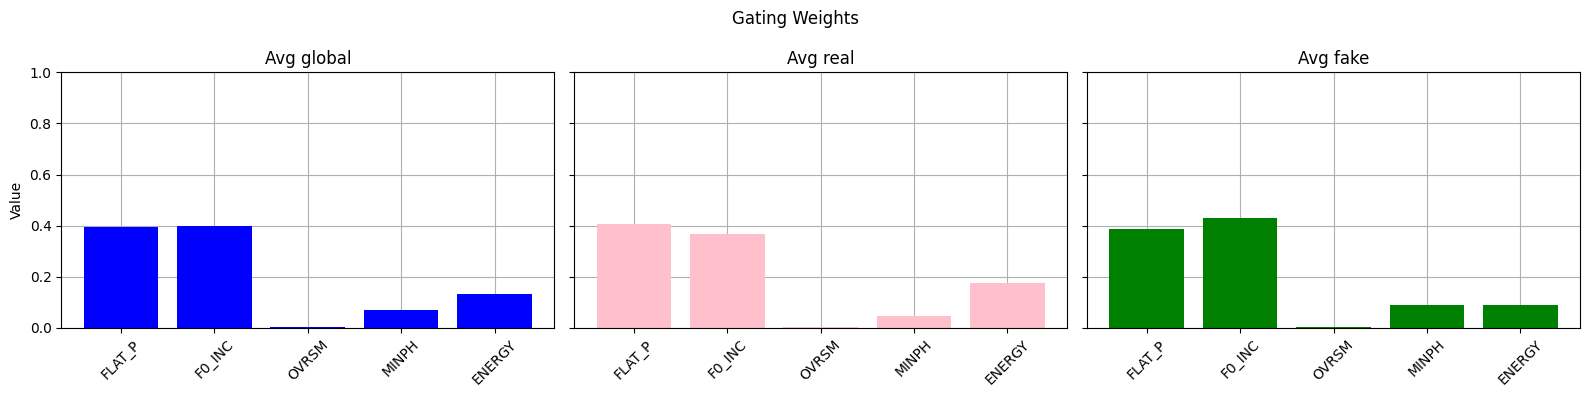

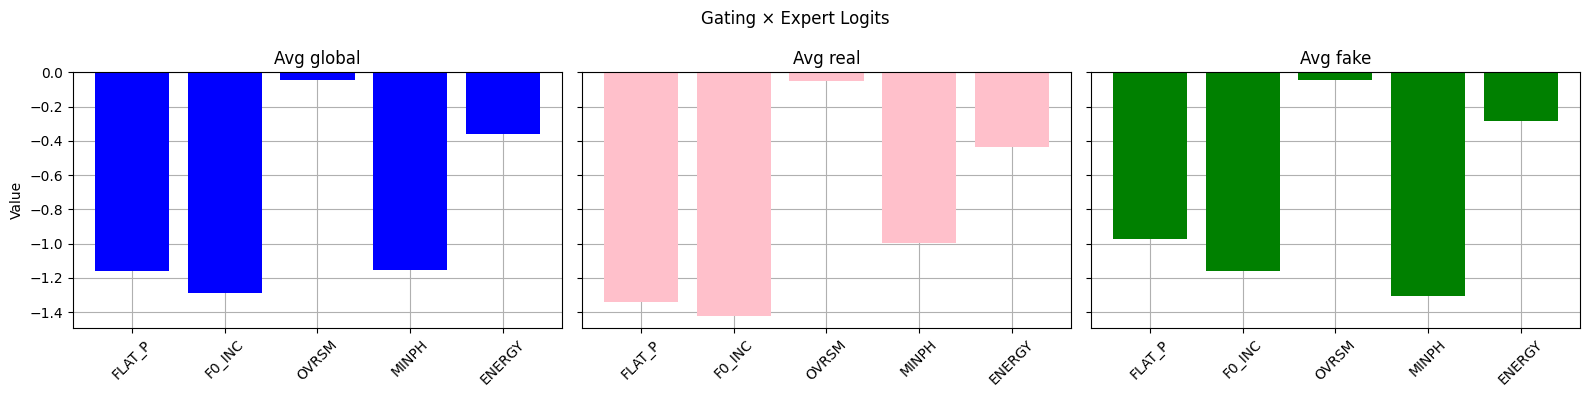

-----------------------------------
A06

Individual Experts' Performance:
AUC: 62.36%, EER: 40.16%
AUC: 64.45%, EER: 39.36%
AUC: 47.39%, EER: 51.81%
AUC: 52.82%, EER: 48.29%
AUC: 57.66%, EER: 44.48%

MoE Performance:
AUC: 56.40%, EER: 45.68%


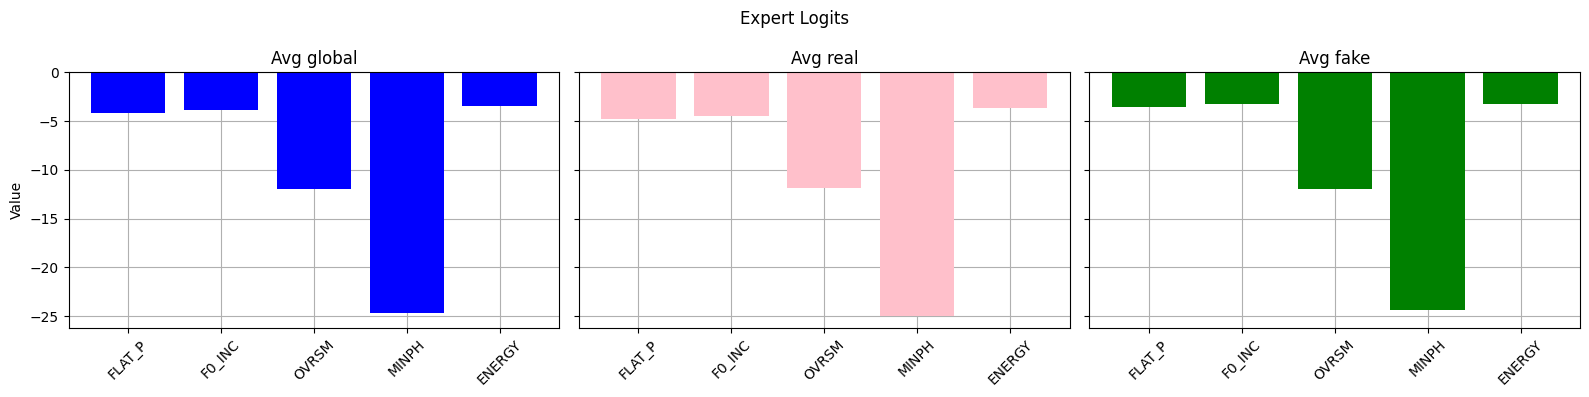

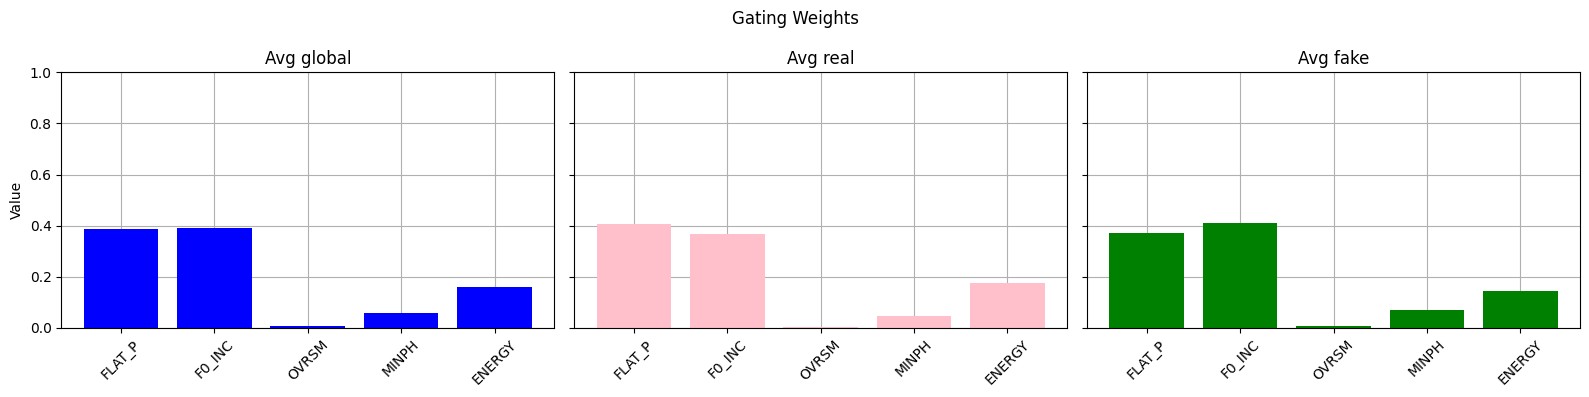

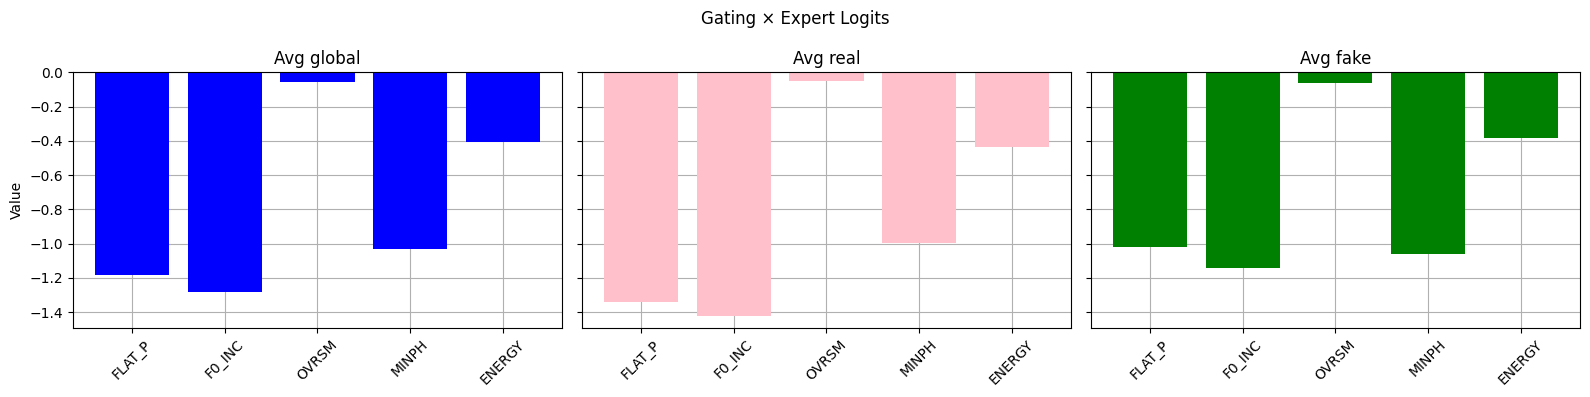

-----------------------------------
A07

Individual Experts' Performance:
AUC: 48.68%, EER: 51.75%
AUC: 38.88%, EER: 58.26%
AUC: 51.79%, EER: 49.45%
AUC: 74.26%, EER: 32.33%
AUC: 55.22%, EER: 46.25%

MoE Performance:
AUC: 32.89%, EER: 62.65%


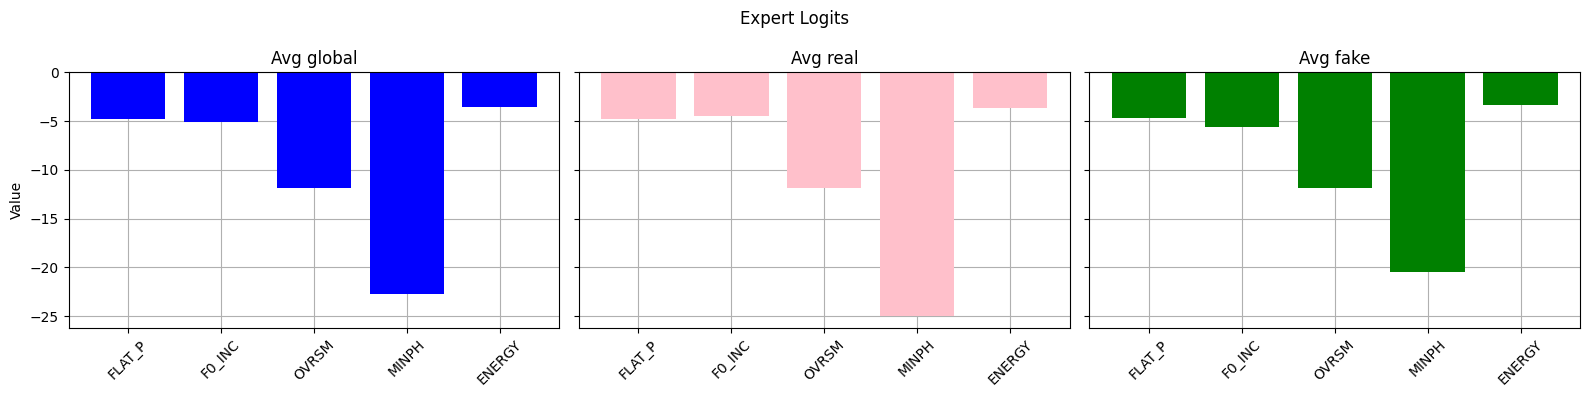

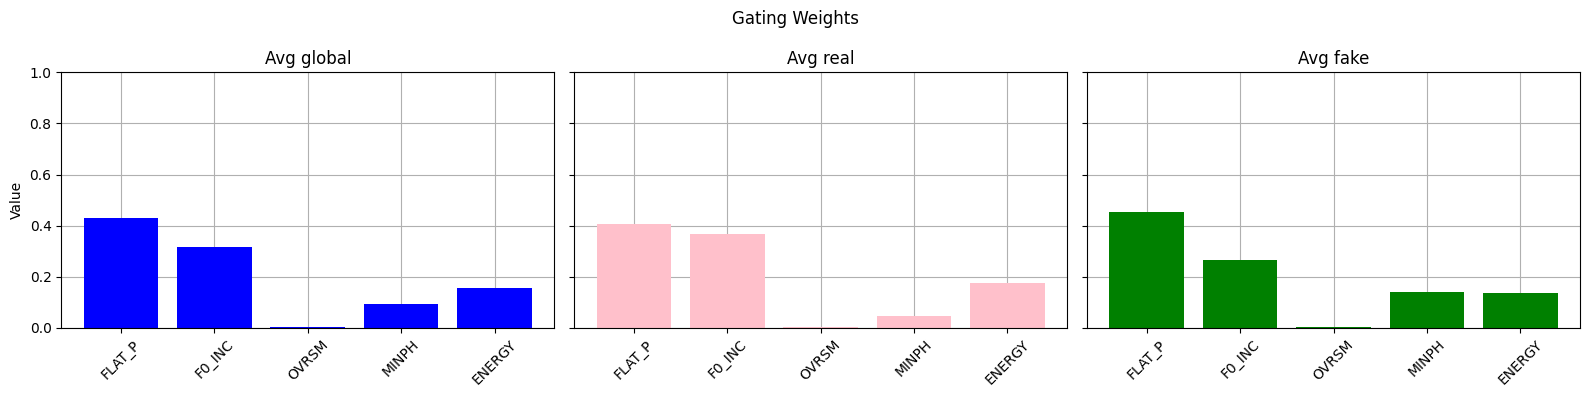

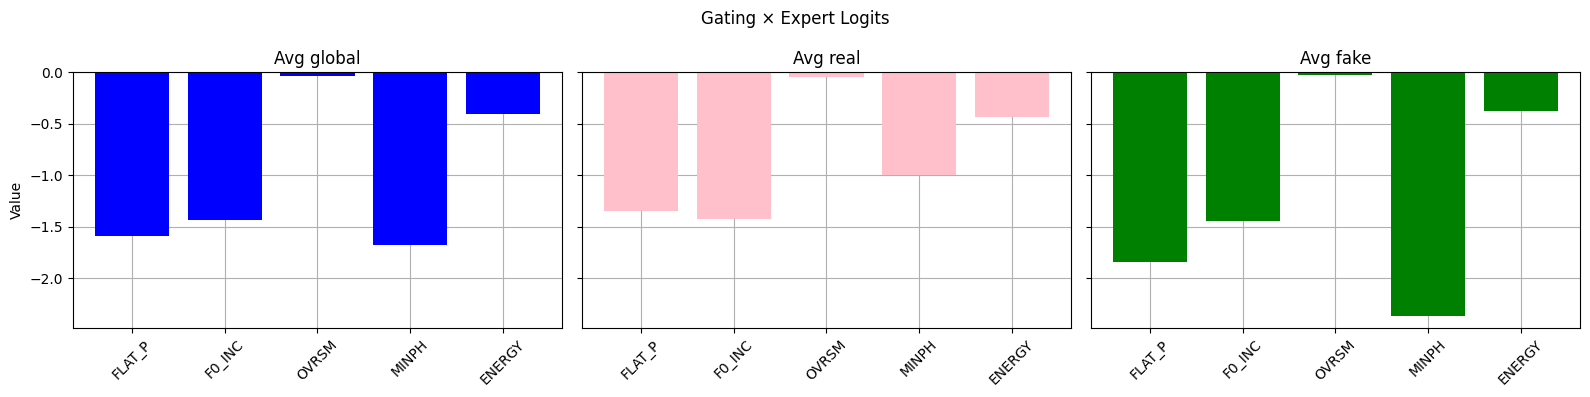

-----------------------------------
A08

Individual Experts' Performance:
AUC: 47.02%, EER: 53.41%
AUC: 40.36%, EER: 57.33%
AUC: 51.24%, EER: 49.40%
AUC: 53.43%, EER: 47.09%
AUC: 65.28%, EER: 38.64%

MoE Performance:
AUC: 43.03%, EER: 55.56%


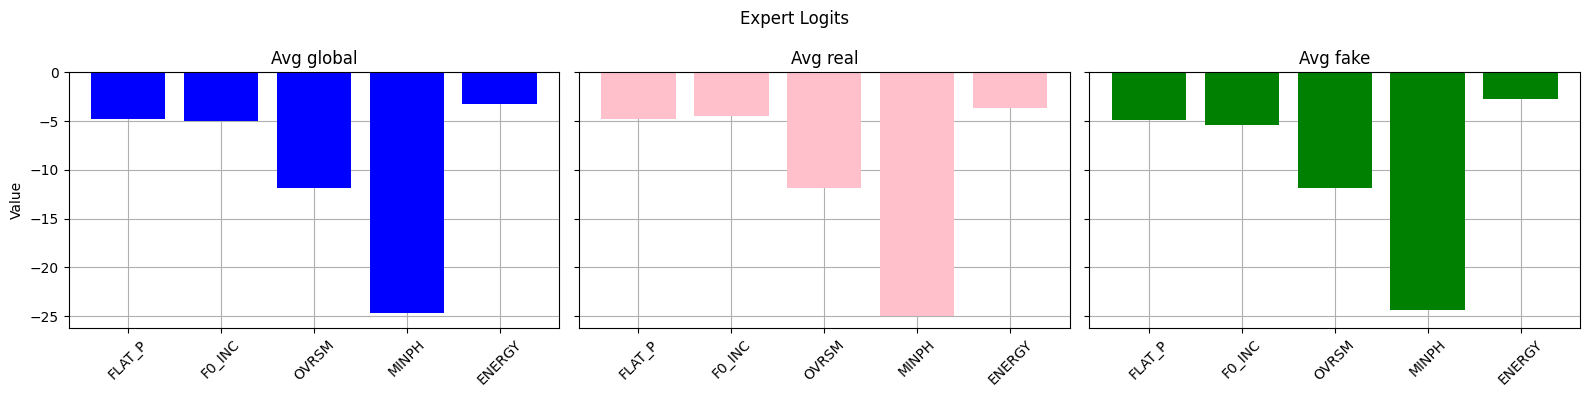

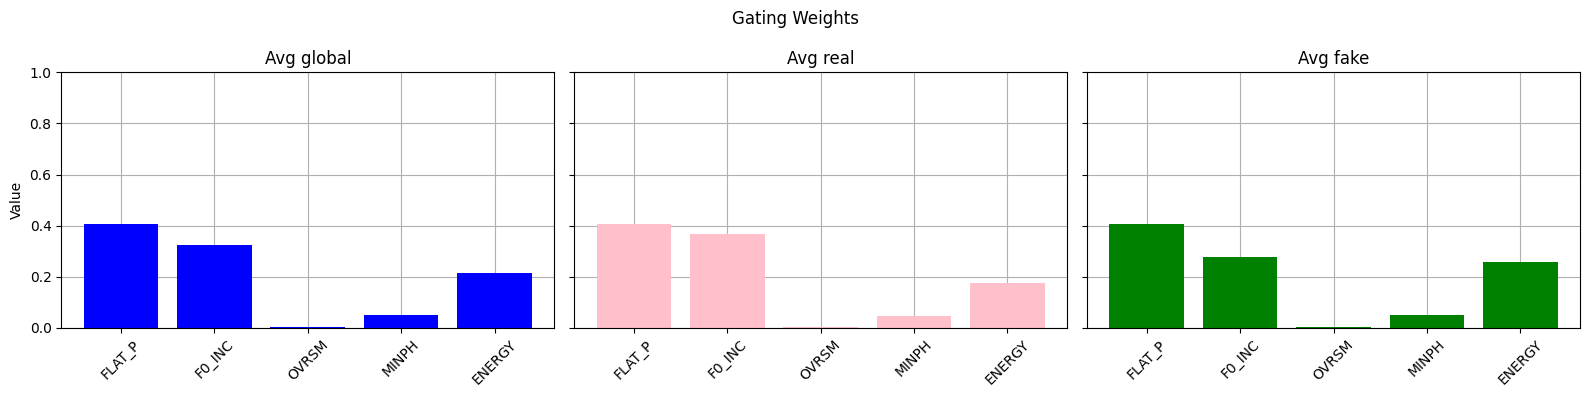

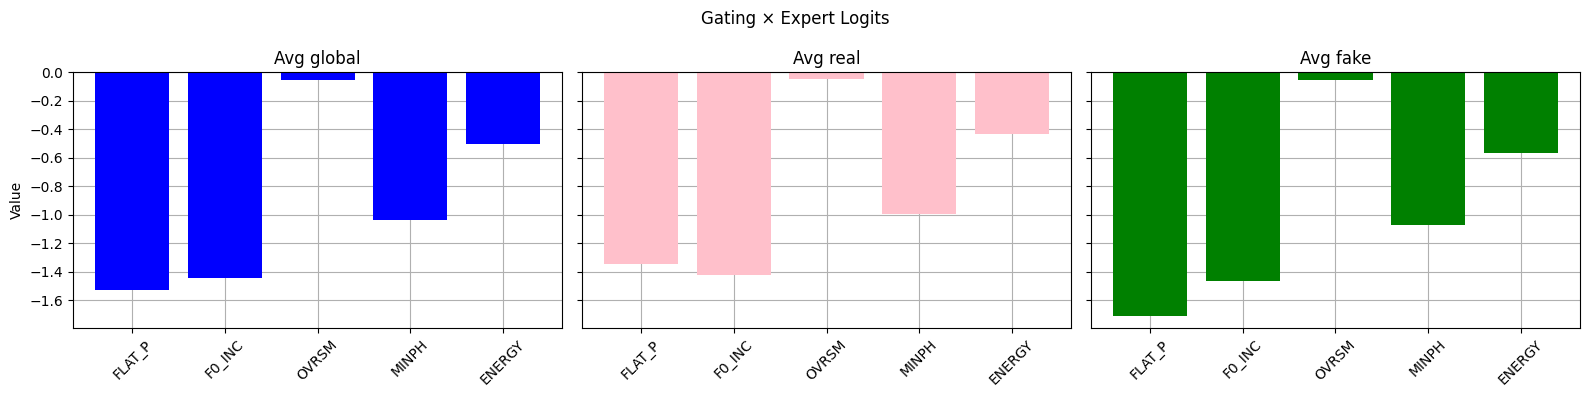

-----------------------------------
A09

Individual Experts' Performance:
AUC: 45.60%, EER: 54.52%
AUC: 44.26%, EER: 54.90%
AUC: 48.97%, EER: 51.20%
AUC: 60.52%, EER: 41.80%
AUC: 16.44%, EER: 77.31%

MoE Performance:
AUC: 33.13%, EER: 62.85%


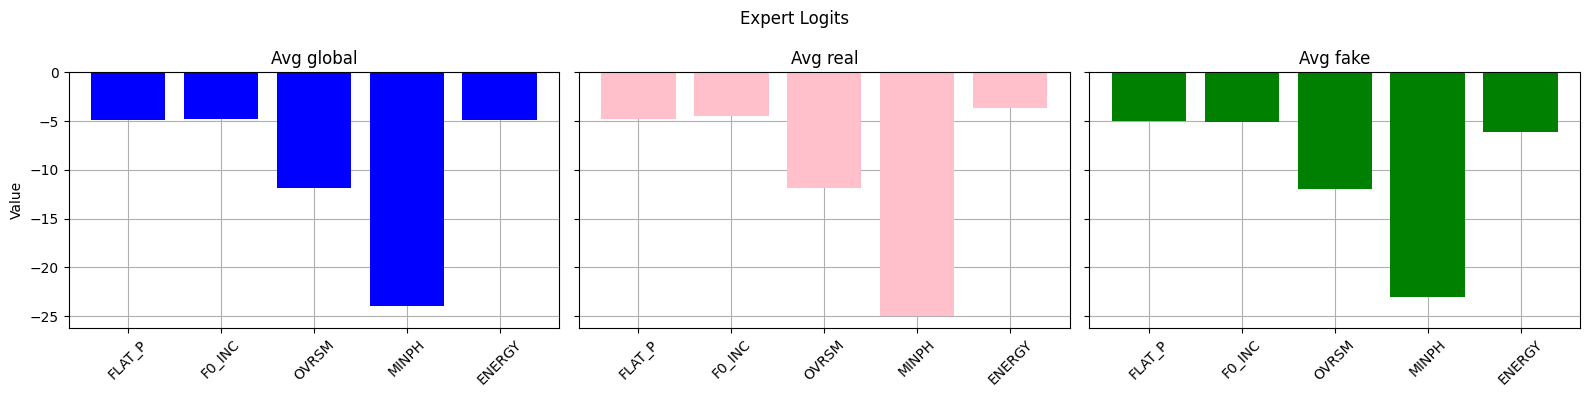

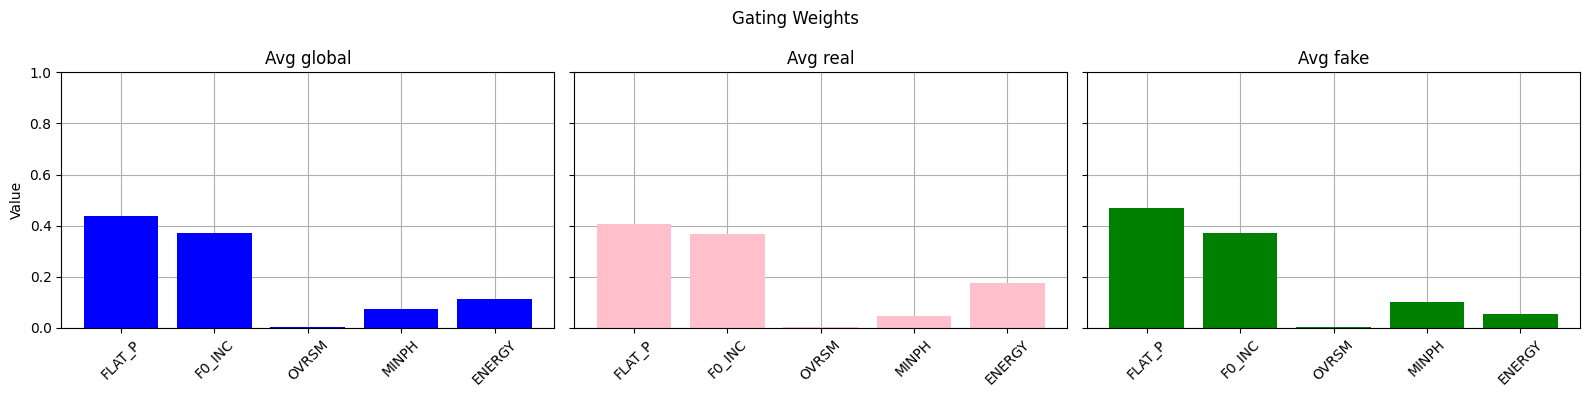

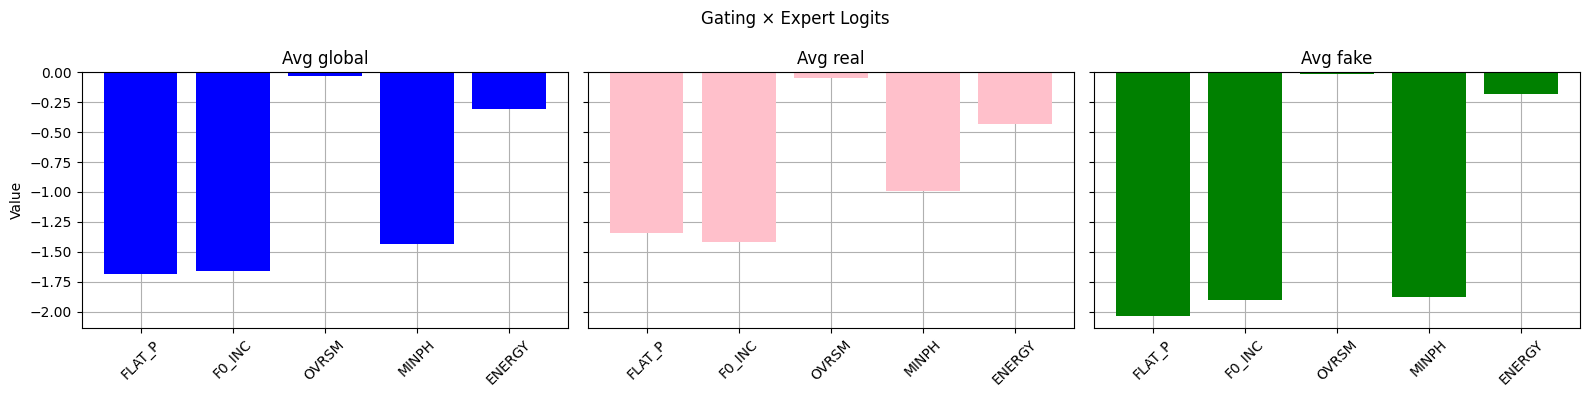

-----------------------------------
A10

Individual Experts' Performance:
AUC: 46.63%, EER: 53.82%
AUC: 45.12%, EER: 53.70%
AUC: 46.83%, EER: 52.00%
AUC: 62.16%, EER: 41.40%
AUC: 15.62%, EER: 78.92%

MoE Performance:
AUC: 33.04%, EER: 63.76%


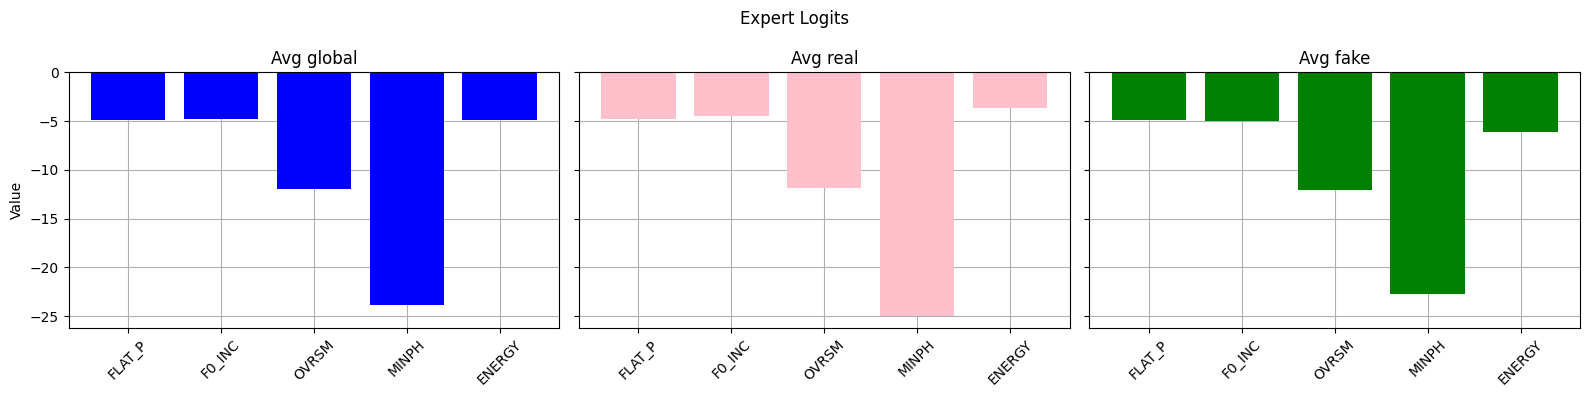

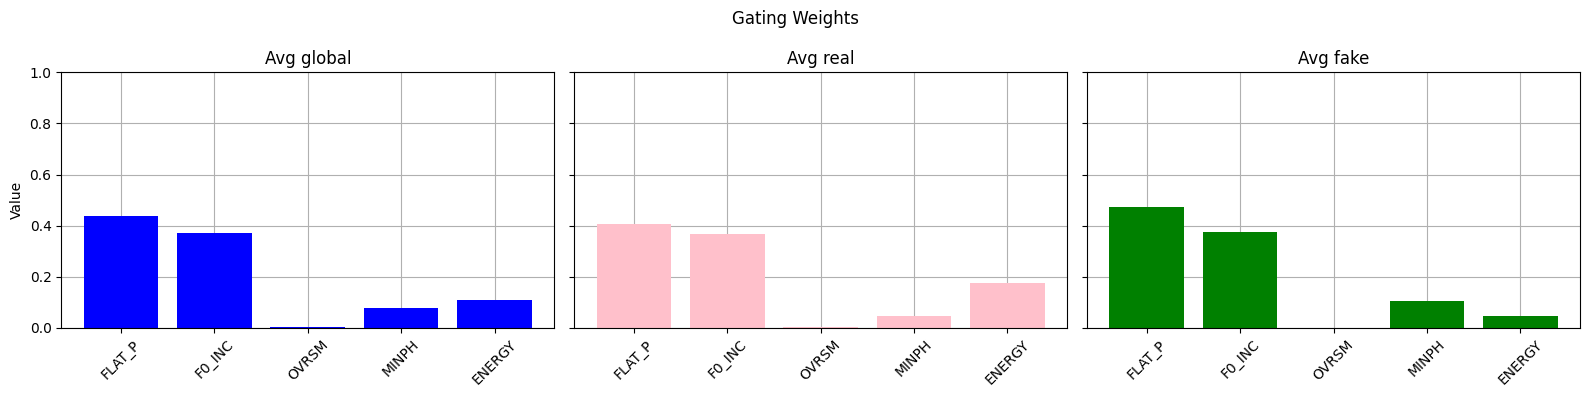

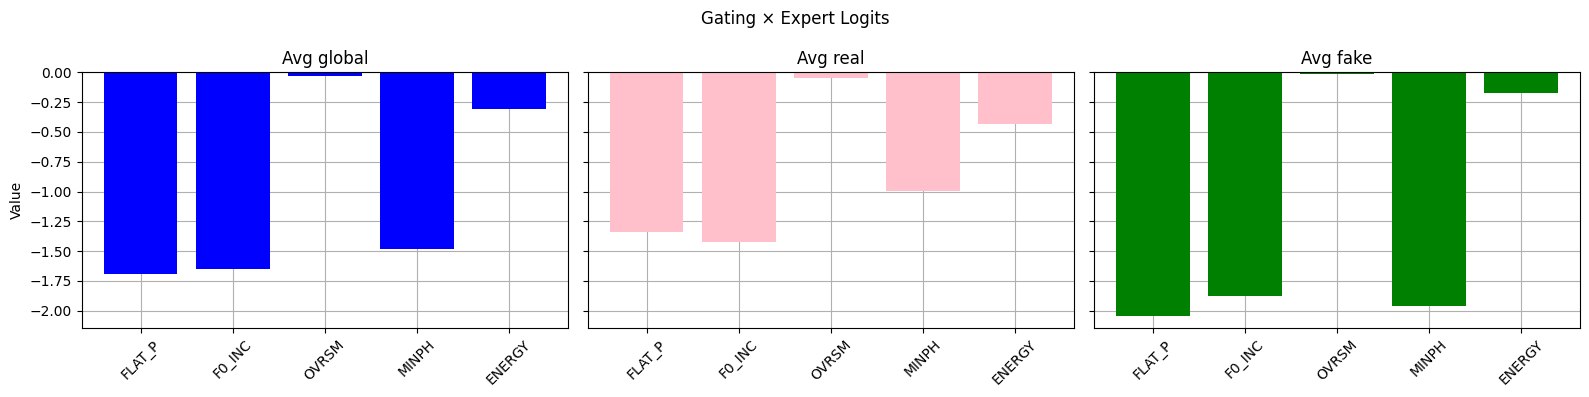

-----------------------------------
A11

Individual Experts' Performance:
AUC: 52.49%, EER: 48.97%
AUC: 54.01%, EER: 47.13%
AUC: 47.77%, EER: 51.61%
AUC: 32.69%, EER: 62.11%
AUC: 84.00%, EER: 25.77%

MoE Performance:
AUC: 77.82%, EER: 29.32%


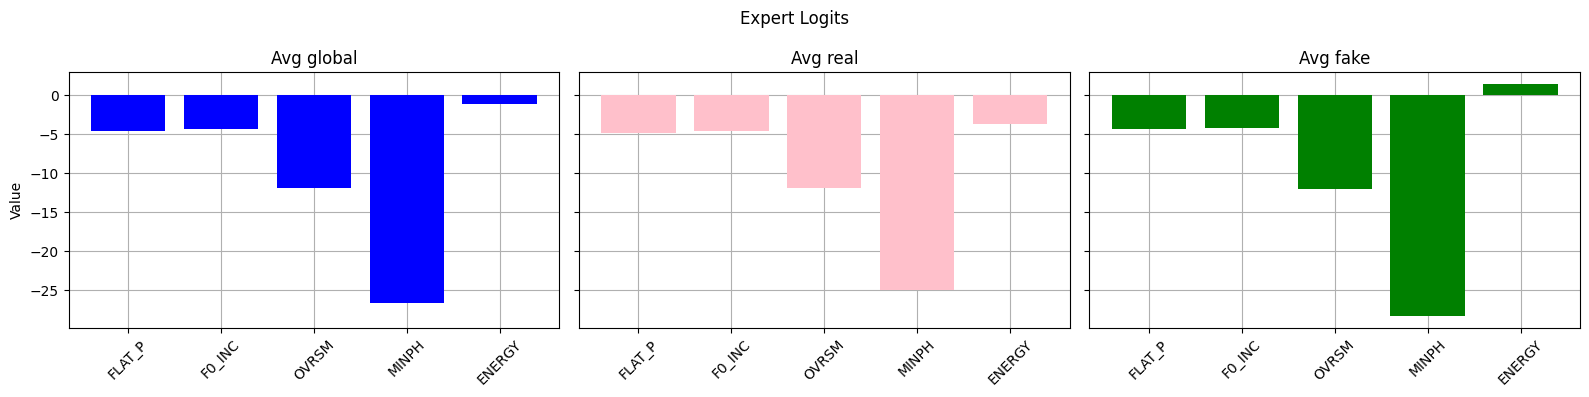

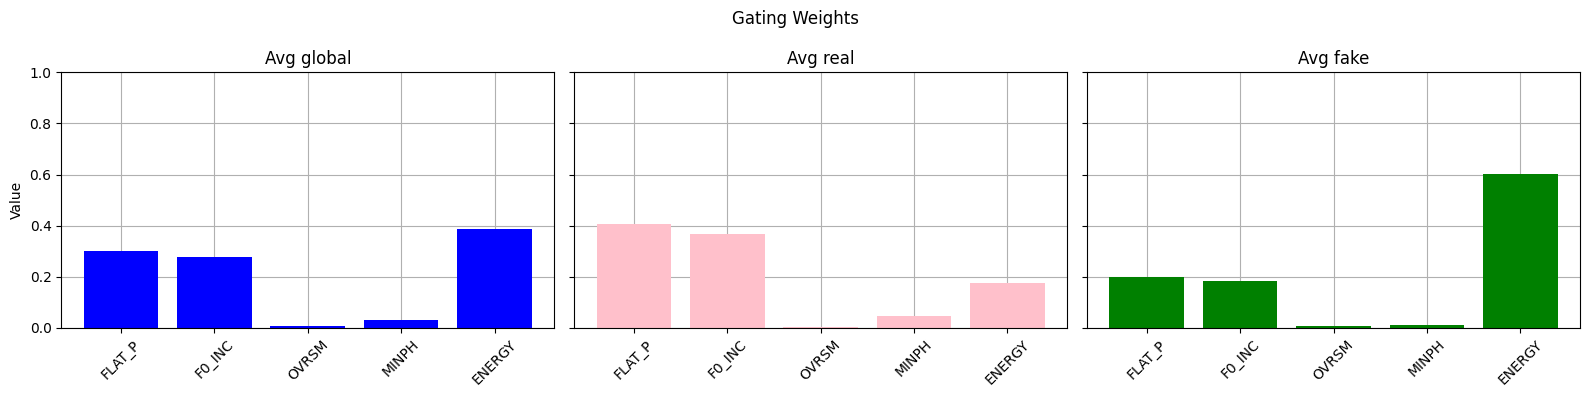

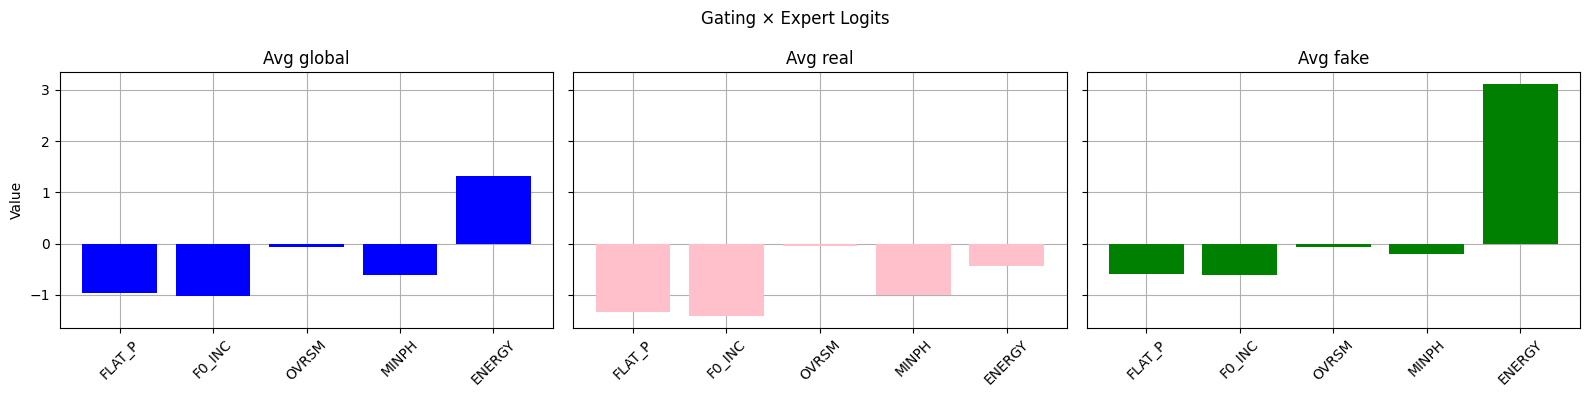

-----------------------------------
A12

Individual Experts' Performance:
AUC: 67.74%, EER: 36.97%
AUC: 92.70%, EER: 14.93%
AUC: 43.14%, EER: 55.01%
AUC: 17.87%, EER: 74.55%
AUC: 89.37%, EER: 17.43%

MoE Performance:
AUC: 92.94%, EER: 14.26%


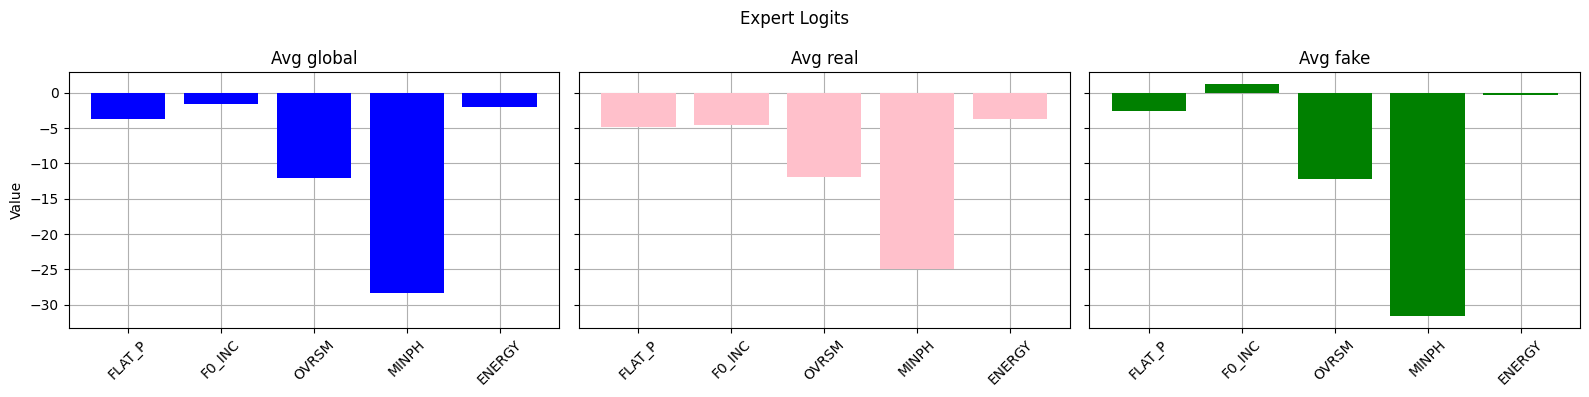

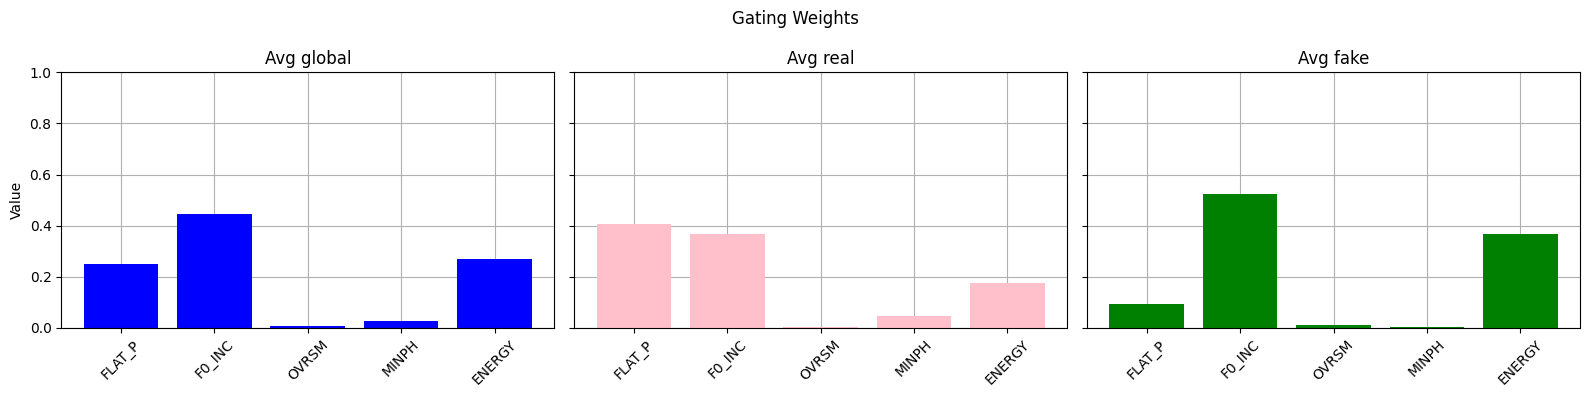

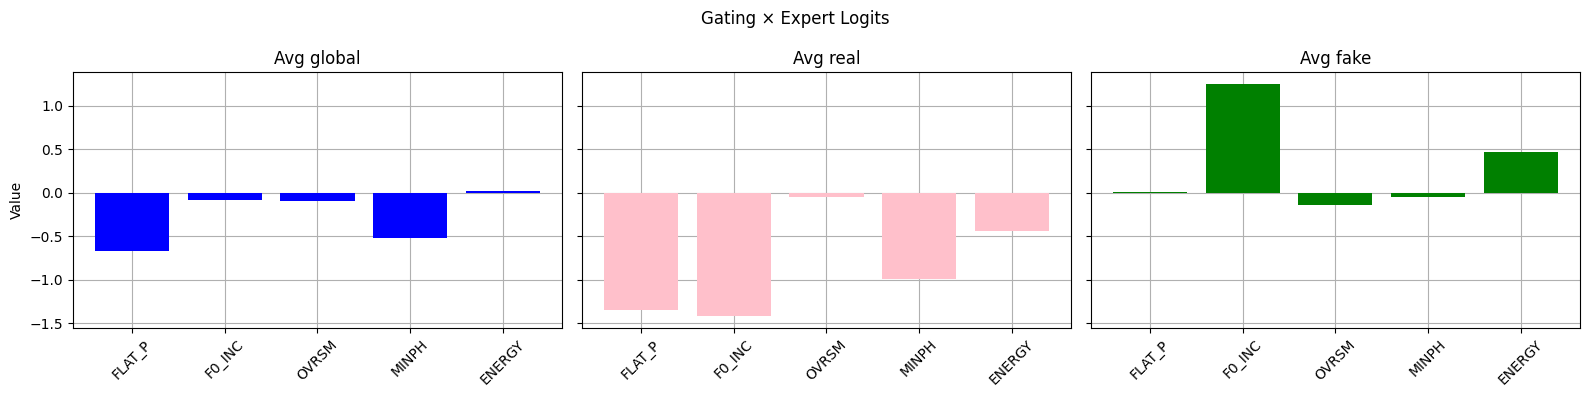

-----------------------------------
A14

Individual Experts' Performance:
AUC: 76.92%, EER: 28.80%
AUC: 84.84%, EER: 24.00%
AUC: 45.97%, EER: 54.12%
AUC: 50.02%, EER: 49.60%
AUC: 90.70%, EER: 16.67%

MoE Performance:
AUC: 84.74%, EER: 22.40%


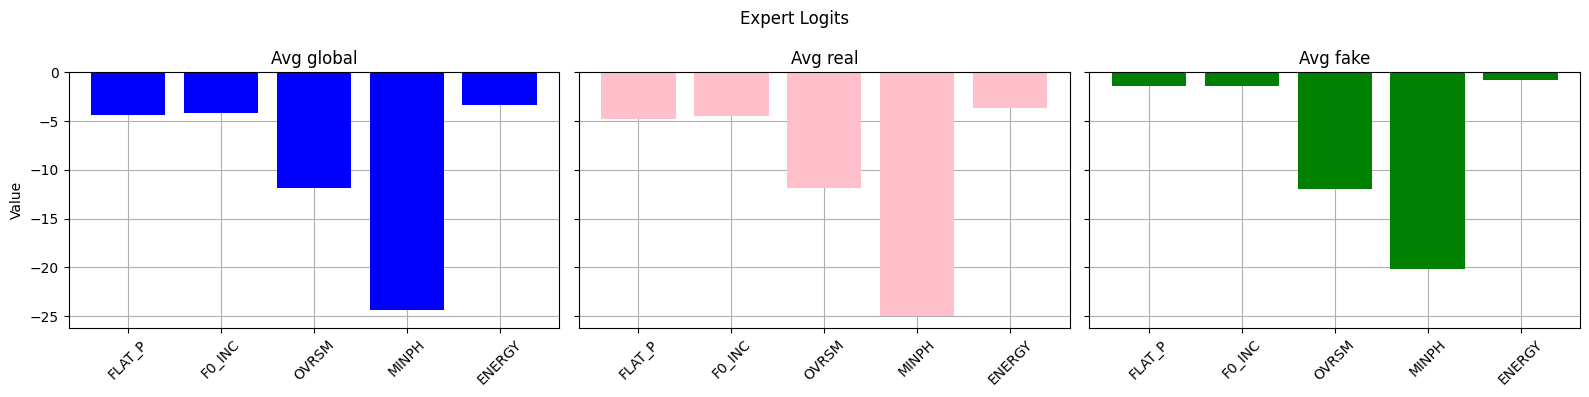

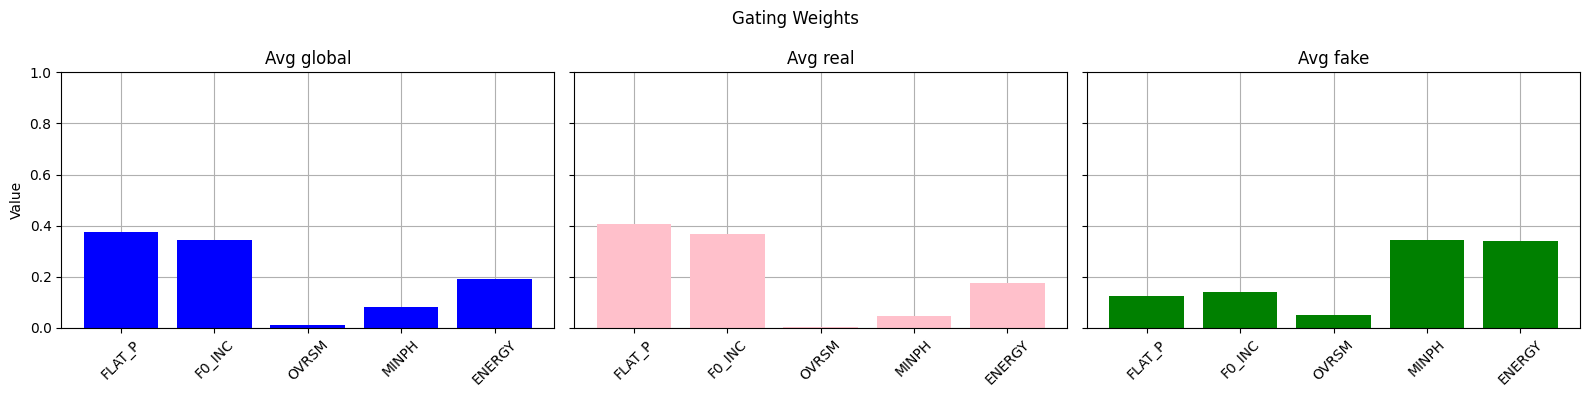

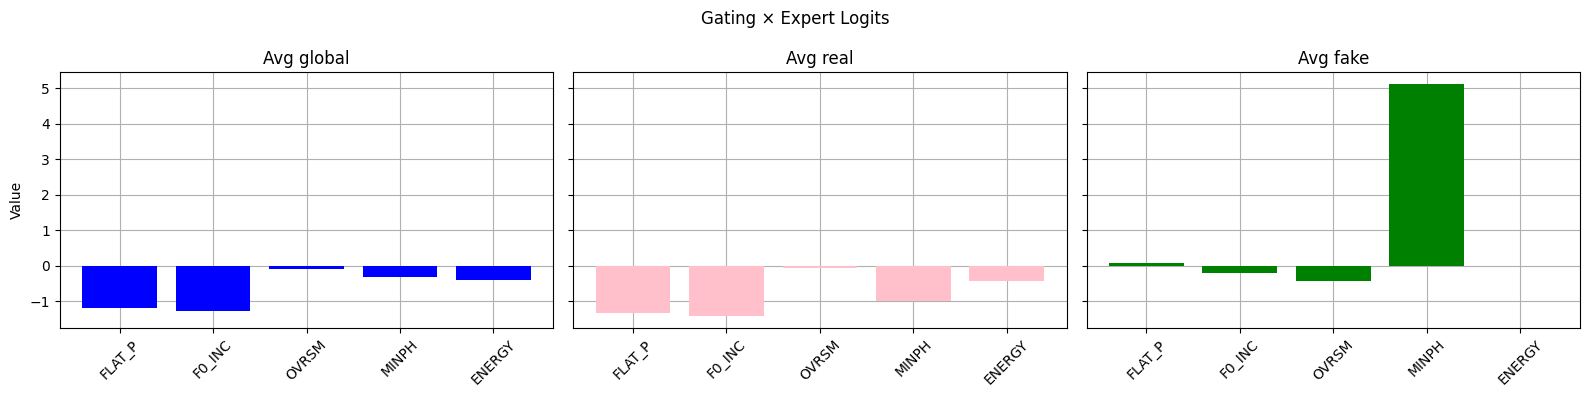

-----------------------------------


In [5]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A14']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/asv5/TargetCheck/{g}"
    model_name = "asv5_frozen_5_exp_linear_comb"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'ENERGY']
    compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, distr=False, plot=True)
    print("-----------------------------------")